Picutures are taken from here

https://github.com/Dyakonov/DL/blob/master/2022/DL_3NLP_02texts_202203a.pdf

https://github.com/Dyakonov/DL/blob/master/2022/DL_3NLP_04transformer_202204a.pdf

https://github.com/Dyakonov/DL/blob/master/2022/DL_3NLP_06languagemodel_202204a.pdf

https://github.com/Dyakonov/DL/blob/master/2022/DL_3NLP_05transformer++_202209a.pdf

# seq2seq


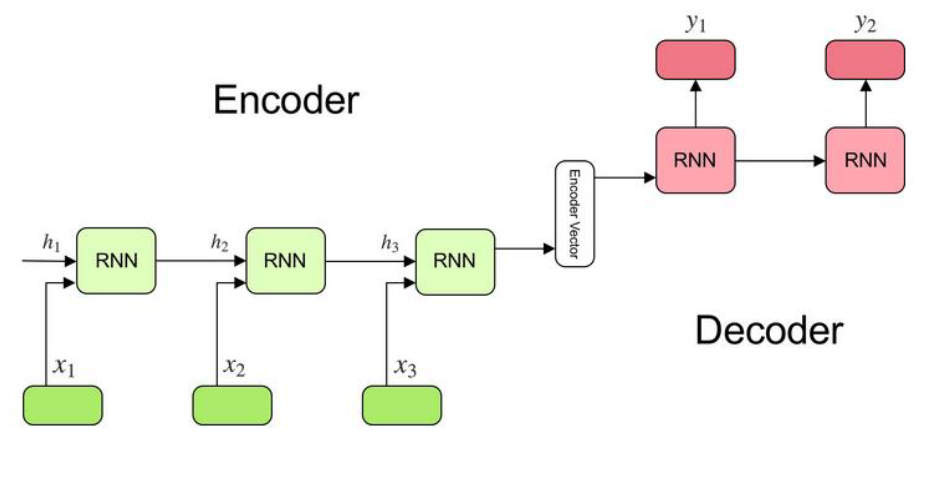

- mutlilayer LSTM
- encoder - decoder architechture
- encoder: input -> vector
- decoder: vector -> target
- both encoder and decoder are LSTM with different parameters
- inverting of input order increases translation quality (because it creates short-term dependencies: first source words end up close to first target words → easier gradient flow / optimization)
- ensembles are good too
- decoder is autoregressive: input at step t is y_{t-1} (starts with <BOS>, stops at <EOS>)
- objective: maximize log p(y|x) = Σ log p(y_t | y_<t, x)
- training uses **teacher forcing** (send to model ground-truth y_{t-1} as input, not the x_{t-1} that model predicted on previous step) → exposure bias at inference
- encoder vector = final hidden & cell states of every LSTM layer, used to init the decoder
- inference: beam search (argmax over all sequences is intractable, greedy search (like in modern LLMs) doesn't give optimal result in that case)

### Inner representation of sentences (for seq2seq)

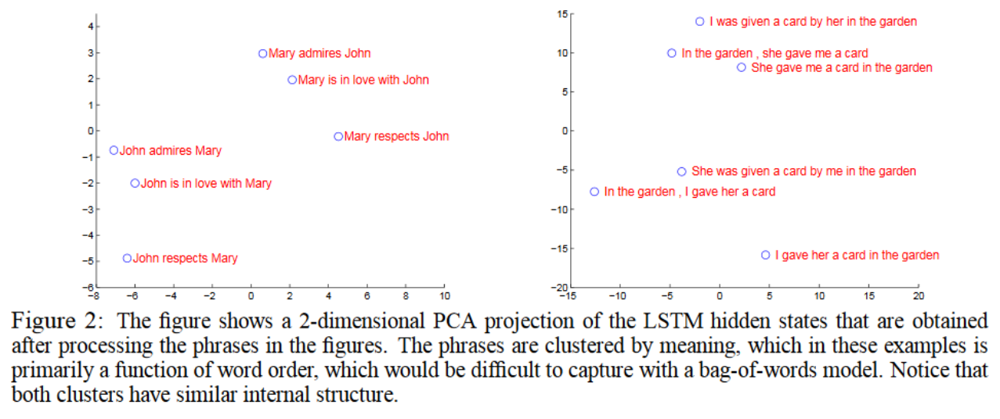

# Attention

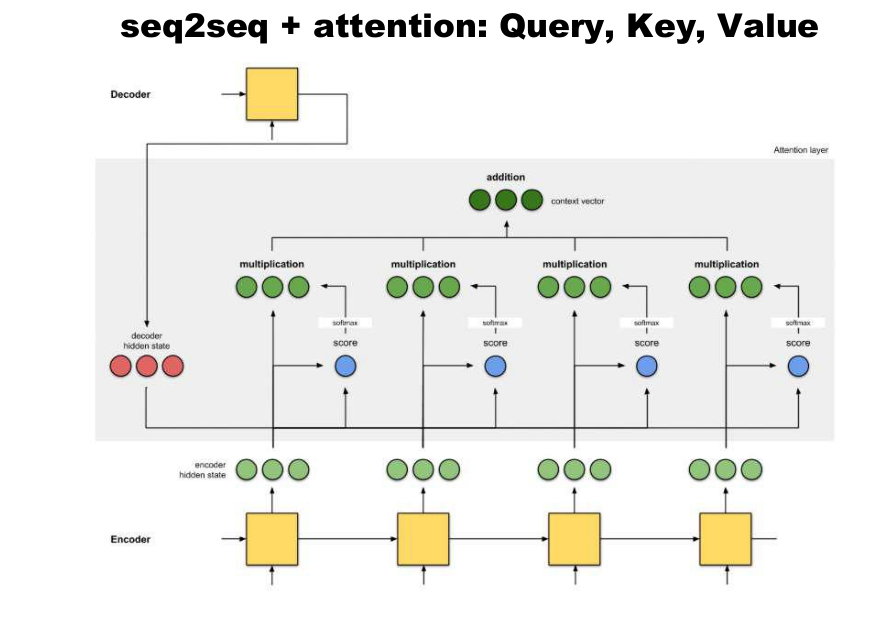

Mechanism that lets decoder to "look" at previous/next encoder states to make more precise decision

### Key-Query-Value paradigm

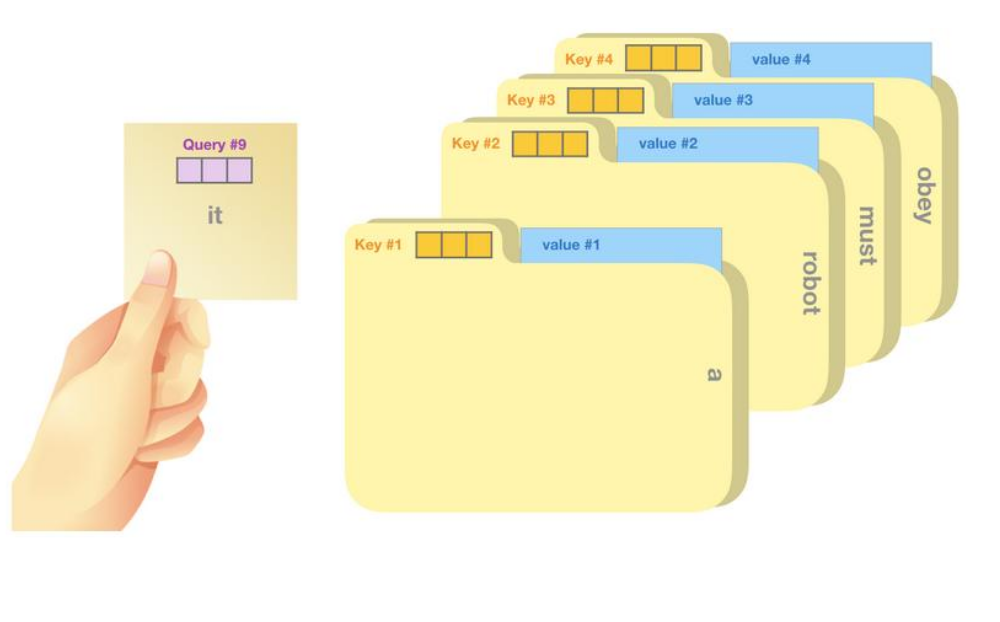

### Attention mechanism

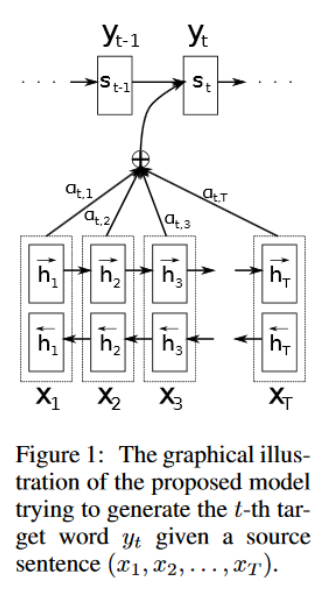



x<sub>1</sub>, x<sub>2</sub>, ..., x<sub>t</sub> - input sentense tokens 

h<sub>1</sub>, h<sub>2</sub>, ..., h<sub>t</sub> - encoder hidden states (**key**)

y<sub>1</sub>, y<sub>2</sub>, ..., x<sub>t</sub> - output sentense

s<sub>1</sub>, s<sub>2</sub>, ..., s<sub>t</sub> - decoder hidden states (**query**)



e<sub>i</sub> = a(h<sub>i</sub>, s<sub>t</sub>) - measure of similarity between h<sub>i</sub> and s<sub>t</sub>

$\alpha$<sub>i</sub> - softmax of e<sub>i</sub>

c<sub>t</sub> - context vector (concatenate all h with corresponding $\alpha$) (**value**)

y<sub>t</sub> = o(s<sub>t</sub> + c<sub>t</sub>); o - decoder output layer, "+" - concatenation

### How to measure similarity between h<sub>i</sub> and s<sub>i</sub>

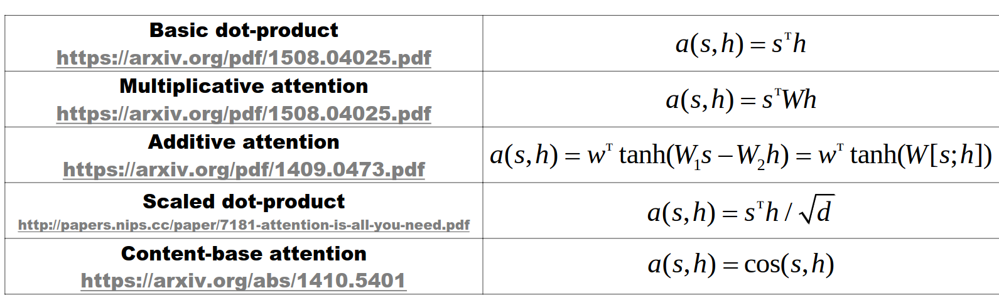

d - dimensiality of vector

### Attention mechanism one more scheme

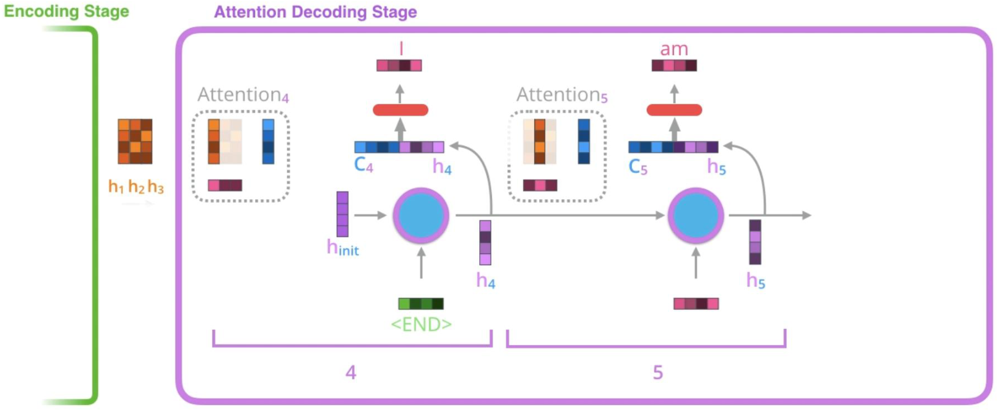

### Self-attention

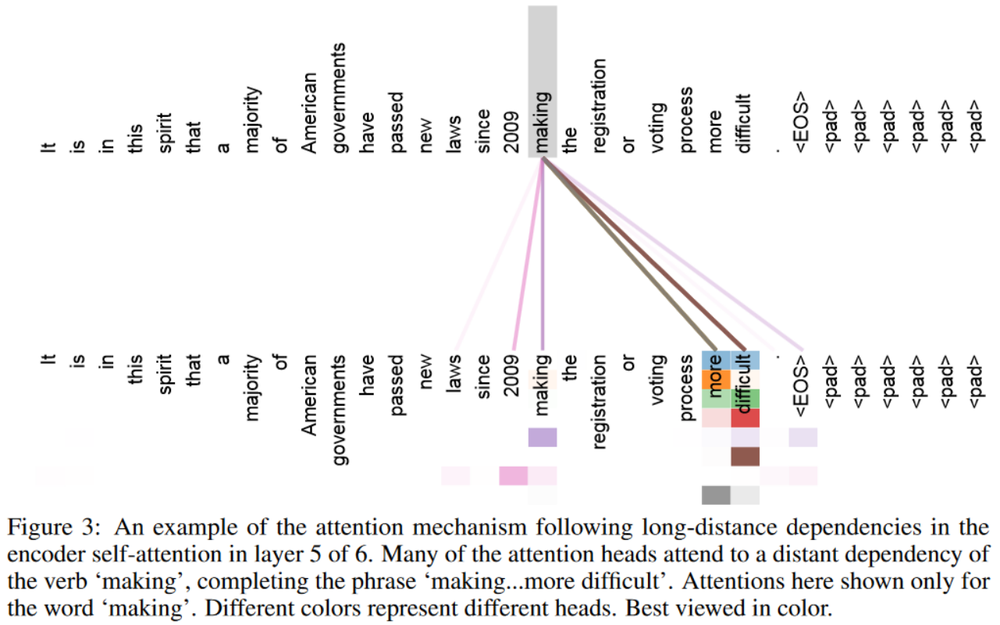

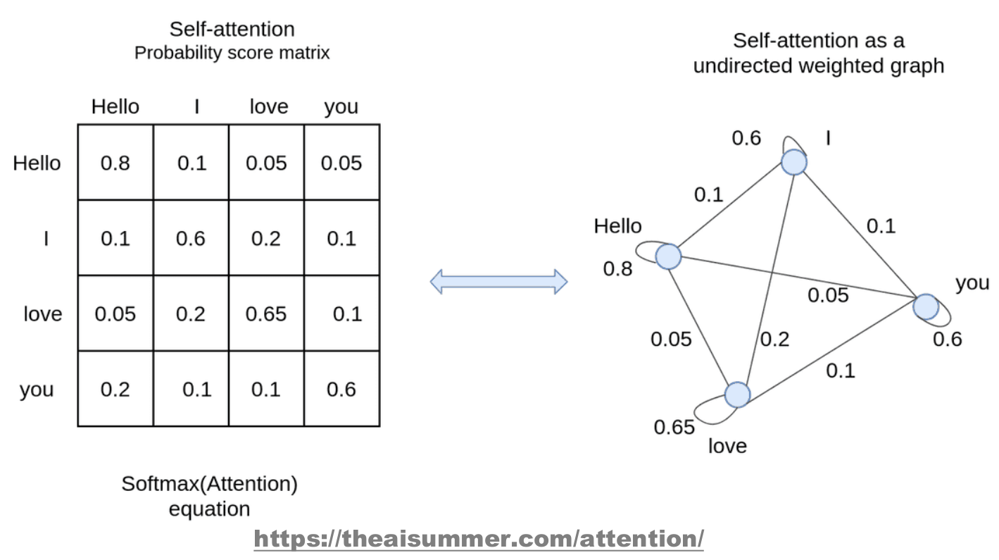

### Attention formula

Matrix V<sub>d x s</sub> contains keys

Matrix K<sub>d x s</sub> contains keys

q - query vector

d - dimensiality

s - number of objects

Dimensialities d of matrices K and V can be different

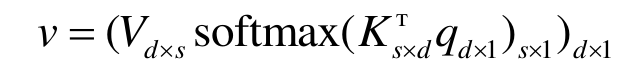

We take our query vector and multiply transposed key matrix K on it, i.e. we measure similarity between query vector and every key in key matrix. Then we use softmax to find the key vector that is the most similar to our query. Then we multiply most similar key vector and value matrix V to get our value. 

### Multi-Head Self-Attention

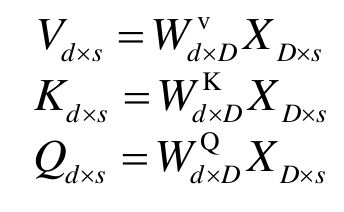

Two more matrices are added:

Matrix X<sub>D x s</sub> contains objects for attention

Matrix Q<sub>d x s</sub> contains keys

Self-atteniton formula (similar to previous). alpha = 1/sqrt(d), it's used for calculation stability.

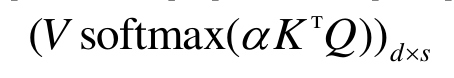

I.e. we have send s queries (with dimensiality D) to self-attention and as result get s values (with dimensiality d). Structure that performs these operations is called head.

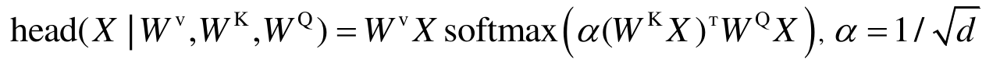

Transformer has multiple heads (e.g. 8). One head differs from another by a set of matrices W<sup>V</sup>, W<sup>K</sup>, W<sup>Q</sup>

Than results from all head are concatenated and multiplied with matrix W<sub>D x 8d</sub> 

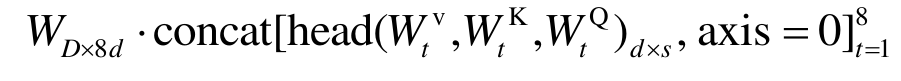

As a result we get attention matrix A<sub>D x s</sub> that has the same dimensiality as object matrix X<sub>D x s</sub>

### Attention alignment

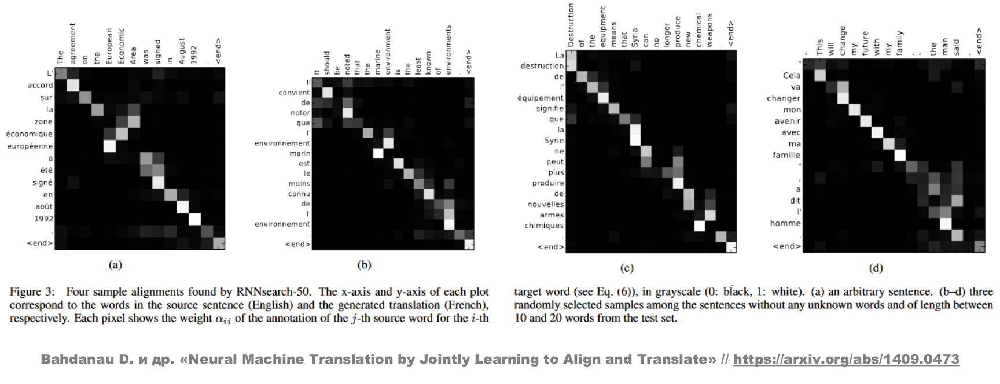

### Attention helps to solve narrow gap problem (quality deterioration for long sentences)

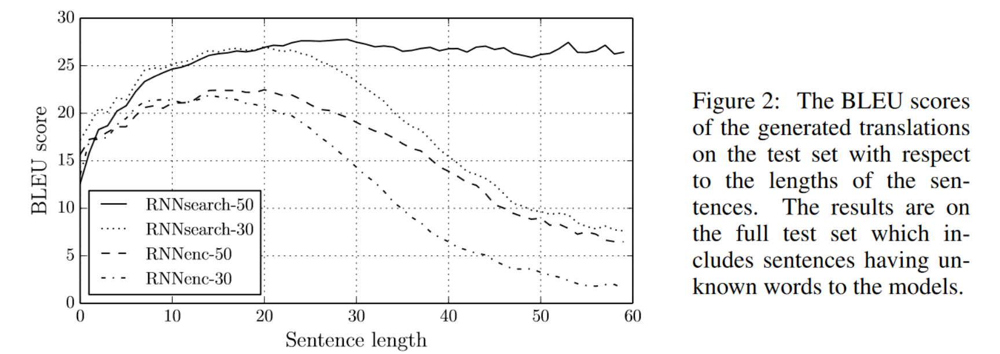

### seq2seq vs attention

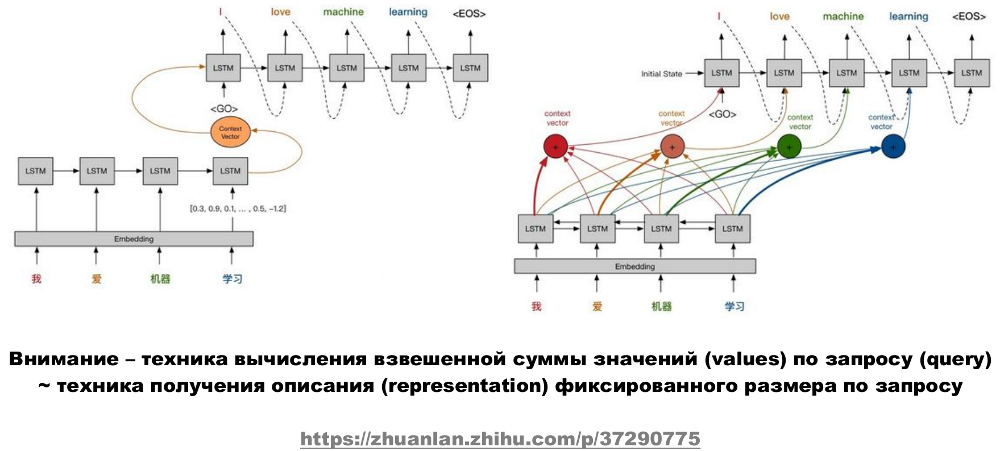

### Attention advantages

- increase translation quality
- solves narrow gap problem
- interpetable
- solves problem of vanishing gradients
- "free" alignment (correct word order) in translation (see attention alignment above)

### Attention types

- self-attention / intra-attention (attention to the different positions of the same input sequence)
- global / soft (attention to the whole output)
- local / hard (attention to the part of the output)

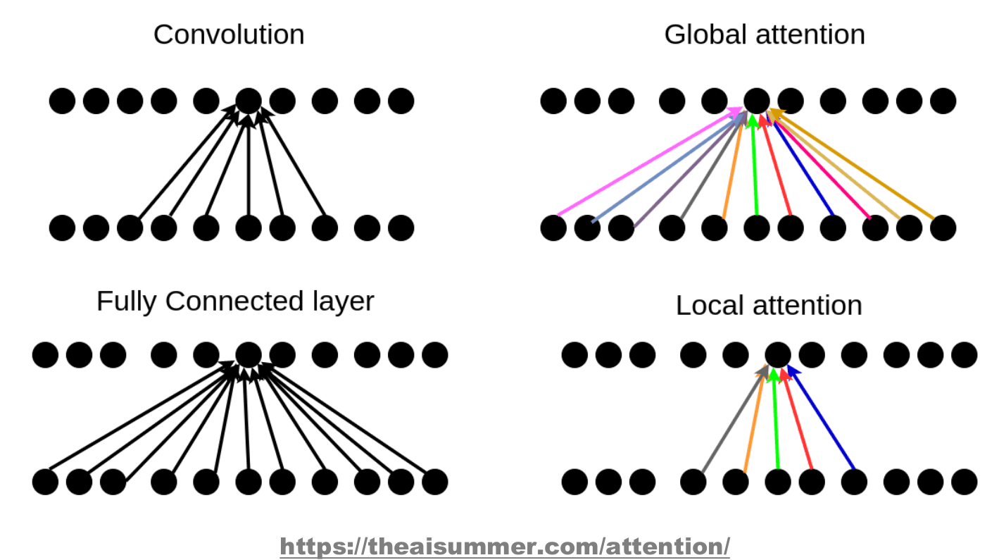

### Local attention vs global attention

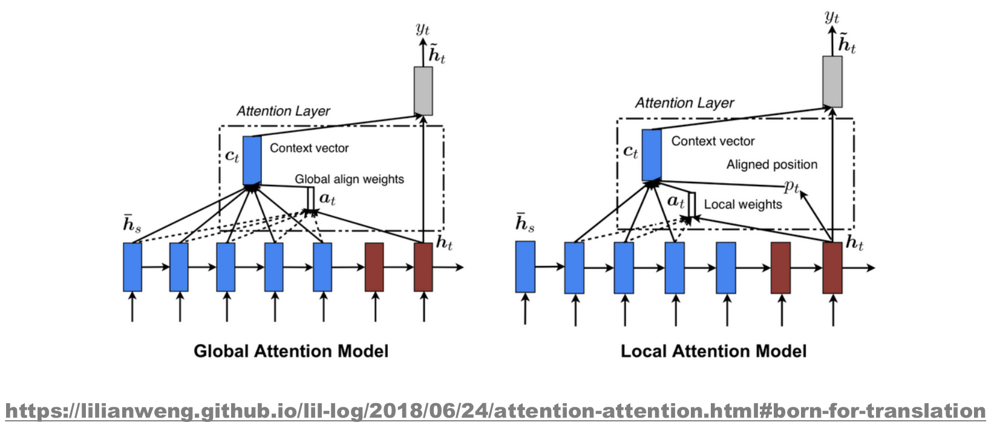

### Conclusion

- RNN - natural architecture for short sequences, no parallelization
- 1D-conv - bad for long sequences + parallelization
- self-attention - good for long sequences + parallelization but consumes a lot of memory

### More about attention here

https://lilianweng.github.io/lil-log/2018/06/24/attention-attention.html


# Transformers

Main idea: parallelized attention

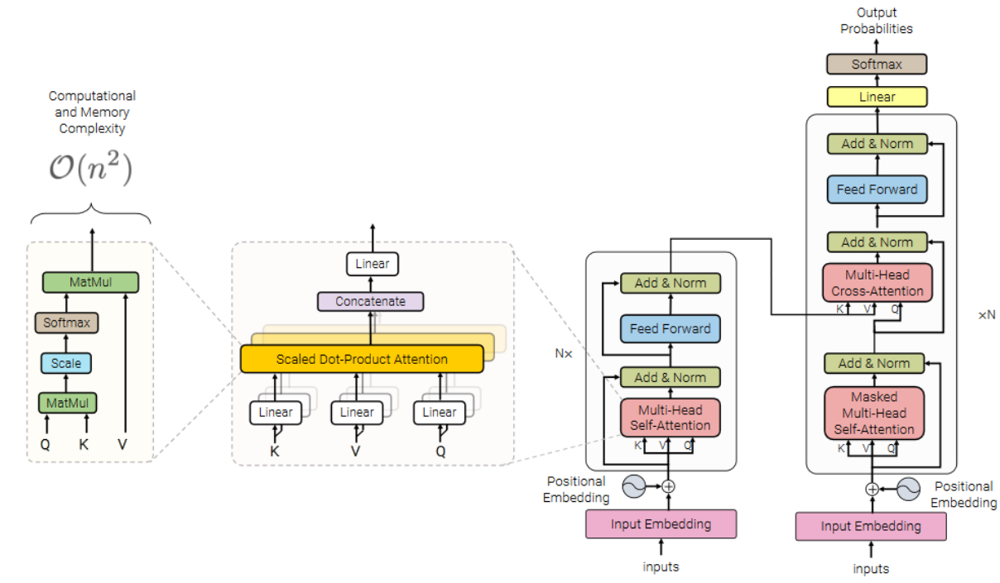

Left part is encoder, right part - decoder.

During training process we use both *X* and *y*. This is known as "teacher forcing". The "teacher" signal is "forcing" the model to behave as though it got the answer right. Teacher forcing was originally developed for RNNs. It's more effective for transformers because the right teaching signal for our network is the target data, which we have access to during training, whereas in an RNN the best teaching signal would be the target embedding vector, which we do not know.

During inference, when we don't have access to *y*, we revert to the autoregressive task.

This "trick" allows Transformer architectures to readily scale up models to the parameter count [required to make full use of internet-scale datasets](https://arxiv.org/abs/2001.08361).

**Important:** picture is incorrect, decoder uses it's previous inputs *X* and outputs *y* as inputs (outputs *y* are inputs *X* that were shifted right, e.g. *X* is *\<start\> I am fine \<EOS\>* while *y* must be *I am fine \<EOS\>*) during inference. 

### Transformers: main

- transformer is a stacking of transformer blocks (see Self-Attention Block scheme on image above)
- diffrent heads is used for different attentions: e.g. 1st head is used to analyze words adjacent to current word (close context), 2nd is used to look for words that are connected with current word through syntax/semantics, 3rd is used to look for synonims of current word in sentence, etc.
- every next transformer layer returns more and more complex and general token embeddings (like in convolutional networks): on the first layers NN sees connections between words, on the last - "understands" meaning of words and sentences
- tokens at the output of attention block don't change their dimensions
- transformer is non-recurrent model for sequences (if we look at attention block matrices - we will see that their dimensions don't depend on number of objects in sequence, so transformer block can process sequence of any length)
- transformer is a deep model with attention blocks
- last layer is softmax + cross-entropy error

### Transformer: main structure

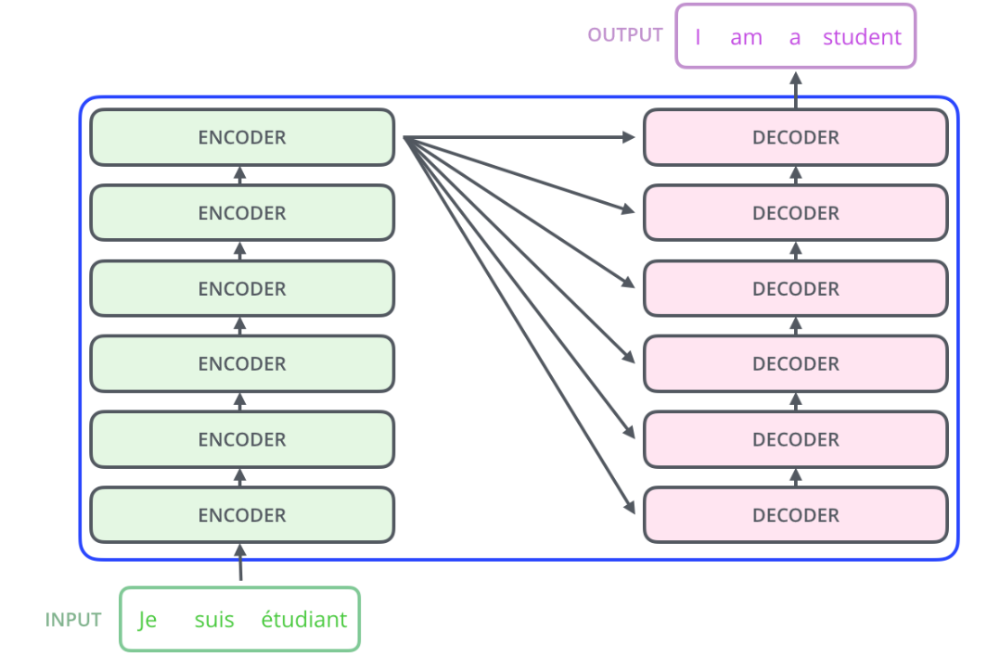

### Endcoder-Decoder structure

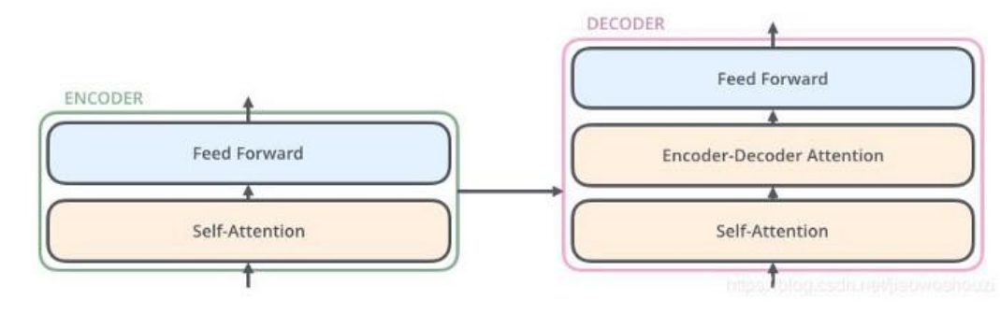

Encoder 
- 1st layer, self-attention: analyze context semantics by looking at whole sentence
- 2nd layer, feed-forward: non-linear feature space transformation

Decoder 
- 1st layer, self-attention: analyze context semantics by looking at whole sentence
- 2nd layer, cross-attention: analyze context semantics by looking at whole sentence in encoder
- 3rd layer, feed-forward: non-linear feature space transformation

### Attention in transformers

Types of attention in transformers

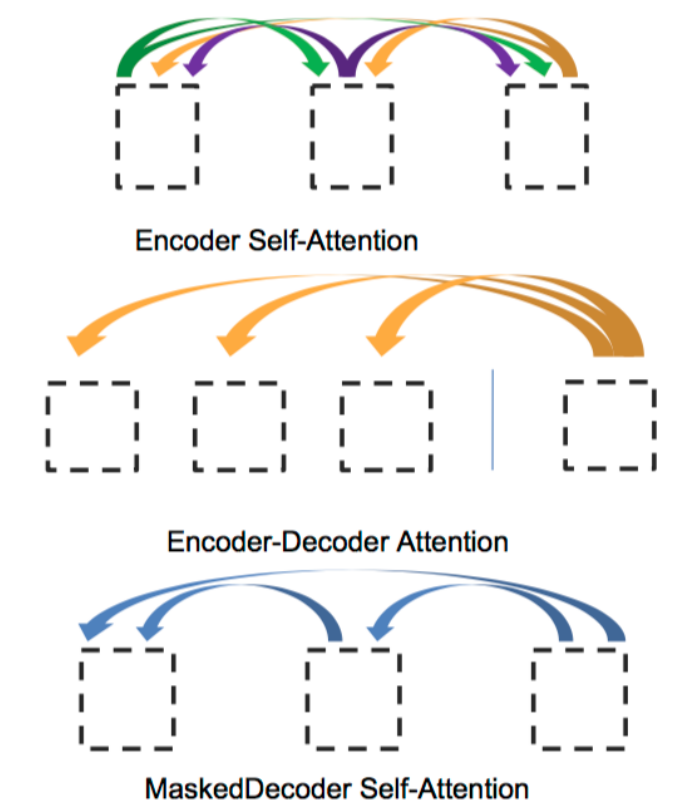

1st attention type is used in encoder, 2nd and 3rd types - in decoder

### Matrices for self-attention

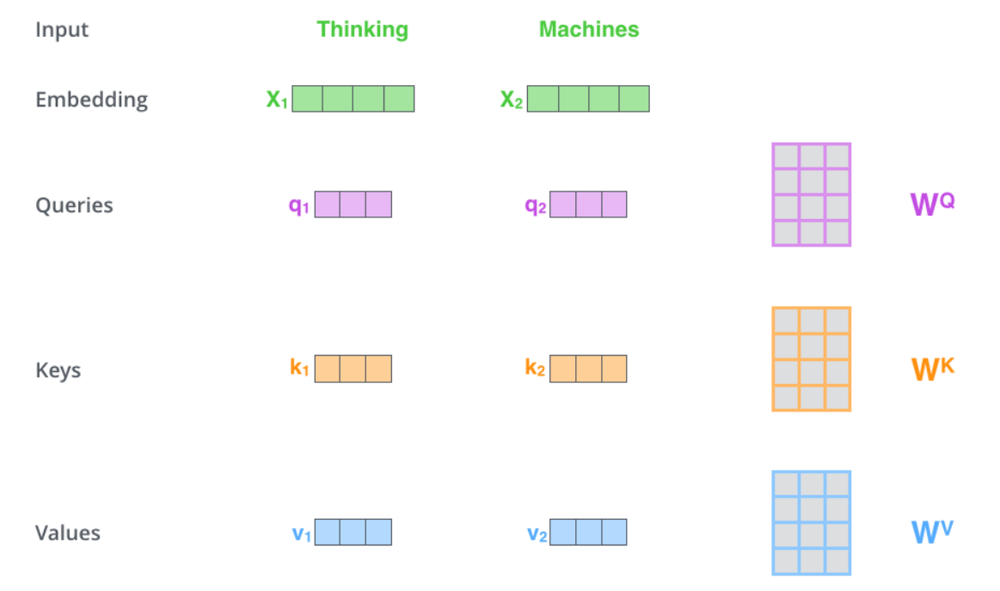

- X<sub>i</sub> dimensiality is 512
- q<sub>i</sub>, k<sub>i</sub>, v<sub>i</sub> dimensialities are 64
- q<sub>i</sub>, k<sub>i</sub> and v<sub>i</sub> are obtained by multiplying input vector X<sub>i</sub> on corresponding matrix



### Self-Attention process

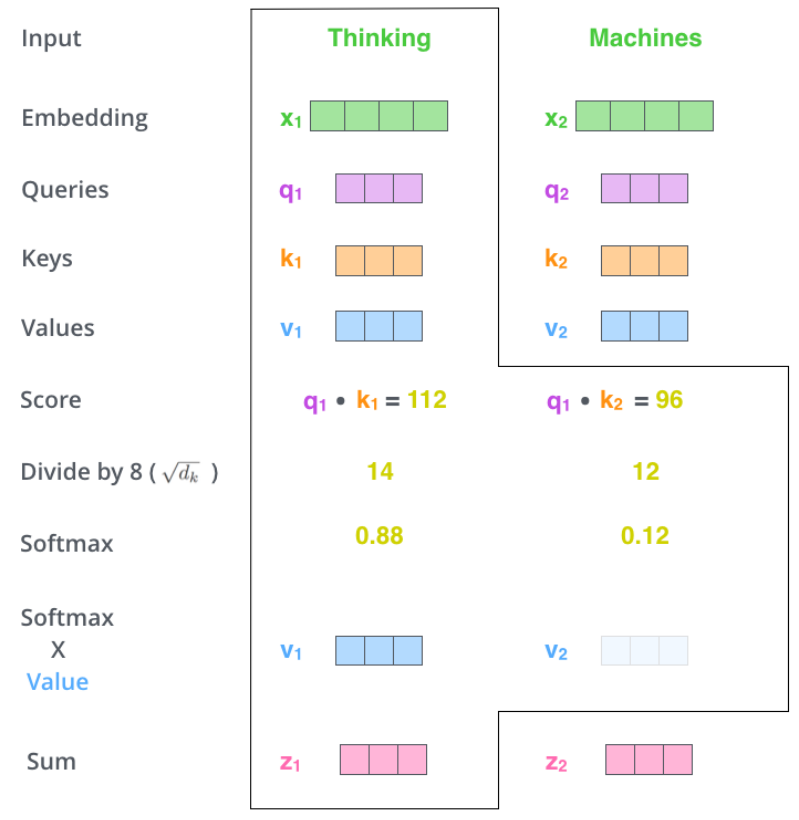

### Self-Atention process: matrix view

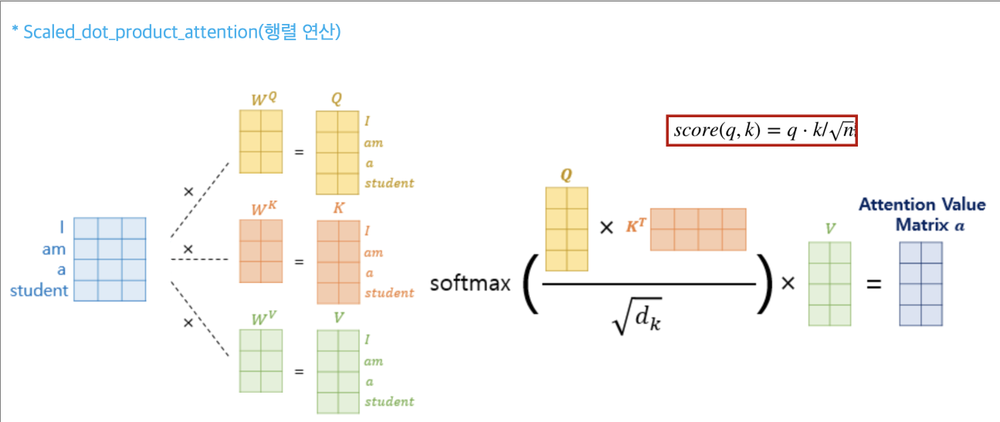

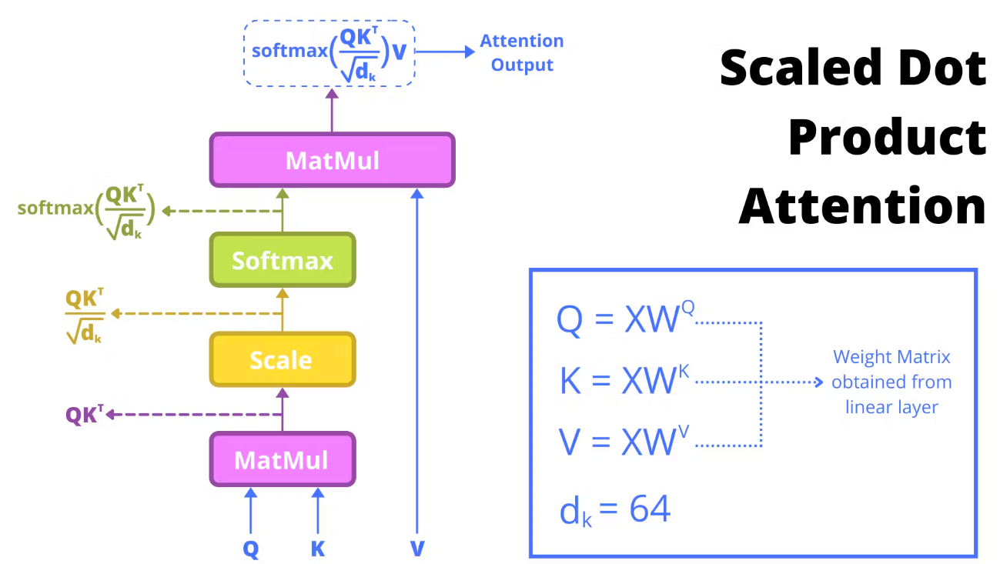

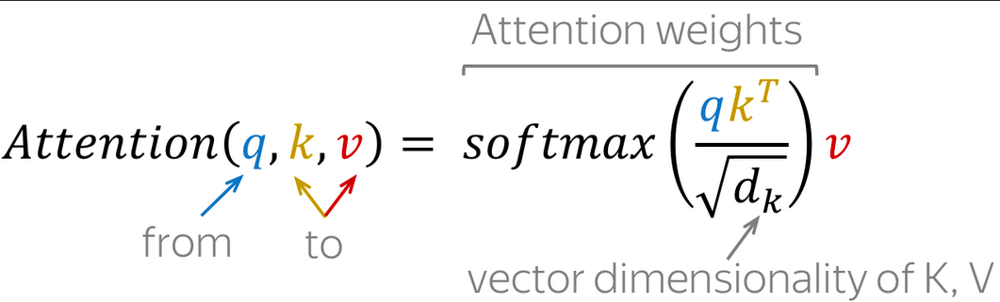

### Mutli-Headed attention: matrix view

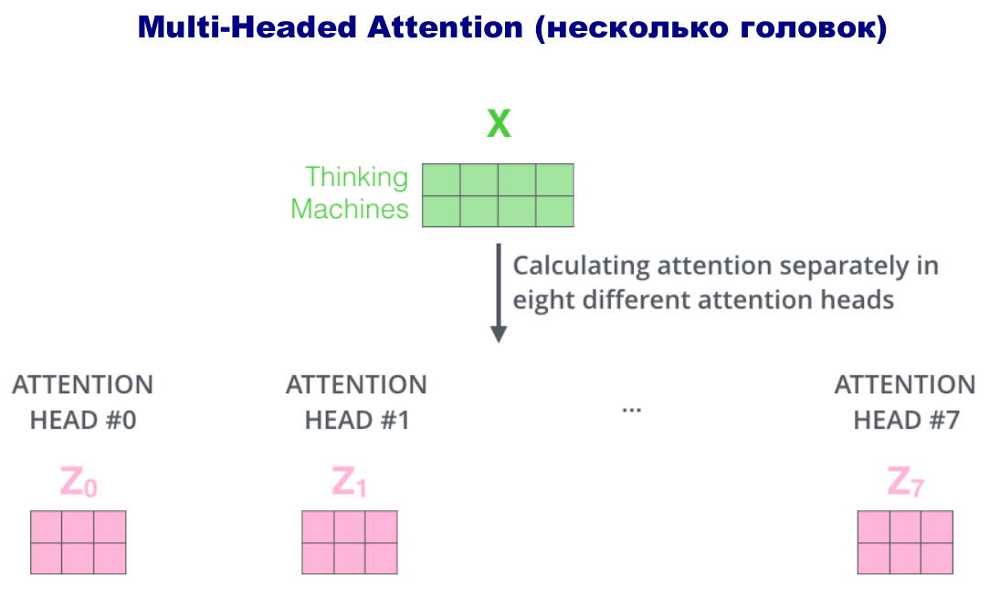

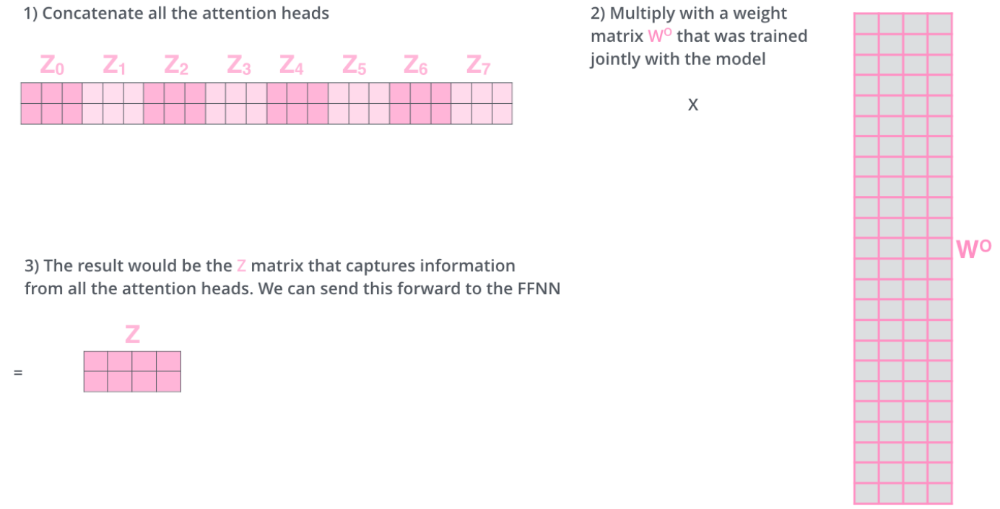

### Multi-Headed Attention: the whole process

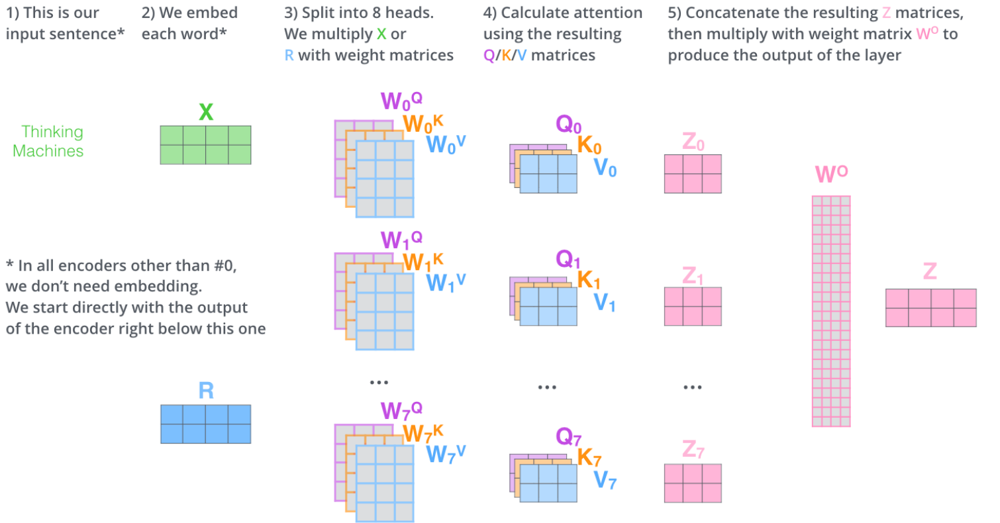

## Encoder

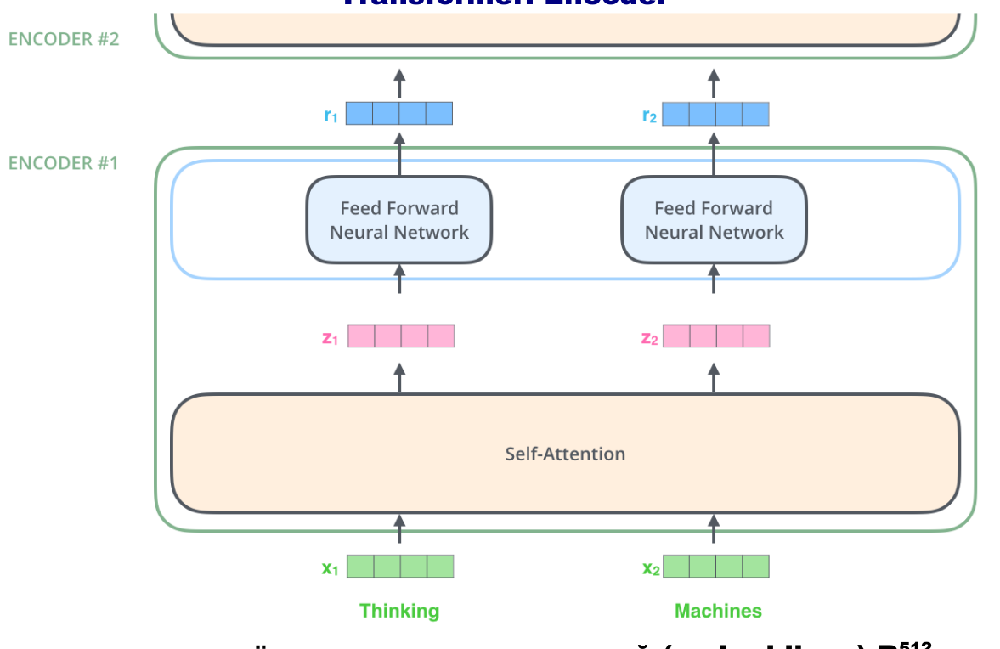

- input dimensiality is 512, output dimensiality is 512 too
- feed-forward NN is the same for any token

### Encoder: Position Encoding/Embedding

Problem: unlike RNN, transformer doesn't know the order of words in sentence, so we need to encode word position before sending it to transformer.

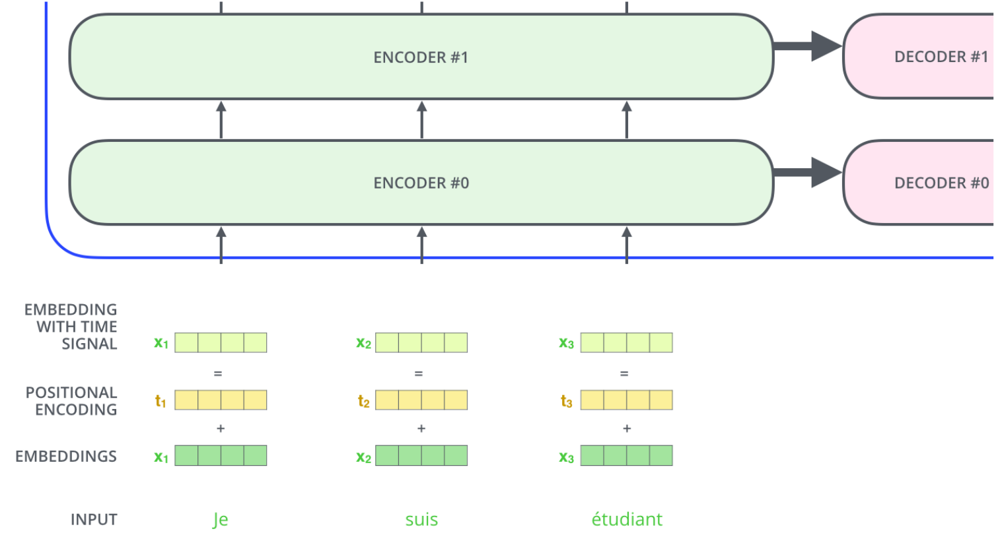

### Position Encoding mechanism

But we also want that encoding method doesn't depend on length of sentense. So for number of position *t* we make 
*d*-dimensional vector:

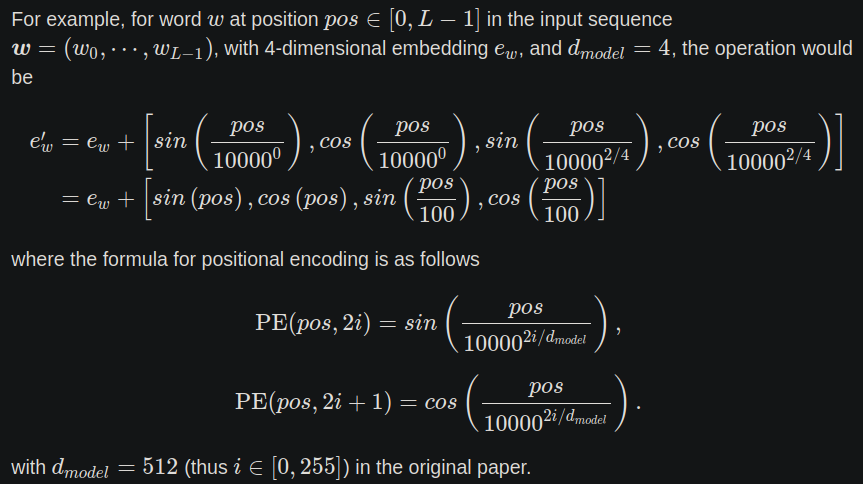

*i* - the "sequence" of the vector. It is used for making alternate even and odd sequences (2i and 2i+1).

### Position Encoding visualization (128-dimensional encoding of 50 positions)

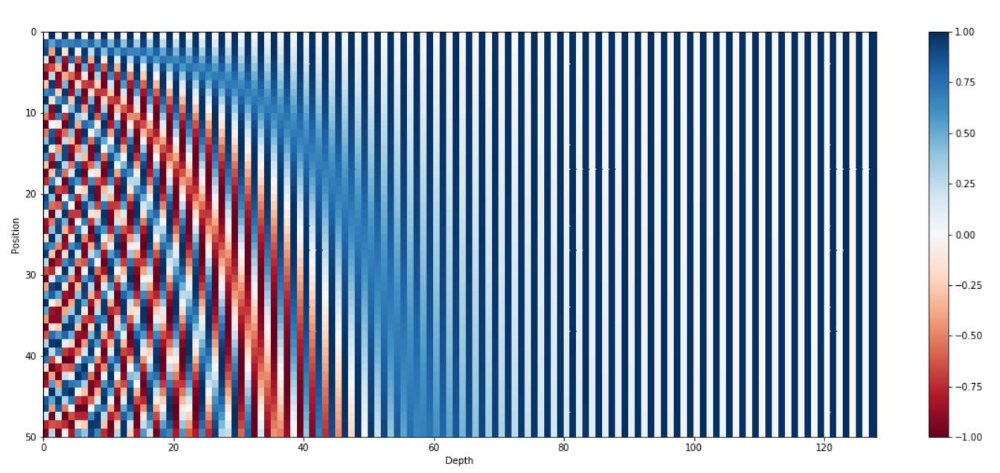

### Encoder: Residual connection and layer normalization

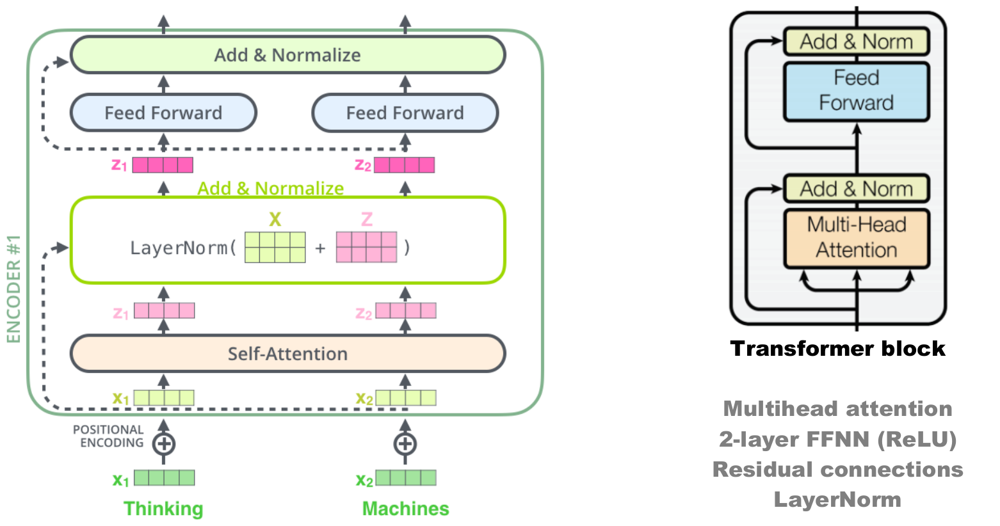

### Residual connection formula

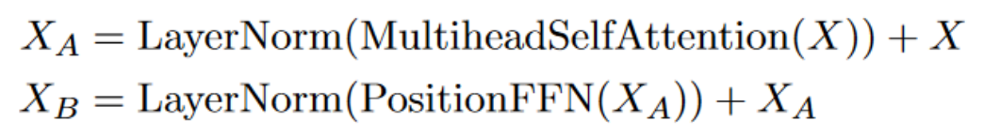

### Layer normalization formula

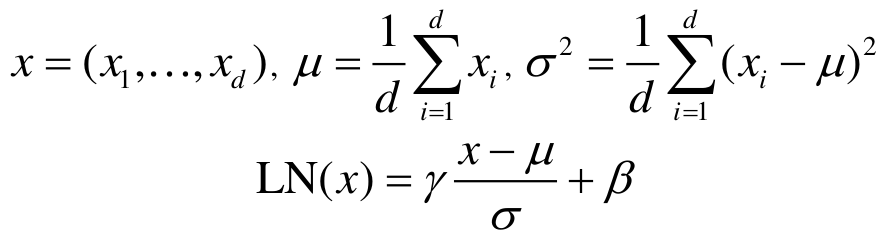

### Encoder: Feed-Forward layer

Simple 2-layer NN with ReLU activation function

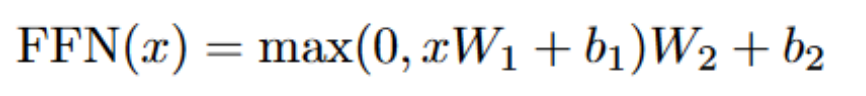

## Decoder

We don't know the length of the output sequence, so we get it consequentially, token by token. We need to store only key and value matrices to generate the next token, because we need to calculate attention only for the last generated token, and for that we need to get query for this token using W<sup>Q</sup>, multiply it on the key matrix K<sup>T</sup>, take softmax and then multiply the result on the value matrix V.

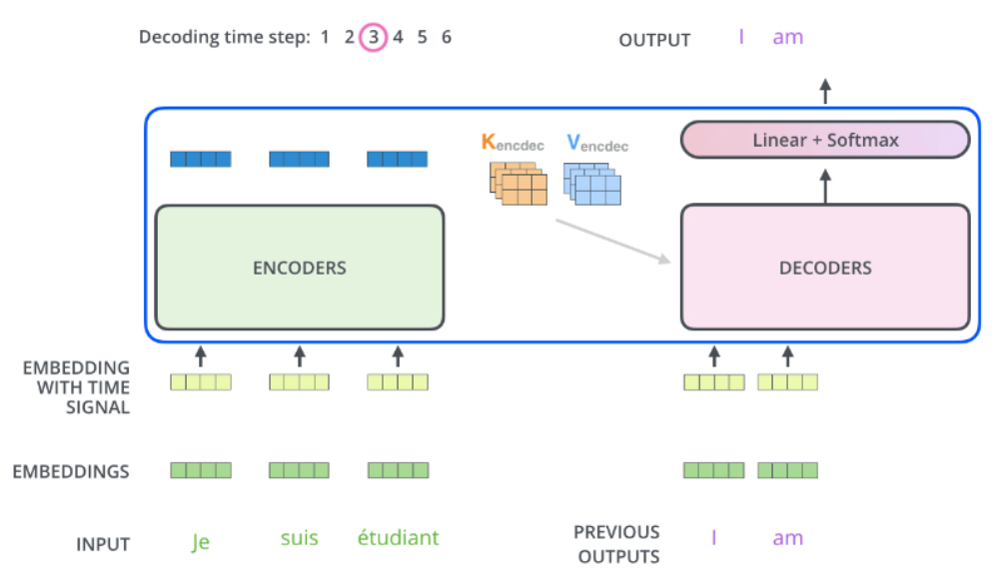

### Decoder: Masked Self-Attention (Casual attention)

#### Padding mask

Mask end tokens of sequences with zero.

#### Sequence mask

Problem: decoder isn't allowed to see future answers during training to avoid data leakage. So we use masked multi-head attention, that masks all decoder tokens that will appear after current token.

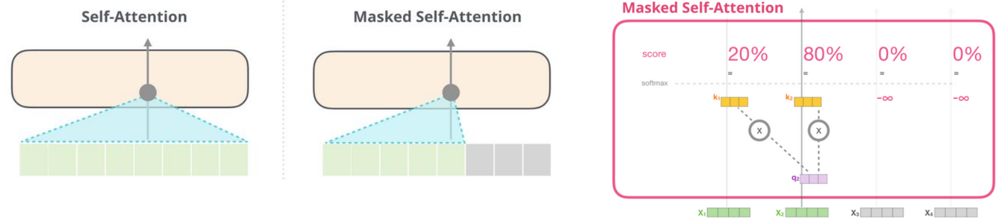

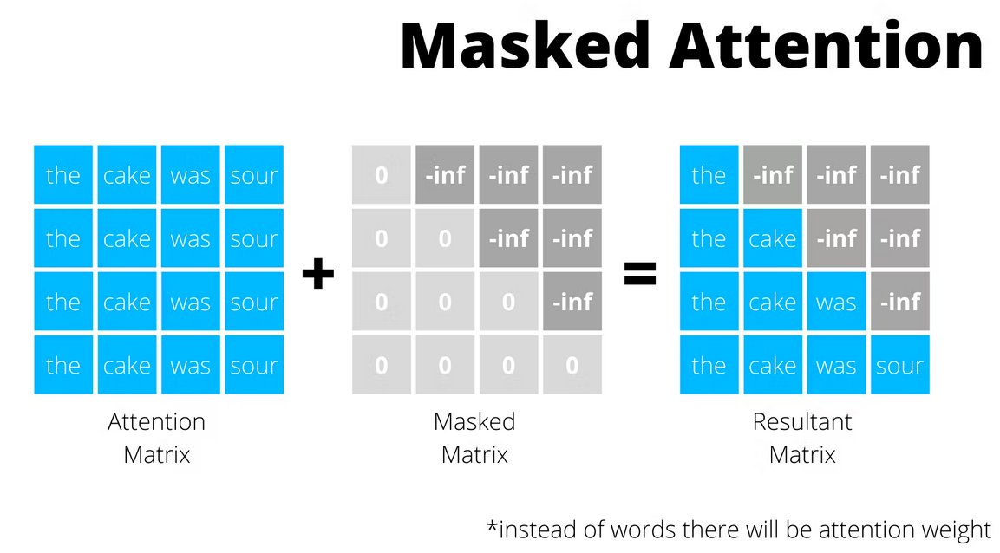

Sequence mask is implemented by adding upper-triangular mask filled with very small values (like -inf or -1e9 to make softmax for these values to be ~ 0) on self-attention weight matrix.

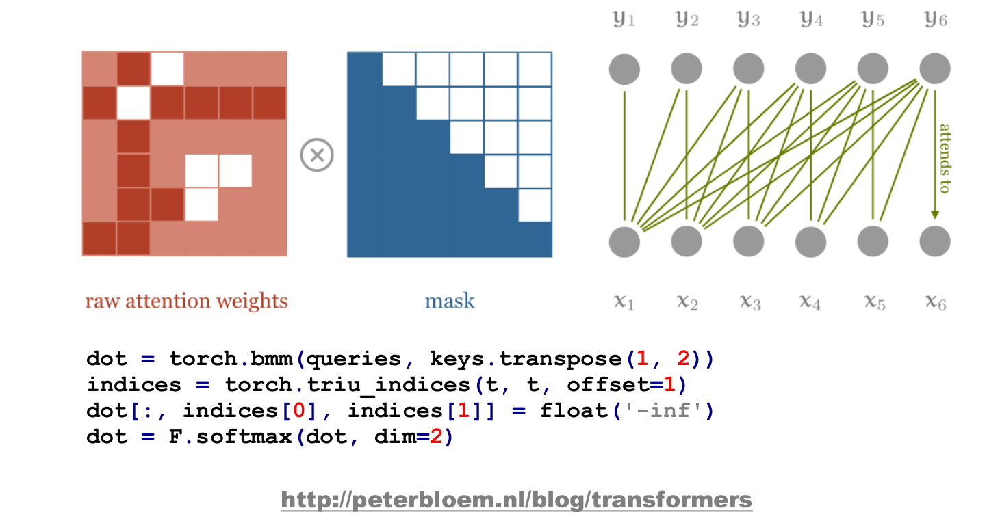

### Decoder: Output layer

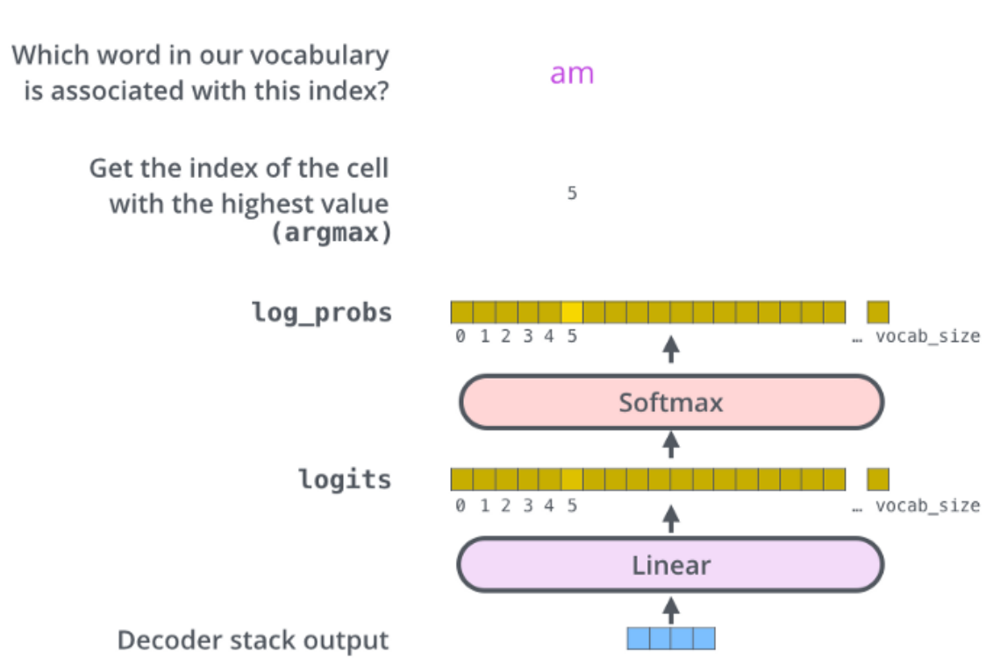

Greedy strategy of output word selection isn't the best and may lead to **text degeneration**

### Transformer is a highly residual architecture

In Transformers, the exact same shape is maintained
from the moment tokens are embedded,
through dozens or hundreds of intermediate layers,
and until they are "unembedded" into class logits.
The Transformer Circuits authors refer to this pathway as the "residual stream".

The resiudal stream is easy to see with a change of perspective.
Instead of the usual architecture diagram above,
which emphasizes the layers acting on the tensors,
consider this alternative view,
which emphasizes the tensors as they pass through the layers:

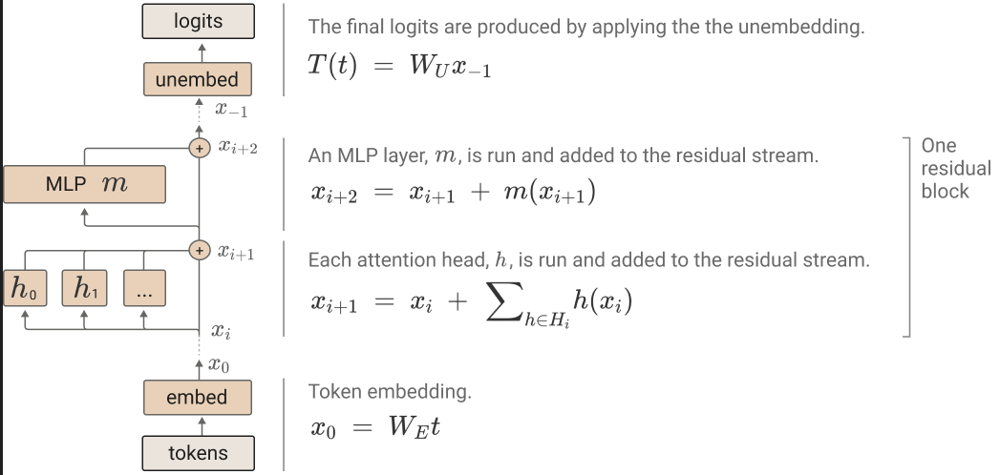

In each layer Multi-Head Attention and FFN modules predict what sense each token needs - every next layer makes each token more and more precise in terms of context (Attention) and adds more sense to its embedding (FFN). So on each layer token's embedding remains in the same "sense coordinates" and in the same embedding space and transformer's layers add modifications that give more or less of contextual information to the current token. 

If token embedding's sense is already precise enough after first layers, every next layer would add only insignificant modifications (especially when there is no need to process context from tokens that are far from current token).

### Decoder: KV cache

KV caching occurs during multiple token generation steps and only happens in the decoder (i.e., in decoder-only models like GPT, or in the decoder part of encoder-decoder models like T5). Models like BERT are not generative and therefore do not have KV caching. Since the decoder is causal (i.e., the attention of a token only depends on its preceding tokens), at each generation step we are recalculating the same previous token attention, when we actually just want to calculate the attention for the new token.

This is where KV comes into play. By caching the previous Keys and Values, we can focus on only calculating the attention for the new token.

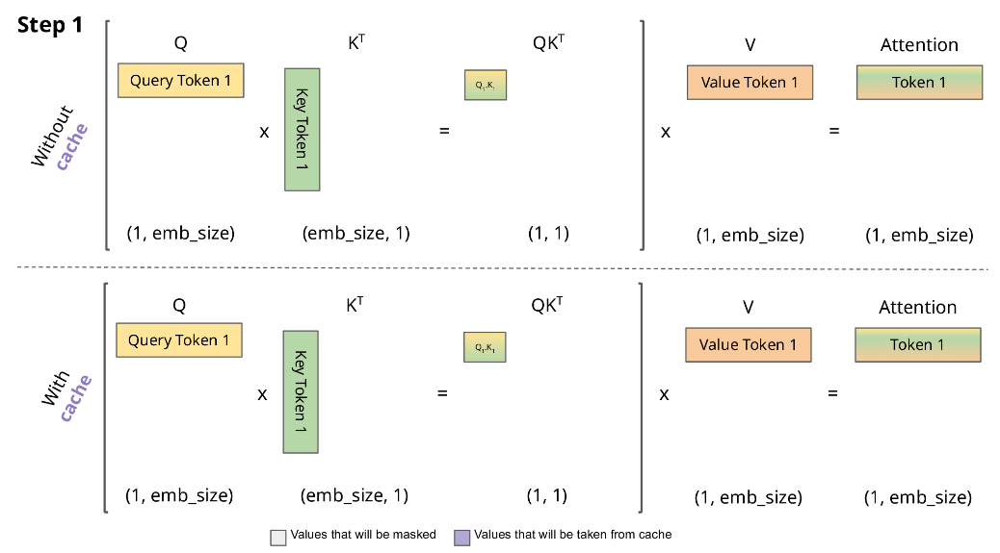

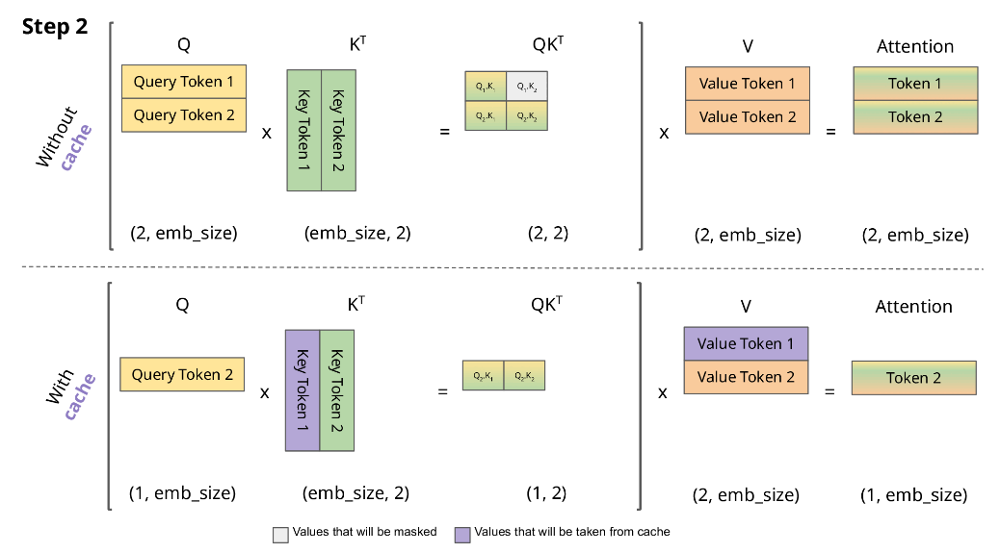

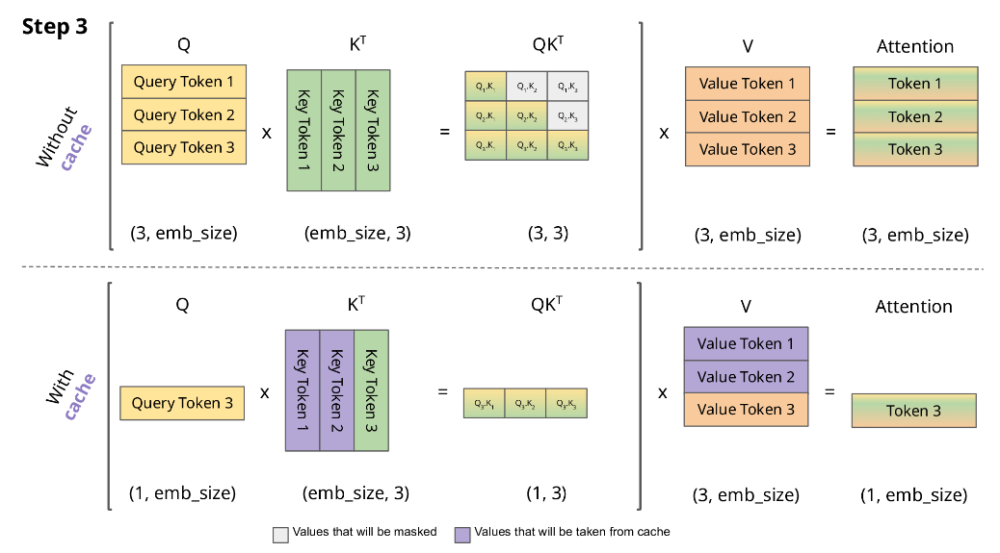

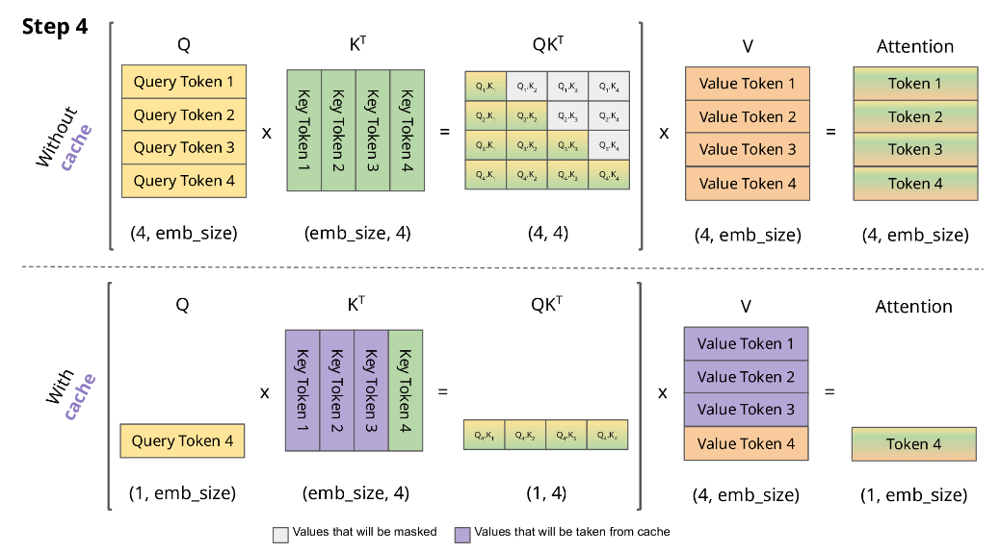

# Additional transformer properties

### Transformer heads learn low rank transformations.

Consider matrix representation of attention as 

$\text{softmax}(\underbrace{x^TW_Q^T}_Q \underbrace{W_Kx}_{K^T}) \underbrace{x W_V^T}_V W_O^T$

Consider matrices, $W_{QK} := W_Q^TW_K$ and $W_{OV}^T := W_V^TW_O^T$

The key/query dimension, `d_head`
is small relative to the model's dimension, `d_model`,
so $W_{QK}$ and $W_{OV}$ are very low rank,
[which is the same as saying](https://en.wikipedia.org/wiki/Rank_(linear_algebra)#Decomposition_rank)
that they factorize into two matrices,
one with a smaller number of rows
and another with a smaller number of columns.
That number is called the _rank_.

When computing, these matrices are better represented via their components,
rather than computed directly,
which leads to the normal implementation of attention.

In a large language model,
the ratio of residual stream dimension, `d_model`, to
the dimension of a single head, `d_head`, is huge, often 100:1.
That means each query, key, and value computed at a position
is a fairly simple, low-dimensional feature of the residual stream at that position.

For visual intuition,
we compare what a matrix with a rank 100th of full rank looks like,
relative to a full rank matrix of the same size:

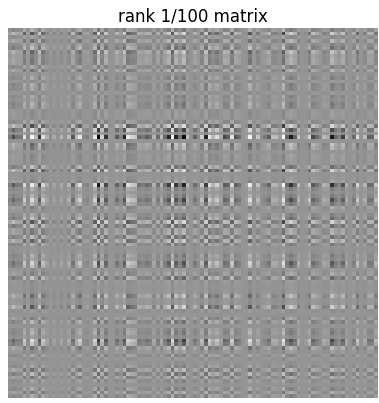

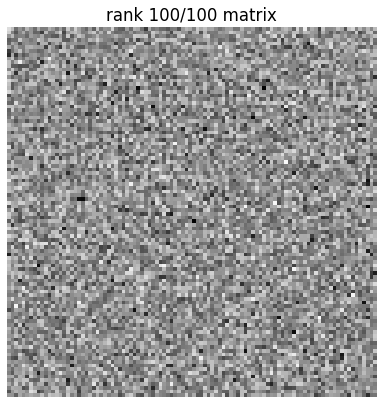

The pattern in the first matrix is very simple,
relative to the pattern in the second matrix.

Another feature of low rank transformations is
that they have a large nullspace or kernel --
these are directions we can move the input without changing the output.

That means that many changes to the residual stream won't affect the behavior of this head at all.

### Residuality and low rank together make Transformers less like a sequence model and more like a computer (that we can take gradients through).

The combination of residuality (changes are added to the current input) and low rank (only a small subspace is changed by each head) drastically changes the intuition about Transformers.

Rather than being an "embedding of a token in its context", the residual stream becomes something more like a memory or a scratchpad: one layer reads a small bit of information from the stream and writes a small bit of information back to it.

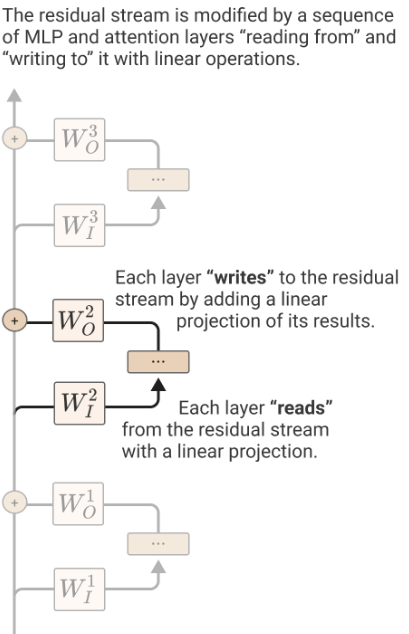

The residual stream works like a memory because it is roomy enough
that these actions need not interfere:
the subspaces targeted by reads and writes are small relative to the ambient space,
so they can

Additionally, the dimension of each head is still in the 100s in large models,
and
[high dimensional (>50) vector spaces have many "almost-orthogonal" vectors](https://link.springer.com/article/10.1007/s12559-009-9009-8)
in them, so the number of effectively degrees of freedom is
actually larger than the dimension.
This phenomenon allows high-dimensional tensors to serve as
[very large content-addressable associative memories](https://arxiv.org/abs/2008.06996).
There are
[close connections between associative memory addressing algorithms and Transformer attention](https://arxiv.org/abs/2008.02217).

Together, this means an early layer can write information to the stream
that can be used by later layers -- by many of them at once, possibly much later.
Later layers can learn to edit this information,
e.g. deleting it,
if doing so reduces the loss,
but by default the information is preserved.

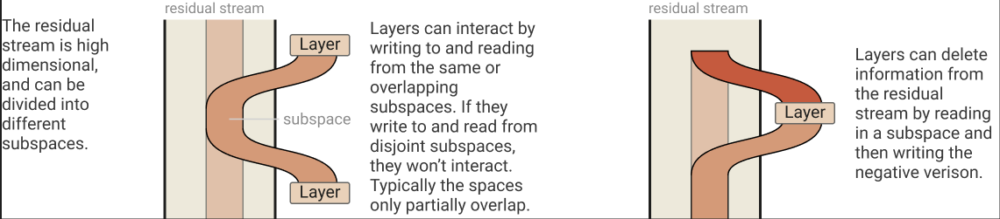

Lastly, the softmax in the attention has a sparsifying effect,
and so many attention heads are reading from 
just one token and writing to just one other token.

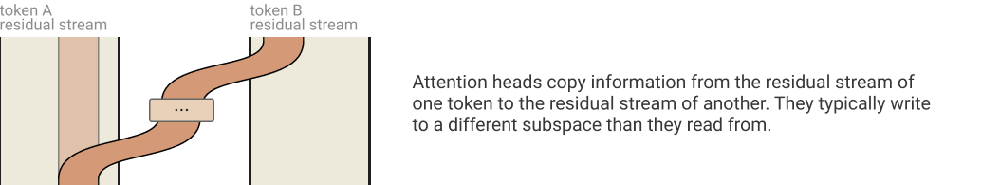

Repeatedly reading information from an external memory
and using it to decide which operation to perform
and where to write the results
is at the core of the
[Turing machine formalism](https://en.wikipedia.org/wiki/Turing_machine).

This point of view seems
very promising for explaining numerous
otherwise perhaps counterintuitive features of Transformer models.

- It predicts that Transformers will readily copy-and-paste information,
which might explain phenomena like
[incompletely trained Transformers repeating their outputs multiple times](https://youtu.be/SQLm9U0L0zM?t=1030).

- It also explains
[in-context learning behavior](https://transformer-circuits.pub/2022/in-context-learning-and-induction-heads/index.html),
an important component of why Transformers perform well on medium-length texts
and in few-shot learning.

- Transformers also perform better on reasoning tasks when the text
["let's think step-by-step"](https://arxiv.org/abs/2205.11916)
is added to their input prompt.
This is partly due to the fact that that prompt is associated
in the dataset, with clearer reasoning,
and since the models are trained to predict which tokens tend to appear
after an input, they tend to produce better reasoning with that prompt --
an explanation purely in terms of sequence modeling.
But it also gives the Transformer license to generate a large number of tokens
that act to store intermediate information,
making for a richer residual stream
for reading and writing.

# Text degeneration

Task: open-ended text generation with context x<sub>1</sub>, x<sub>2</sub>, ... x<sub>m</sub>, m < T

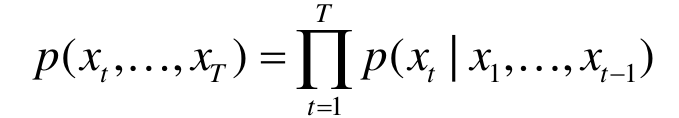

I.e. we need to continue the text. We have the next word probability distribution from our model. How to select the next word?

### Greedy decoding / beam search

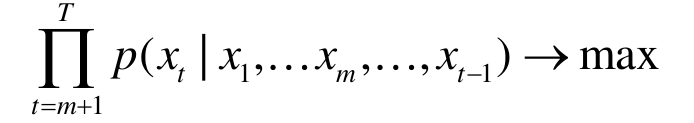

Select the most probable word or select among set of the most probable words. This strategy fails, it leads to the text cycling and unnaturalness (text degeneration). Transformer architechture also leads to text repeation (next word occurs among previous 128 words in 63% of cases, in human speech - in 49% of cases)

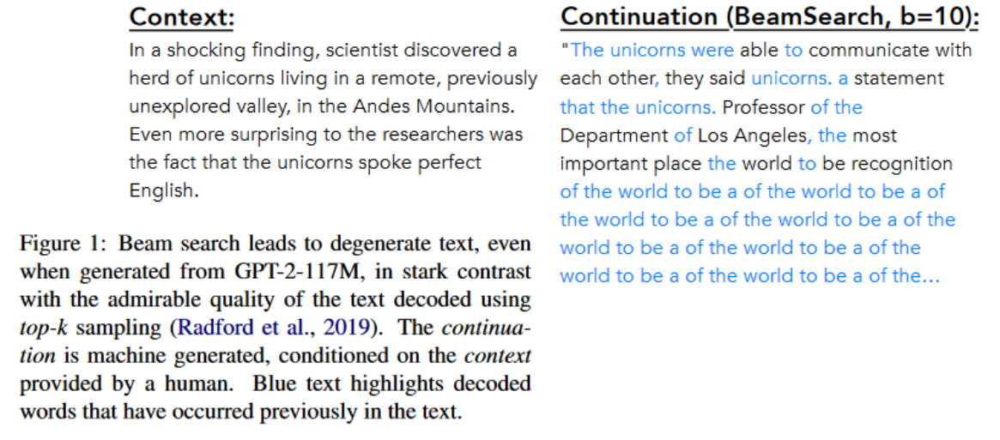

### Wide/narrow distribution problem

How to select words from narrow (couple of words are the most probable) and wide distribution (a lot of words has similar probability)?

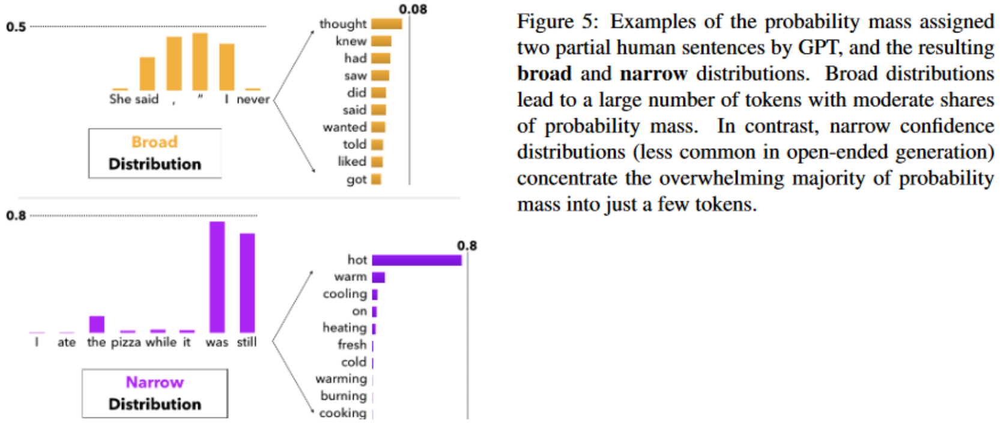

### How to tackle with text degeneration?

- sampling with temperature; select words according to their probability and also add temperature parameter, which may increase/decrease word's probability

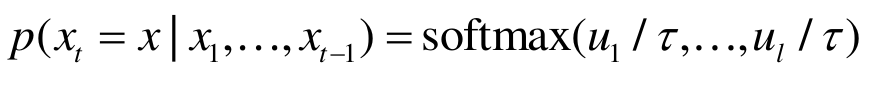

- top-k sampling; select among top k most probable words 

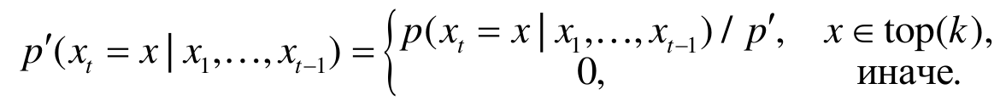

- nucleus (top-p) sampling; select among most probable words whose total probability sum more than some parameter value (p)

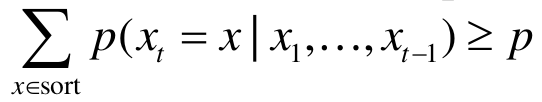

- penalized sampling; penalizes words that are in already met in the context of previous words (way to tackle with word repeation)

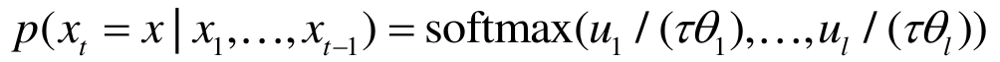

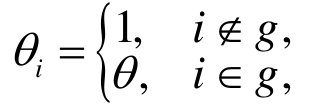

Nucleus Sampling looks the most adequate

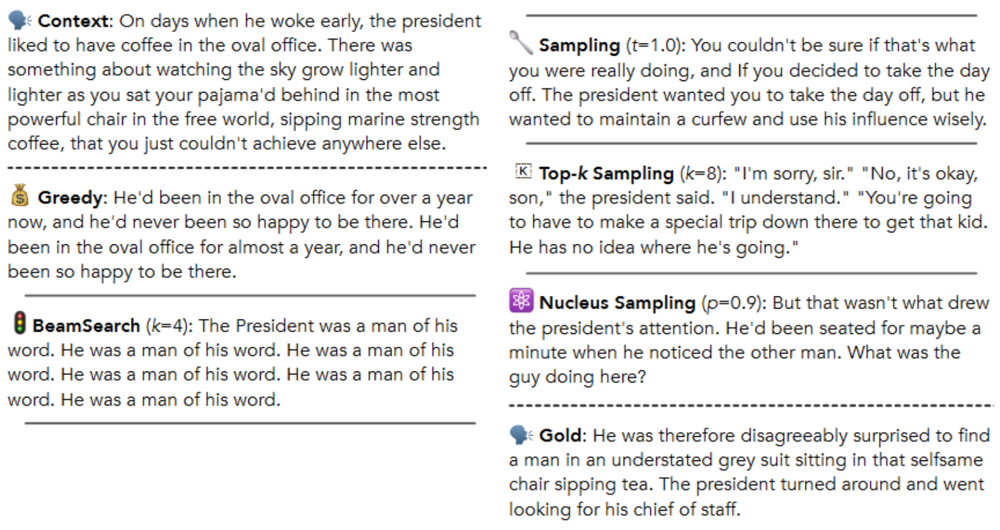

# Transform training

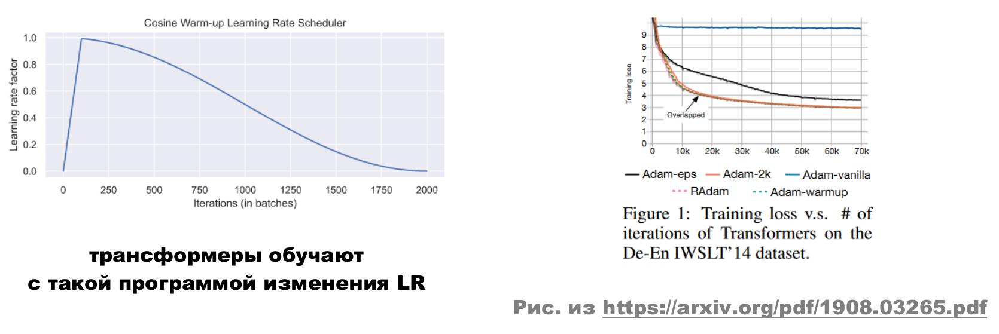

 - use warm up (gradual increasing of LR) on first training epochs, then slowly decrease LR 
 - warm up is used because on first iteration huge LR values can lead to rapid increasing of gradient values caused by Layer Norm module, so training may become unstable
 - after warm up is over - begin to gradually decrease LR on every iteration
 - also warm up is used because Adam optimizer can increase variance on the first iterations, so we need small LR at first

## Transform training: Learning Rate & Batch Size

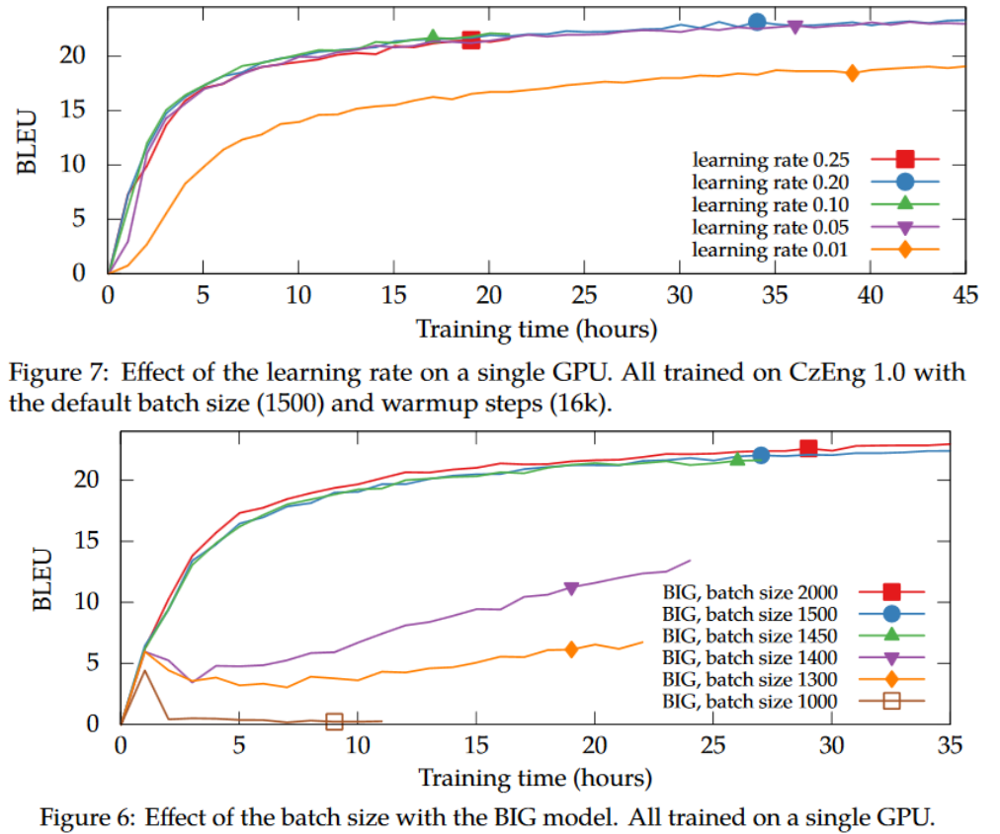

Bigger batch size lets to put longer sequences in it, that leads to increasing of quality.

## Transform training: Sequence length

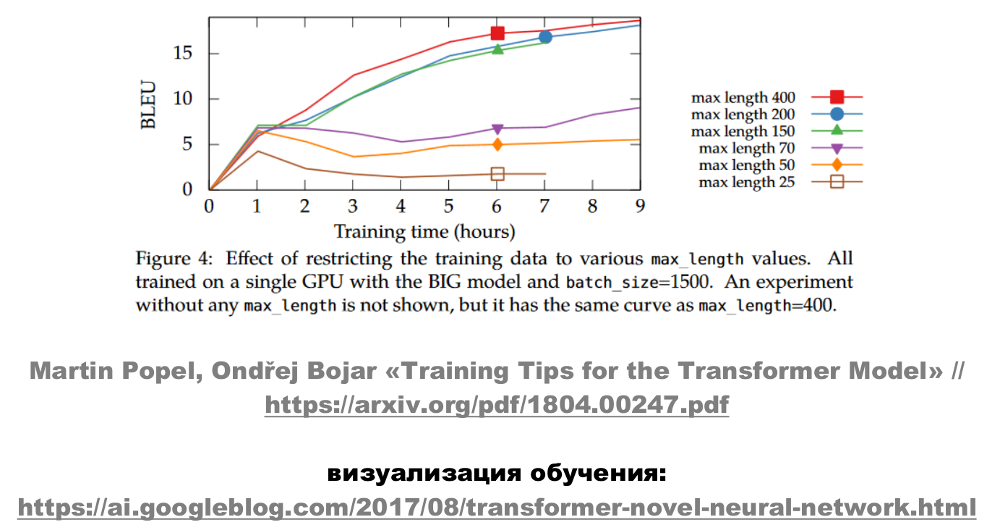

The longer sequence - the better results (see more context)

# BERT

BERT = Bidirectional Encoder Representations from Transformers

- transformer NN for pretraining of language models and obtaining of word representations
- main idea: take LM (language model), train in on huge text set and then fine tune for different specific tasks
- uses encoder only (encoder + decoder is used for complex tasks like machine translation, for word representation encoder without decoder is enough)
- bidirectional

### Problem of bidirectionality

When NN processes context bidirectionally, data leakage appears and NN just learns to look forward for next word prediction. 

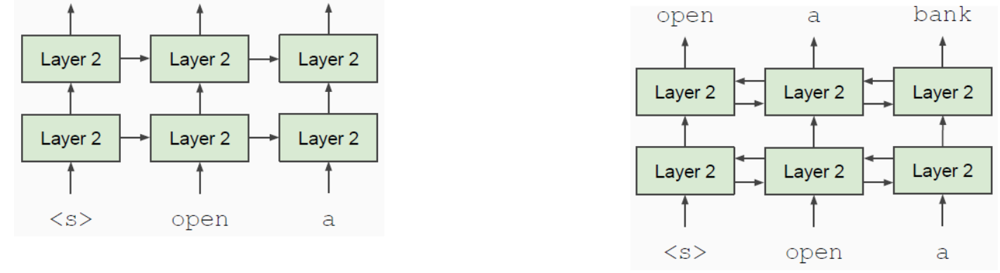

### How to solve? 

### MLM (Mask Language Model)

Mask 15% of randomly chosen tokens and predict them.

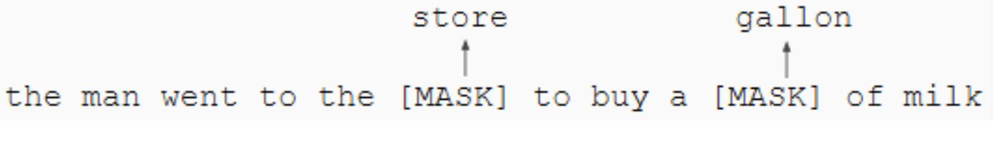

p = 0.8 - replace with [MASK]

went to the store → went to the [MASK]

p = 0.1 - replace with random word

went to the store → went to the running

p = 0.1 - do nothing

went to the store → went to the store

This is done for tackling of pretrain/finetune mismatch - token [MASK] can't be met in the real data and if model is trained to restore only masked tokens, it gets used to fact that only masked tokens are need restoration and thus representation. Random and unchanged tokens make model to build representations for every token, not masked only.

### Next sentence prediction (NSP)

Find if sentence B follows after sentence A or not.

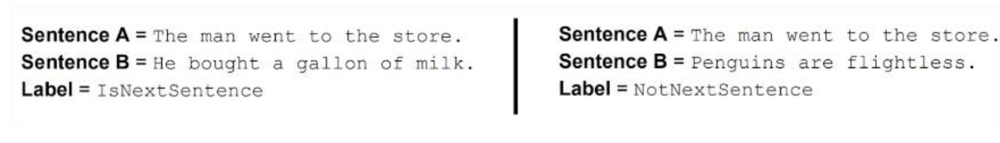

Class ratio = 50/50 

### BERT: Input representation

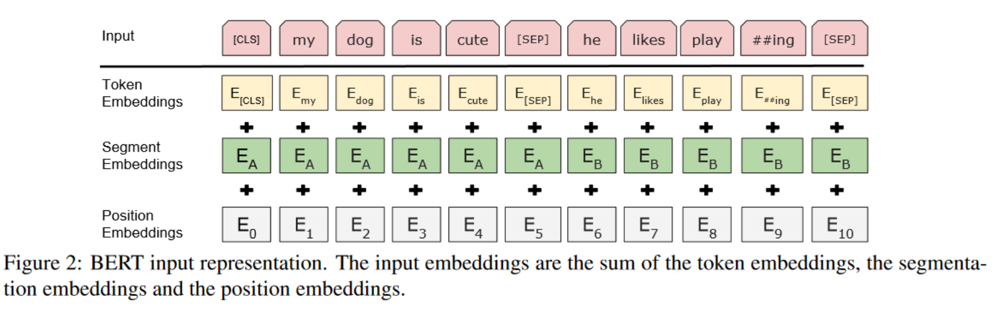


- Each **input** token is sum of 3 embeddings: token embeddings + segment embeddings (show boudaries of sentences) + position embeddings.
- Unlike vanilla transformer, position embeddings are trainable, not sin/cos - that's why you can't send to BERT sequence longer than 512 tokens - model just won't be able to process it correctly because of limited length of position embeddings
- Segment embeddings are trainable too
- Some token can be separated by two (like play and ##ing - BPE or WordPiece tokenization) 
- Two sentences are separated with special symbol [SEP]
- All embeddings can be trained

#### How it works

- Input: B sequences of lenght : (B, T); max T = 512
- Output: last layer of model with shape (B, T, D); D=768 by default
- Take CLS token of the last layer: output[:, 0, :] -> B vectors of size D and analyze them e.g. with logistic regression. 
- Why CLS? Because CLS is always at the begining of every sequence -> it doesn't contain any separate sense -> it's a good reservoir for storing of sentense sense.
- NSP task: add layer (B, D, 2) which predicts binary target (next of not next sentence)
- Masking task: add layer (B, D, voc_size), calculate loss only for masked tokens
- Loss = Loss_MLM + Loss_NSP, Loss_MLM is a cross-entropy, Loss_NSP - binary cross-entropy

### BERT details

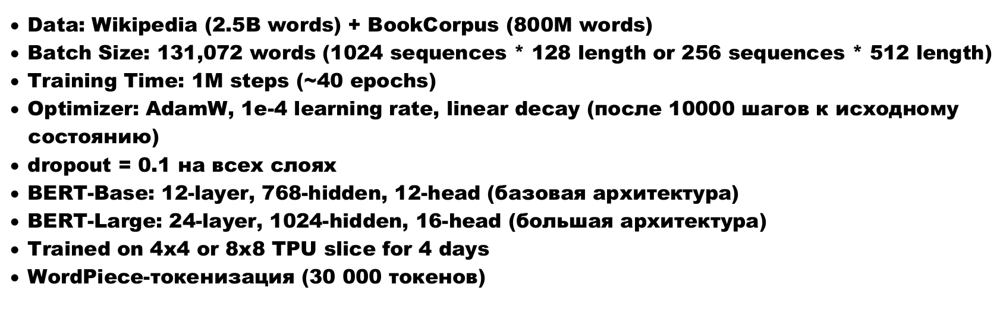

## BERT: fine tuning scheme

### Sentence classification (positive or negative)

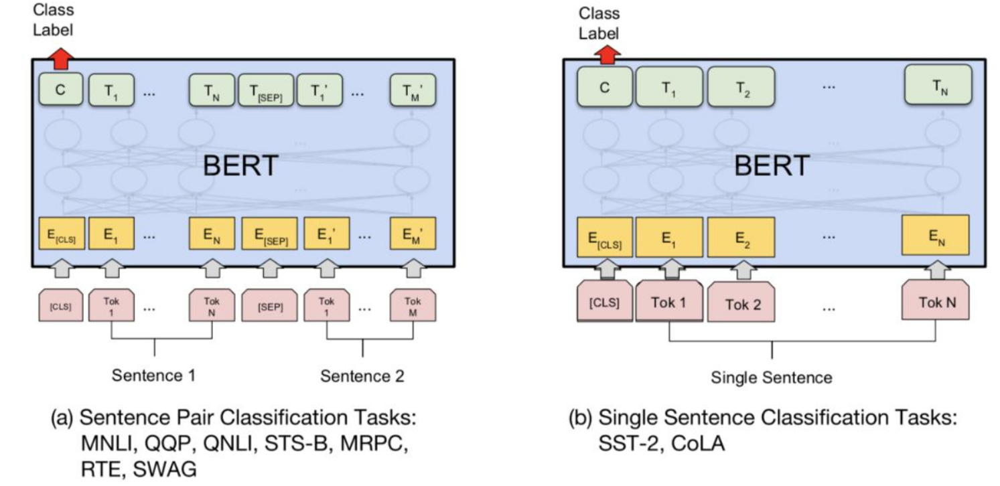

For classification let's take hidden state for token [CLS], multiply it on trainable matrix and use softmax.

### QA & Tagging

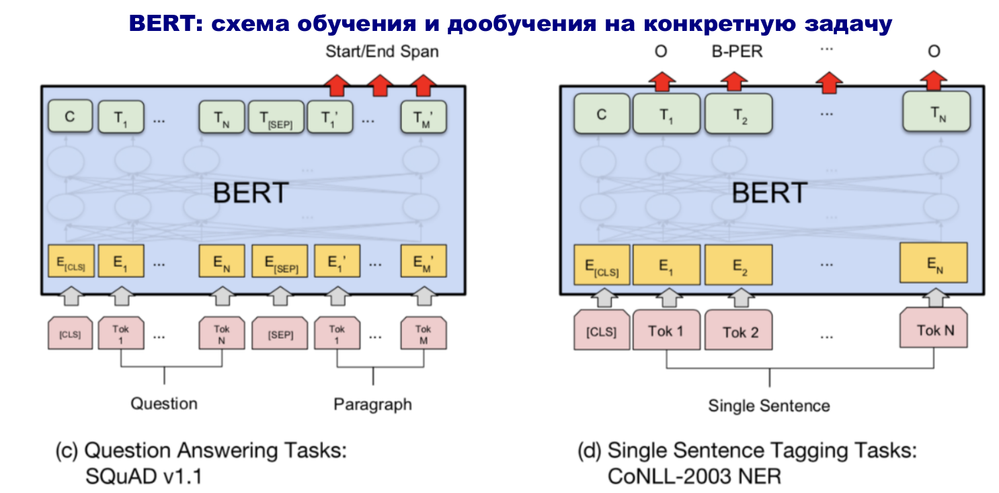

QA: answer is piece of text - for every token model predicts probability of being begin and end of answer. Trainable parameters - 2 matrices which are multiplied by token states with softmax.

Tagging: use classifier (trainable matrix + softmax) for every token and fine tune it on tagged text corpus.

Removing of some pre-training tasks decreases BERT accuracy significantly.

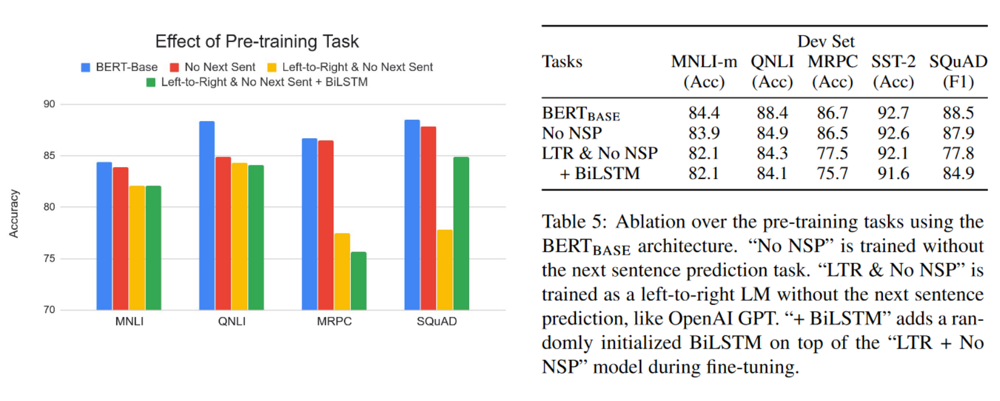

### BERT: effect of model size

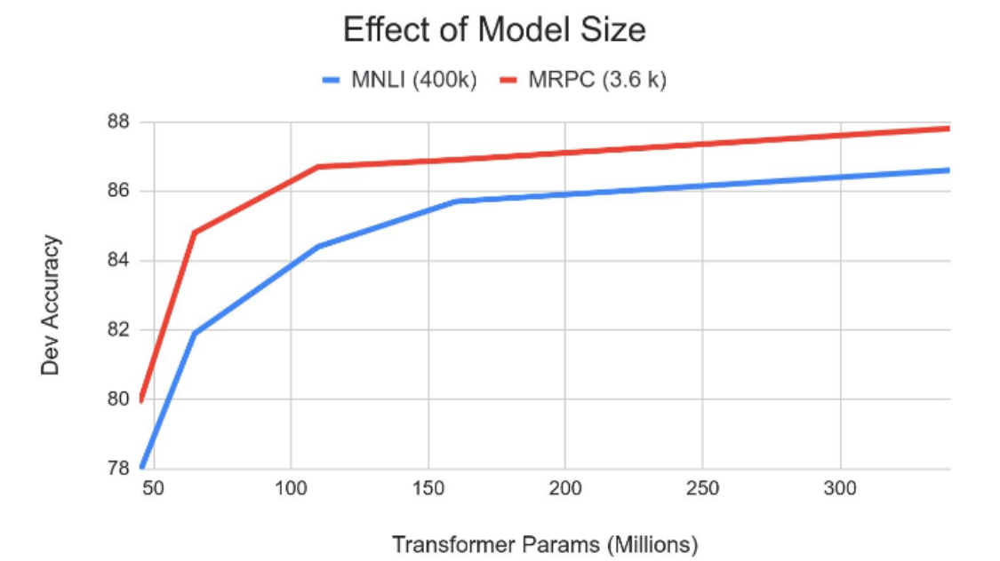

Accuracy doesn't reach asymptote with increasing of parameters number event for small datasets.

### BERT: results

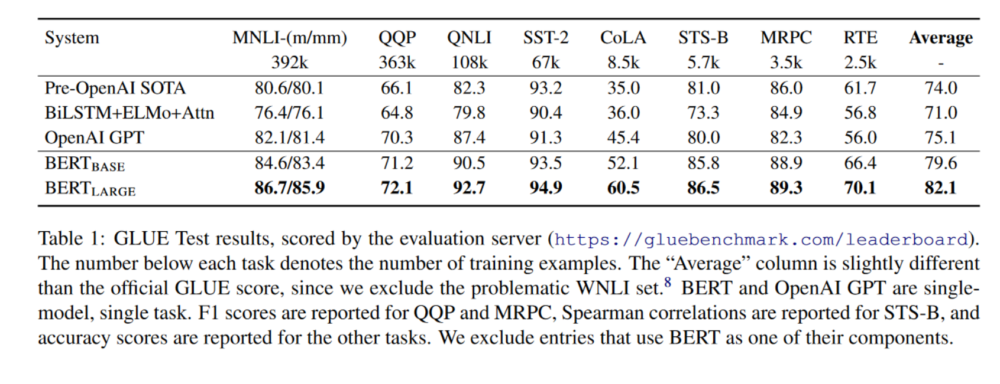

### BERT: what layers should be used for word representation?

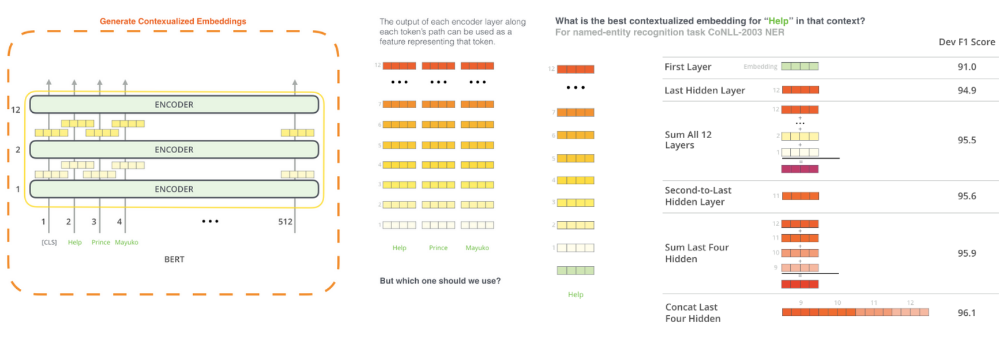

Combining (sum, concat) of layer states increases model accuracy.

# RoBERTa

RoBERTa
Same architecture as BERT — BERT was just undertrained

Training scale
  - data: 16GB → 160GB
    BookCorpus + Wiki (16) + CC-News (76) + OpenWebText (38) + Stories (31)
  - sequences seen: ~256M → ~4B  (1M × 256  →  500k × 8k)
  - batch size: 256 → 8k, lr 6e-4, warmup 24k
  - Adam retuned for large batch: β₂ 0.999 → 0.98, ε 1e-8 → 1e-6

Objective & data pipeline
  - NSP removed — FULL-SENTENCES input, packed across document boundaries
  - trained on full 512 length from the start (BERT: 128 for first 90% of steps)
  - dynamic masking — mask sampled per epoch, not baked in at preprocessing
  - byte-level BPE, 50k vocab (BERT: WordPiece 30k) — no [UNK] token at all
  - mean pooling of last layer's tokens instead of CLS token in BERT (because NSP sentence was removed and nothing pushes model to give a special meaning to CLS token), with proper fine-tuning difference between CLS and mean-pooling is almost negligible

Unchanged
  15% masking, 80/10/10 rule, absolute position embeddings, 512 token limit

Results (SOTA at publication, 2019)
    - GLUE 88.5  |  SQuAD 2.0 89.4 F1  |  RACE 83.2
    - params: base 125M / large 355M  (vs 110M / 340M — delta is the 50k vocab)

What actually mattered (ablation ranking)
  1. more data + longer training  ← most of the gain
  2. removing NSP                 ← small but consistent
  3. dynamic masking              ← marginal

Takeaway
  - no architectural insight. RoBERTa is a demonstration that BERT's architechture is good enough
  - reported numbers were a training-budget artifact, not a ceiling
  - caveat: 1024 V100s — not a compute-matched comparison

# DistilBERT

 - main idea: model-student studies to reproduce answers (in this case answer is distribution of class probabilities) of model-teacher BERT (this process is called distillation)
 - model-student has twice less layers (one of each layer pair is selected)
 - same initialization as in BERT
 - complex loss function

# ELECTRA = Efficiently Learning an Encoder that Classifies Token Replacements Accurately

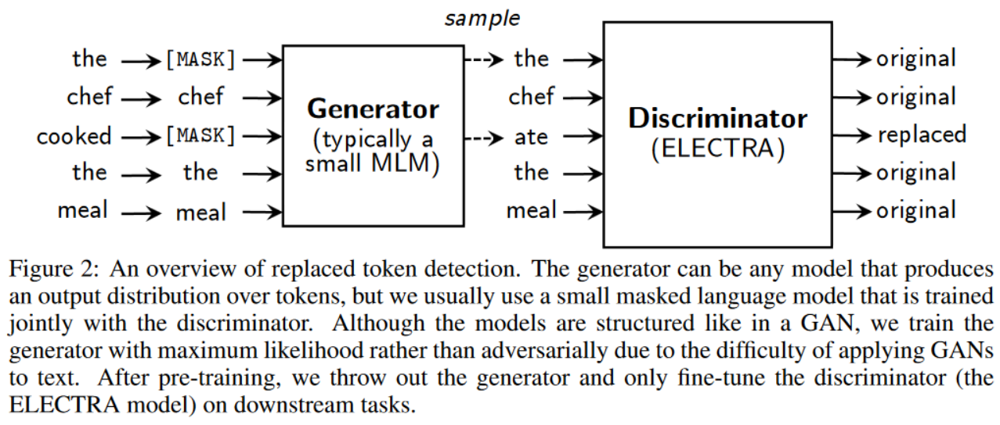

 - main idea: instead of BERT-like masking replace some tokens using generator model and try to find replaces with discriminator model
 - bidirectional model but it's trained with all tokens (not 15% of masked ones)
 - generator is small model (2-4x smaller than discriminator)
 - generator loss function:
 
 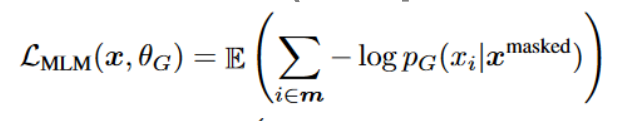

 I.e. generator task is a simple BERT-like MLM: predict the masked token
 
 - discriminator loss function
 
 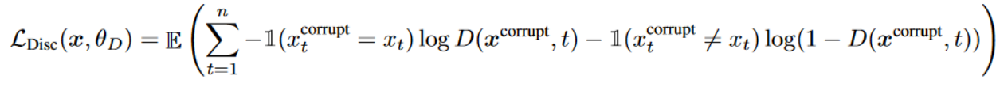

 I.e. discriminator loss is a simple binary cross-entropy: minimize prediction for non-masked tokens and maximize it for the masked ones.
 
 - both generator and discriminator are transformers
 - no MASK tokens
 - weight sharing for input embeddings between generator and discriminator (to decrease number of parameters)
 - trains fast (4 days on 1 GPU and better than GPT)
 - more info here https://openreview.net/pdf?id=r1xMH1BtvB

### ELECTRA: results

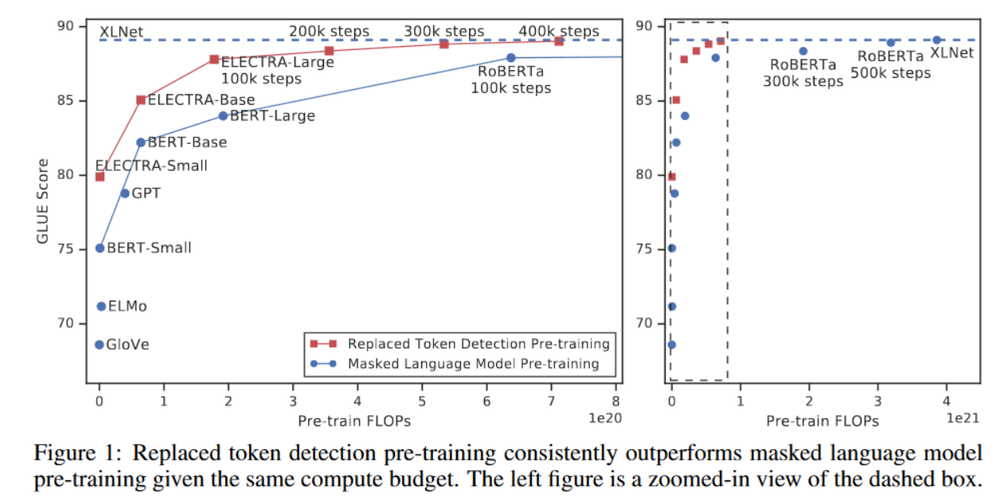

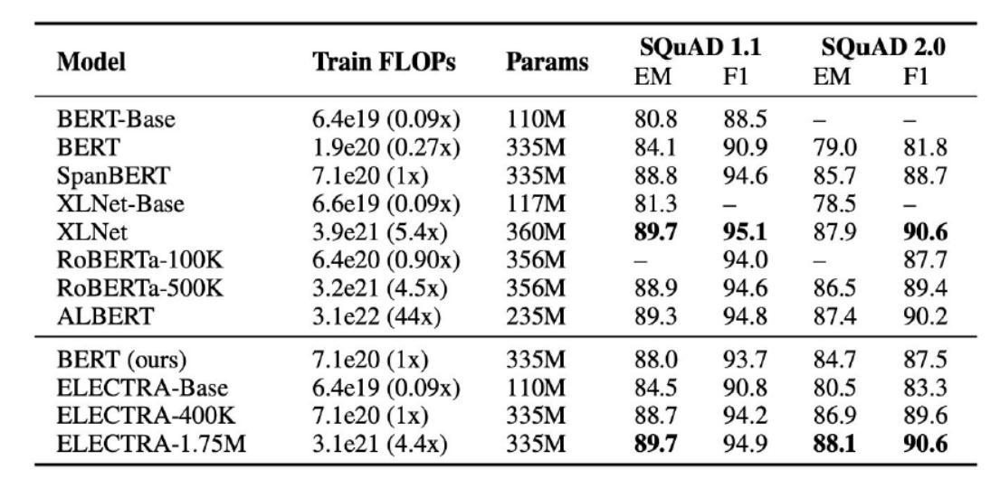

# DeBERTa

Architectural change, unlike RoBERTa

Disentangled attention
  - token content and position stored as two separate vectors
  - attention score = content→content + content→position + position→content + position→position
    (BERT: single vector = content + position, summed before layer 1)
  - positions are relative, so length generalization comes for free
  - position encoding is trainable: it's a table of vectors with shape 2k x d; k - max distance between tokens (position varies from -k to k), d - model's hidden size (768 or 1024)
  - tokens with distance between each other more than k are considered to have distance k

Enhanced mask decoder
  - relative positions are not always enough, so absolute positions are injected 
  in the end of attention layer, before the softmax: they are added to `query` only - `keys` and `values` don't get ones
  - this is done because e.g. relative attention alone can't find the difference between "store" and "mall" in 
  "a new store opened near the new mall" sentense, because their local context almost identical; absolute positions resolve it

v3 (2021) — what most people actually use
  - MLM → ELECTRA-style replaced token detection: discriminator is trained to detect if token was replaced by generator or not
  - gradient-disentangled embedding sharing: generator and discriminator share embeddings, but generator gradients don't flow into them
  - base beats RoBERTa-base by ~3 GLUE points on the same data

Where it stands
  v2-xxlarge (1.5B) first to pass human baseline on SuperGLUE (2021)
  v3 is the default encoder choice today — Kaggle, NER, classification

# E5 (EmbEddings from bidirEctional Encoder Epresentations)

Main idea: a pretrained encoder (BERT, XLM-RoBERTa (XLM-R)) or, in newer versions, a decoder LLM. Weakly supervised contrastive pretraining on hundreds of millions of "natural" pairs from the web: title–text, question–answer, post–comment. Fine-tuning on labeled data (MS MARCO, NQ, NLI, etc.) with hard negatives, often with distillation from a cross-encoder.

The loss is InfoNCE:

`L = −log [ exp(s(q, d⁺)/τ) / Σⱼ exp(s(q, dⱼ)/τ) ]`

where s is cosine similarity, τ is a temperature of about 0.01–0.05, and the denominator sums over the correct document and all negatives. Negatives are mostly in-batch: documents belonging to other queries in the same batch. That's why batches are huge, tens of thousands of pairs: more negatives give a stronger signal.

- Data: CCPairs, pairs from Reddit (post–comment), StackExchange (question–answer), Wikipedia (title–paragraph), scientific papers (title–abstract), news, and Common Crawl. Originally over a billion pairs, about 270M after filtering. The filtering is consistency filtering: a model trained on the raw data drops pairs where the correct document doesn't belong to its top results.

- Fine-tuning on MS MARCO, NQ, and NLI with hard negatives and score distillation from a cross-encoder reranker.
- Prefixes `query:` and `passage:` make the model asymmetric: a short query and a long document are encoded differently. For symmetric tasks (finding similar texts), both texts get `query:` prefix.
- Pooling: mean over tokens (mean-pooling)

# BGE (BAAI — Beijing Academy of AI, 2023)

Uses pretrained encoder and loss is InfoNCE too. 

- Stage 0: RetroMAE, pretraining designed for retrieval. The encoder sees lightly masked text and compresses it into the CLS vector. A lightweight decoder (1 layer) must reconstruct heavily masked text (about 50–70% of tokens), relying almost entirely on that vector. This teaches CLS to hold the meaning of the whole text rather than just help predict neighboring tokens.
- Stages 1 and 2: as in E5, contrastive training on massive weak pairs, then fine-tuning with hard negatives.
- Pooling: the CLS vector.
- Query instruction in v1: Represent this sentence for searching relevant passages:. In v1.5 it was made optional.

BGE-M3 (2024) is a notable model in its own right:

- XLM-R large (RoBERTa, trained on 100 languages) base, context extended to 8192 tokens;
- one model produces three representations: dense (CLS), sparse (a per-token weight via a linear layer + ReLU, essentially a learned BM25), and multi-vector (ColBERT: one vector per token, late interaction);
- self-knowledge distillation: the sum of the three modes' scores serves as the teacher for each mode individually.

The family also includes bge-reranker (a cross-encoder) and LLM-based variants (bge-en-icl, bge-multilingual-gemma2).

## Difference between E5 and BGE

E5 puts the emphasis on data quality and scale, including synthetic data. BGE emphasizes retrieval-oriented pretraining (RetroMAE) and multiple retrieval modes (M3). Qwen3-Embedding, GigaEmbeddings, and other current models essentially continue the same recipe: an LLM backbone, synthetic data, instructions, and distillation from a reranker.

# ALBERT - A Lite BERT

- squeezed BERT: x18 less parameters
- trains 1.7 times faster
- ligth in terms of parameters, not in terms of speed
- better than RoBERTa in some tasks (e.g. RACE)

### How in was squeezed?

- factorize WordPiece matrix from 1024 x 100k to 128 x 100k and 1024 x 128

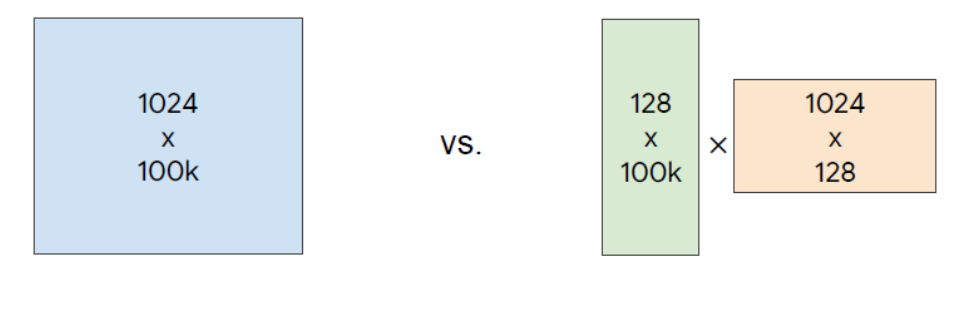

- Sentence-Order-Prediction (SOP): NSP task is easy, take sentences from one document and put them in correct/incorrect order 
- Cross-Layer Parameter Sharing (same parameters in different layers) - slightly decreases quality but also decreases parameters number

# T5

Full text2text transformer (encoder + decoder)

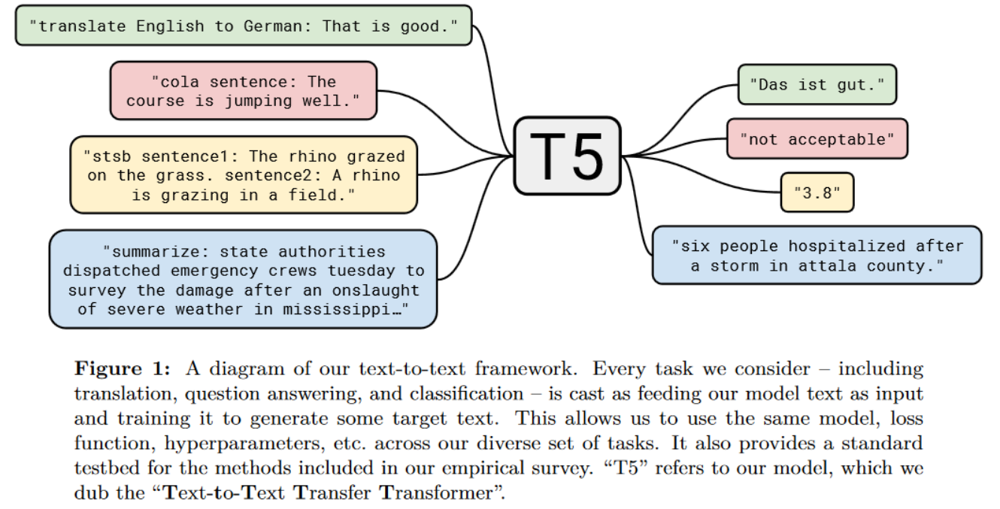

- use C4 dataset (big and good - 745 GB), don't use Wiki because it's good but monotonous and small
- clear C4:
    - delete duplicates
    - delete incomplete sentences
    - delete noise and obscene language

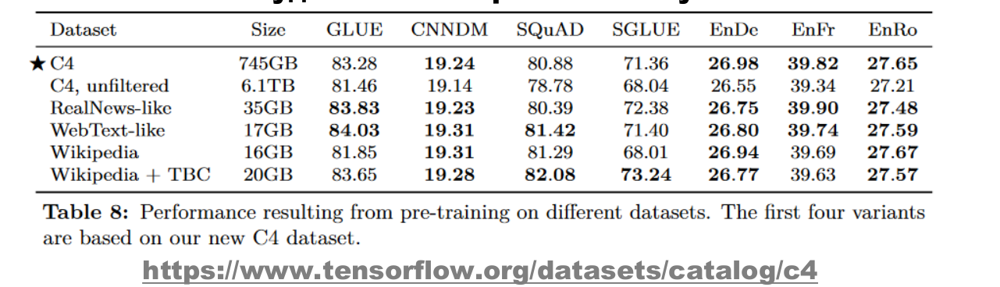

- research architechtures and find out than encoder-decoder is the best
- pretrain on unlabeled datasets (from the same domen as labeled data)
- different training strategies: multitask learning ~ pre-train-then-fine-tune approach
- scaling
- details here https://arxiv.org/abs/1910.10683

Results: pre-training is a power

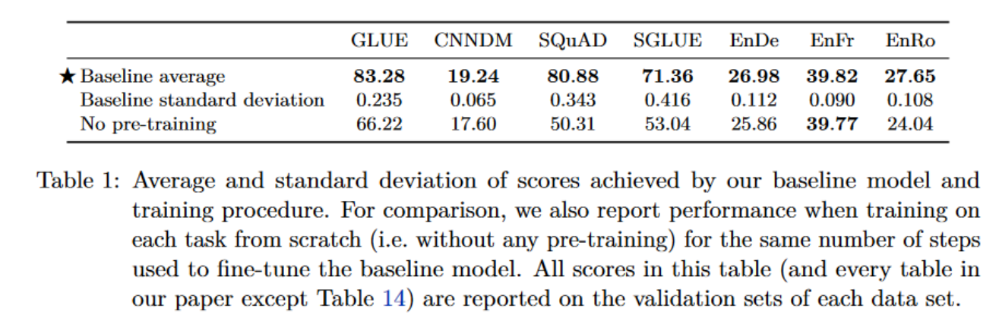

### T5: masking

Use masking, 2 or more consequtive word can be masked with one mask

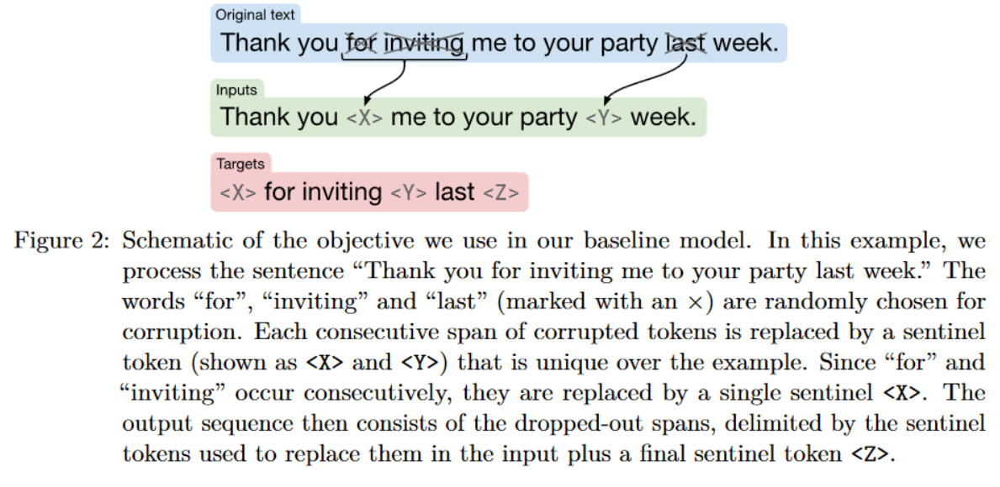

Many different masking types were used

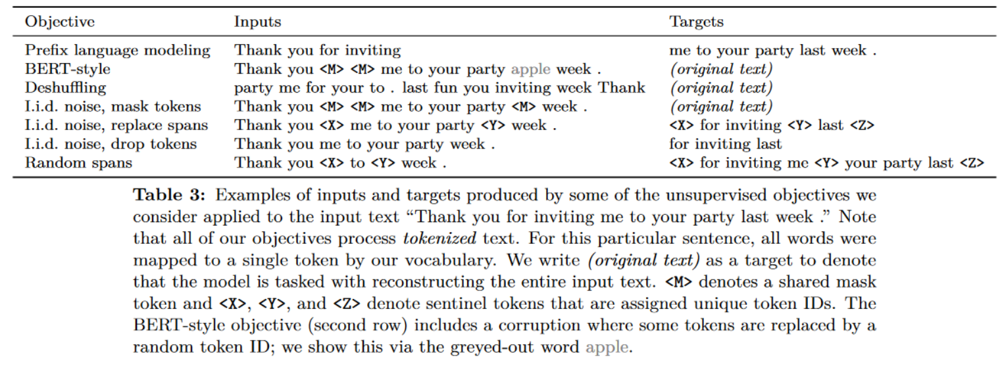

Best corruption rate is 15%, best masking type is random spans

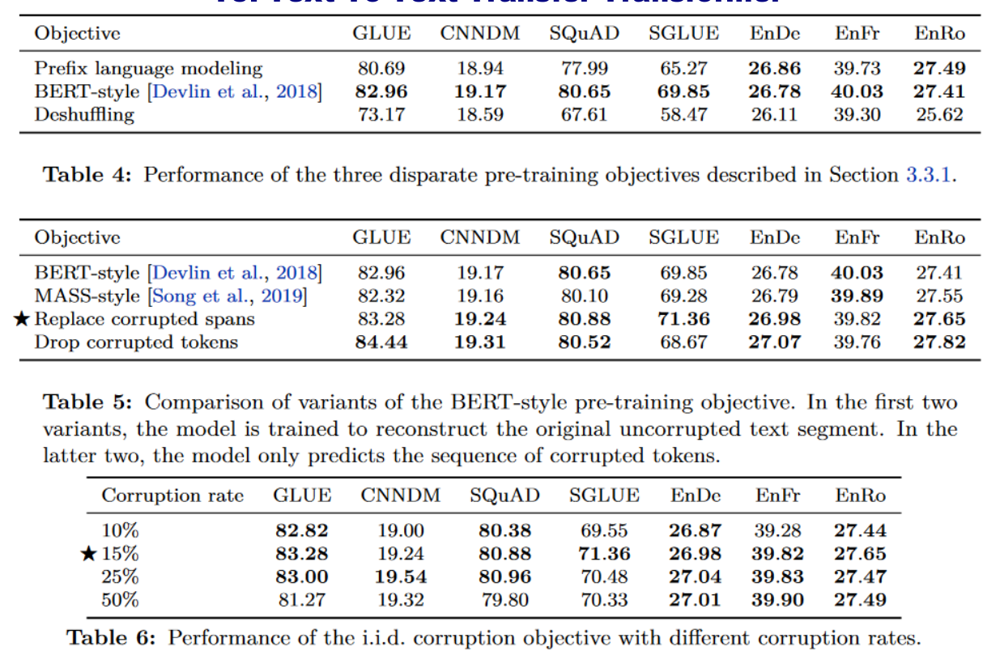

# SentenceBERT

Similar to InferSent but with BERT as sentence encoder

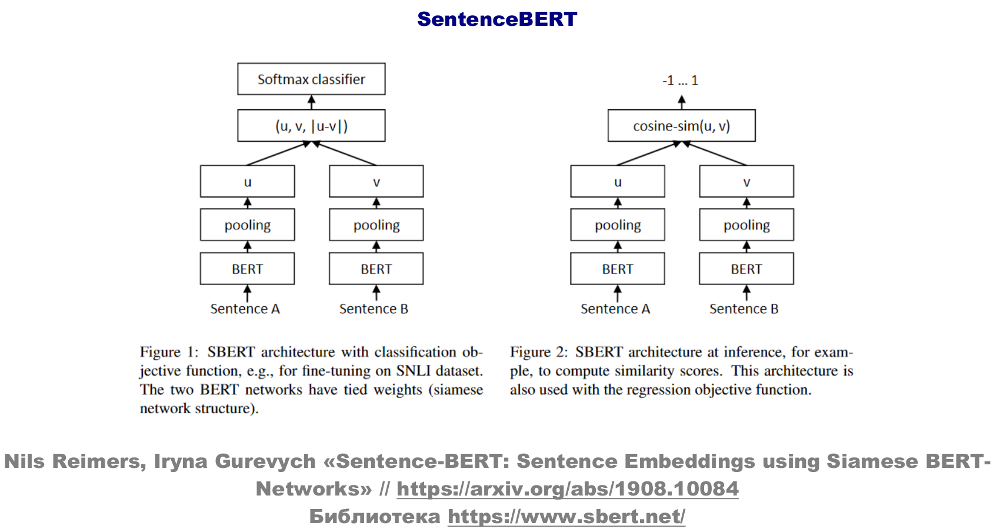



SBERT test results

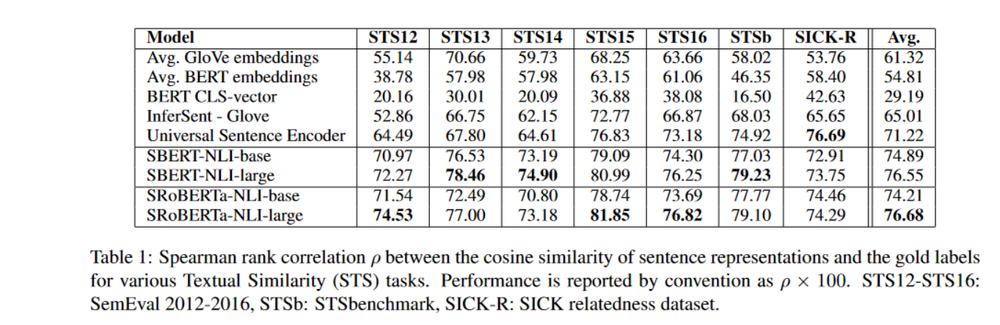

# TSDAE

Main idea: pretrain transformer encoder-decoder without labels but with noise (delete words, swap words, mask, replace, add). Decoder takes vector of fixed length. So this model learns to endcode and than restore noised text.

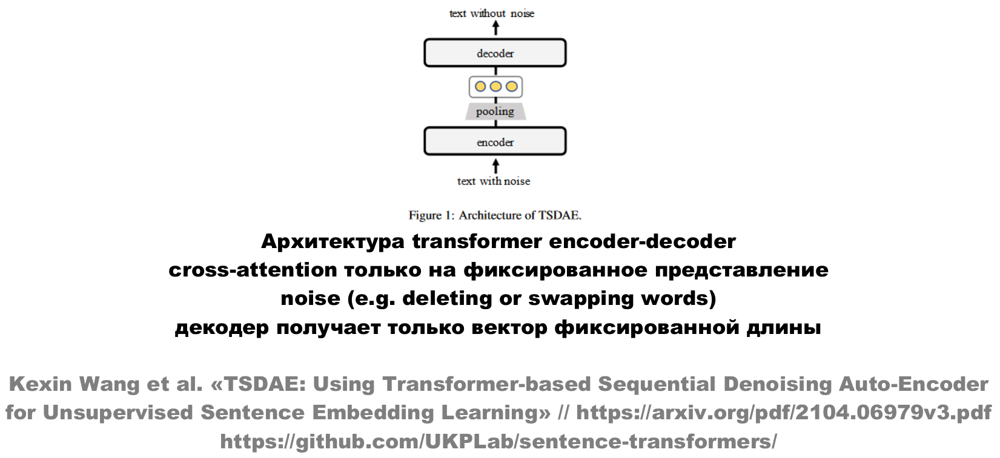

# BERTScore

How to compare sentences similarity? One of ways is SentenceBERT (read above) but BERTScore is better.

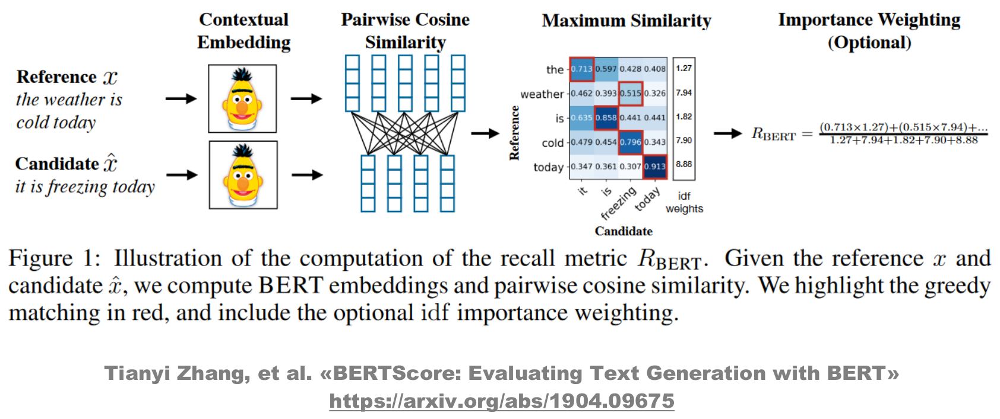

It takes 2 texts, builds word embeddings and than creates matrix of similarity between embeddings of first text and second text. Than it founds ratio between sum of must similar embeddings multiplied by their IDF (Inverse Document Frequency - high for words that are rare in current document set, but low for common words) and sum of their IDFs (look at picture).

# More info about embeddings

[Embeddings catalogue](https://github.com/Separius/awesome-sentence-embedding)

[More info about subtleties of the embedding methods](https://lilianweng.github.io/lil-log/2017/10/15/learning-word-embedding.html)

[Embeddings review](https://lena-voita.github.io/nlp_course)

[Good word2vec tutorial](http://mccormickml.com/2017/01/11/word2vec-tutorial-part-2-negative-sampling)


# BERT family

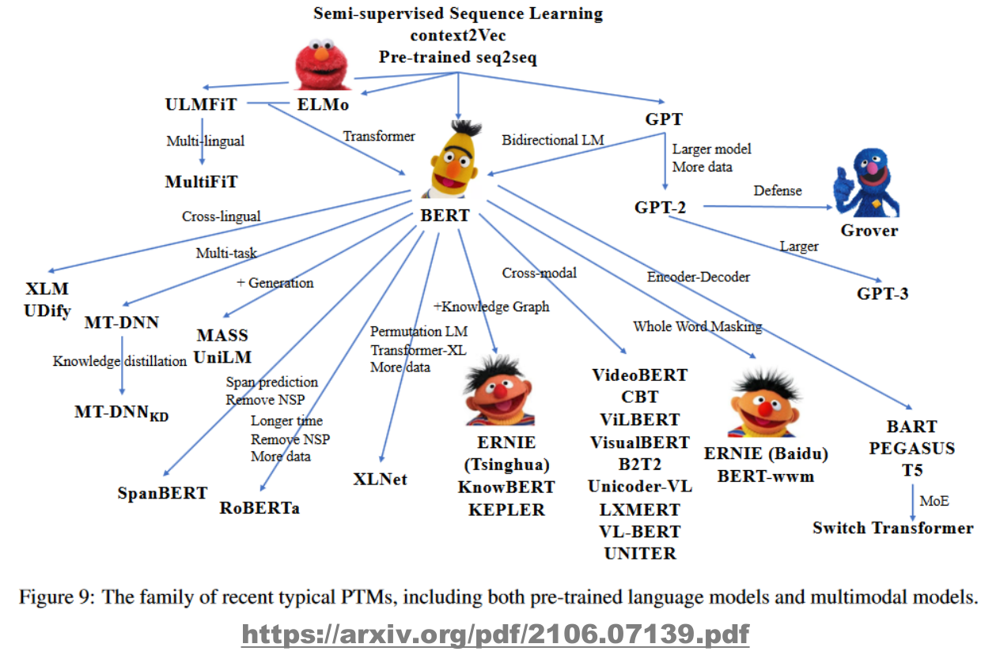

# BERT vs GPT vs ELMo

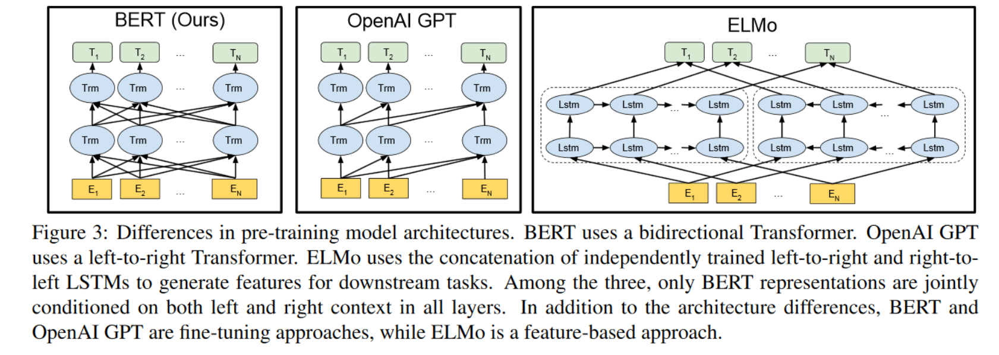

# BART: Denoising seq2seq-autoencoder Transformer

Main idea: encoder + decoder architechture; during training encoder masks the input while decoder tries to restore original input.

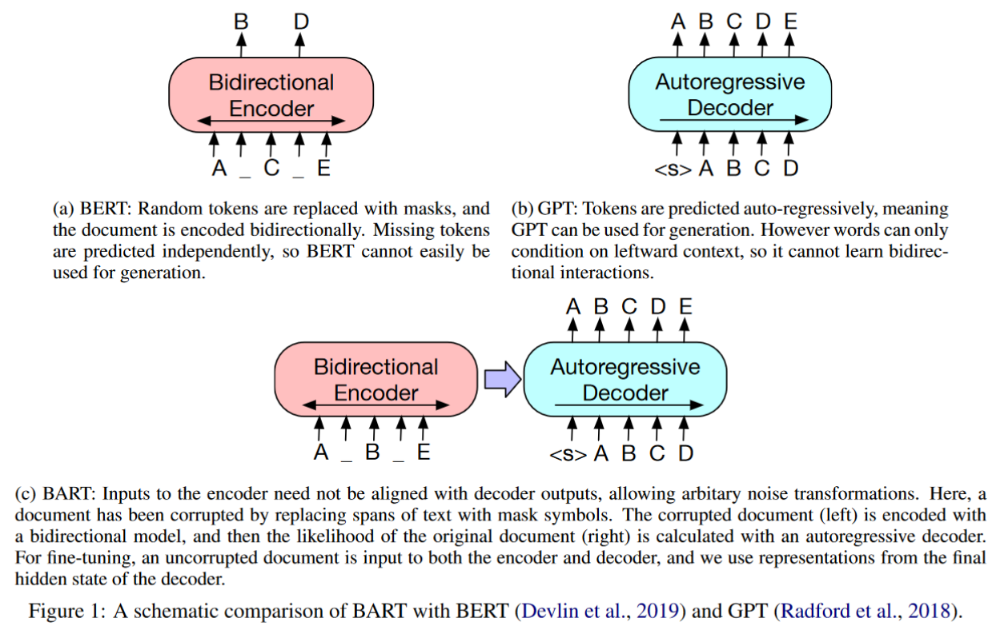

### BART: masking

Different masking types are used

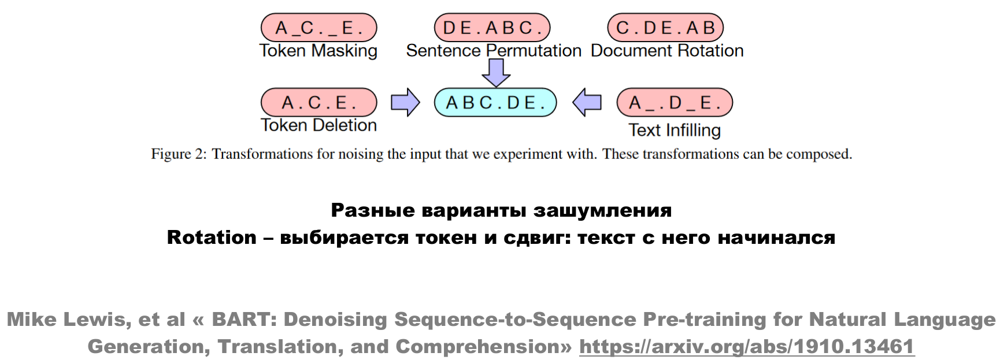

### BART: using in classification and translation tasks

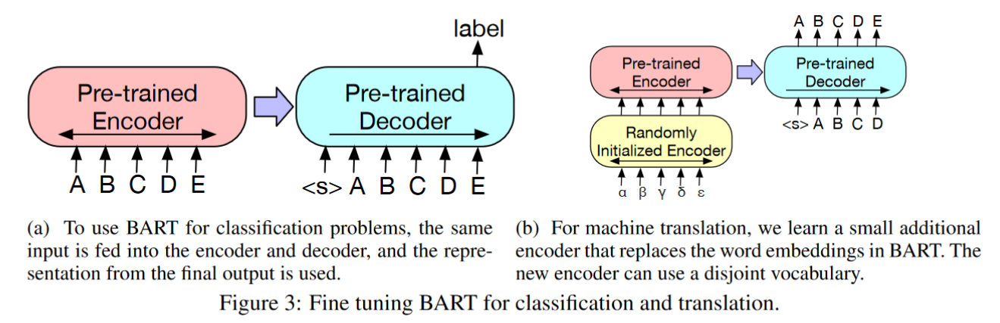

### BART: results

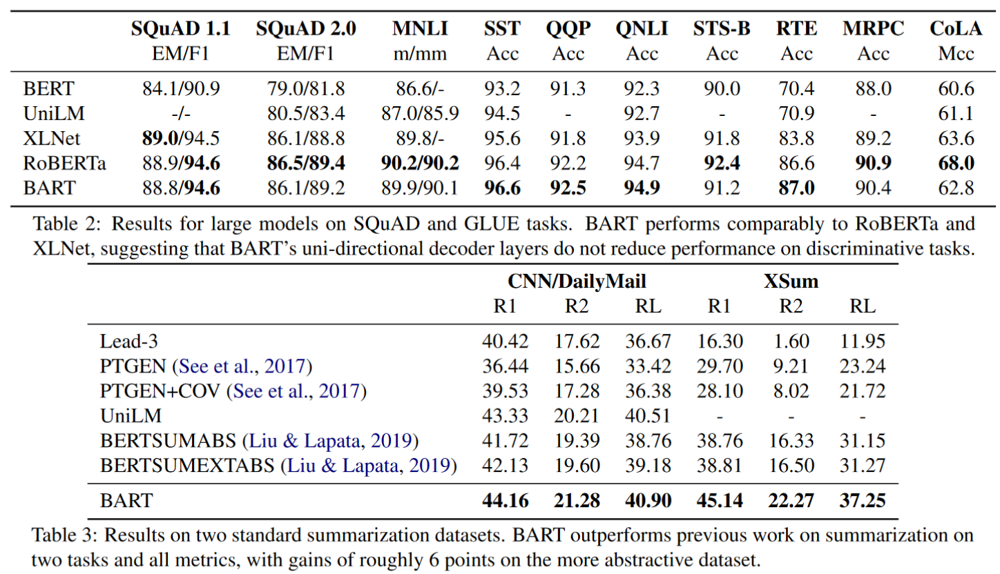

# NLP models benchmarks (2023)

### SQUAD 2.0

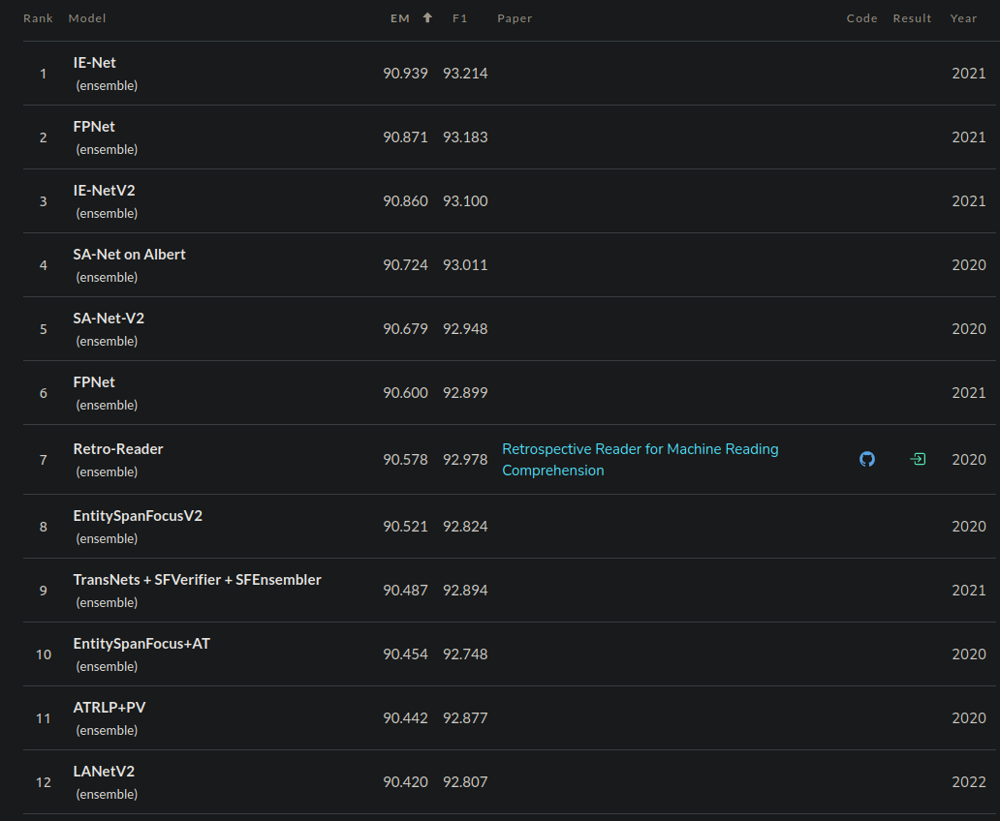


### GLUE

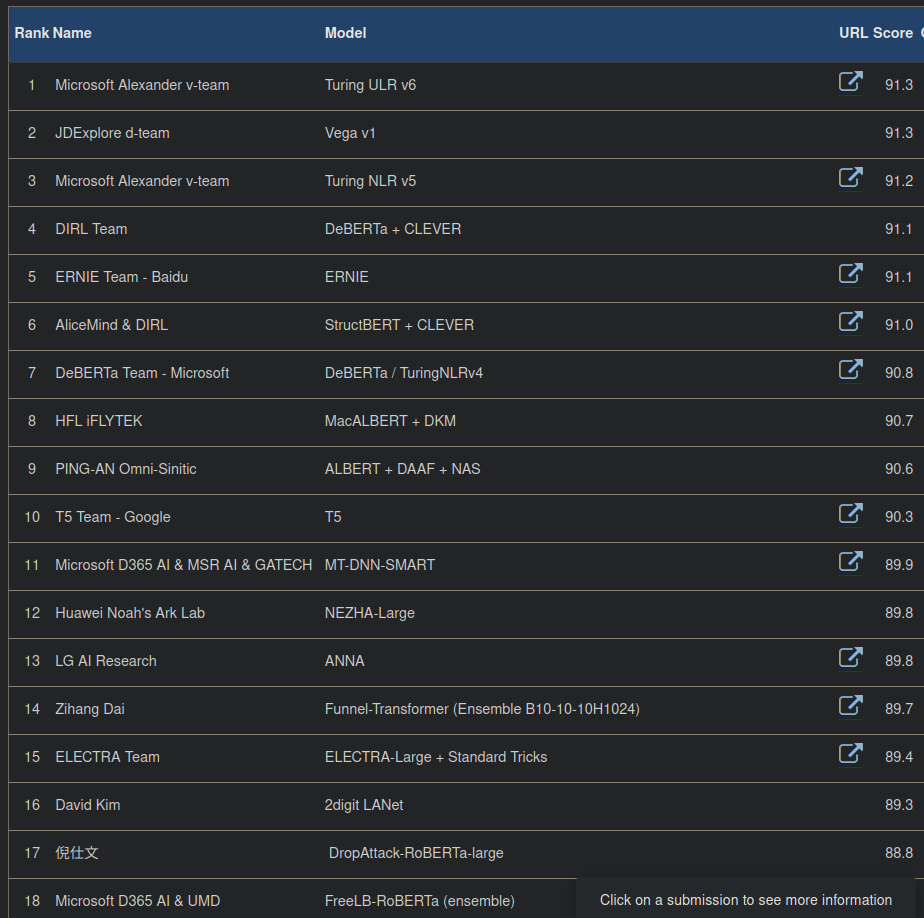

### SuperGLUE

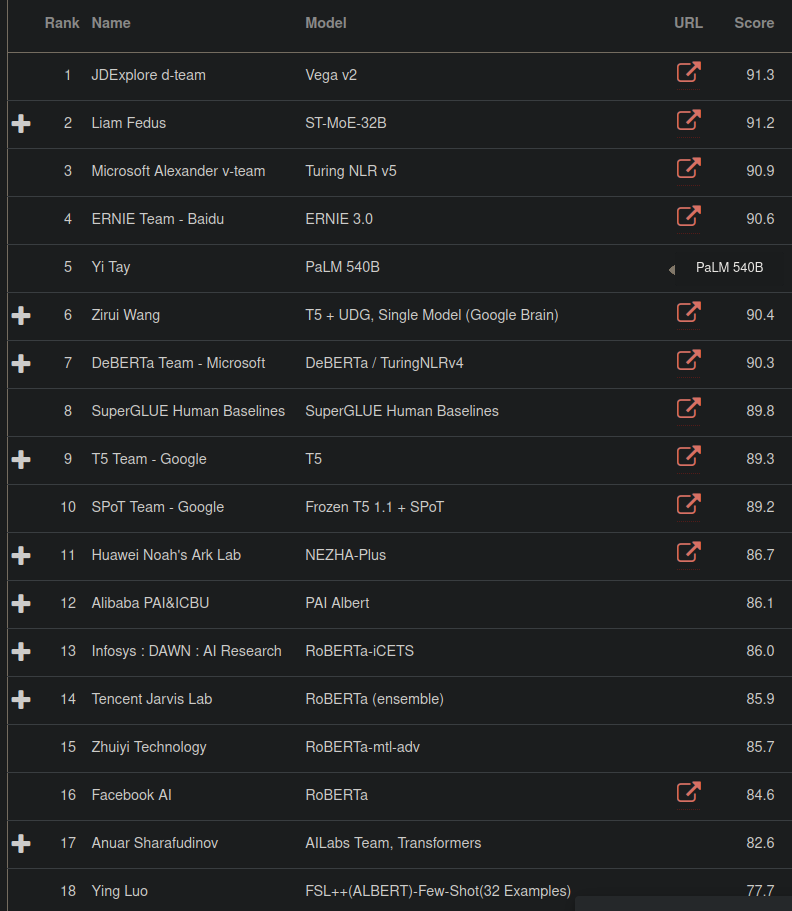

# Transformers: conclusion

- transformer - original non-recurrent architechture
- almost all SOTAs are based on transformer architechture

Trends:
- train on huge text corpus
- transfer learning: pretrain on task with big data and cheap markup, then fine-tune model for specific task
- simplify: decreasing number of parameters and layers
- for those who wants look at transformer more closely - code with explanation http://nlp.seas.harvard.edu/2018/04/03/attention.html

# Language Models

# ERNIE (Enhanced Representation through kNowledge IntEgration)

- WordPiece model
- Pretrained BERT is used
- tested for different tasks (natural language inference / semantic similarity / named entity recognition / sentiment analysis / question-answer matching)
- result is better than BERT
- more info here https://arxiv.org/abs/1904.09223

### Architechture

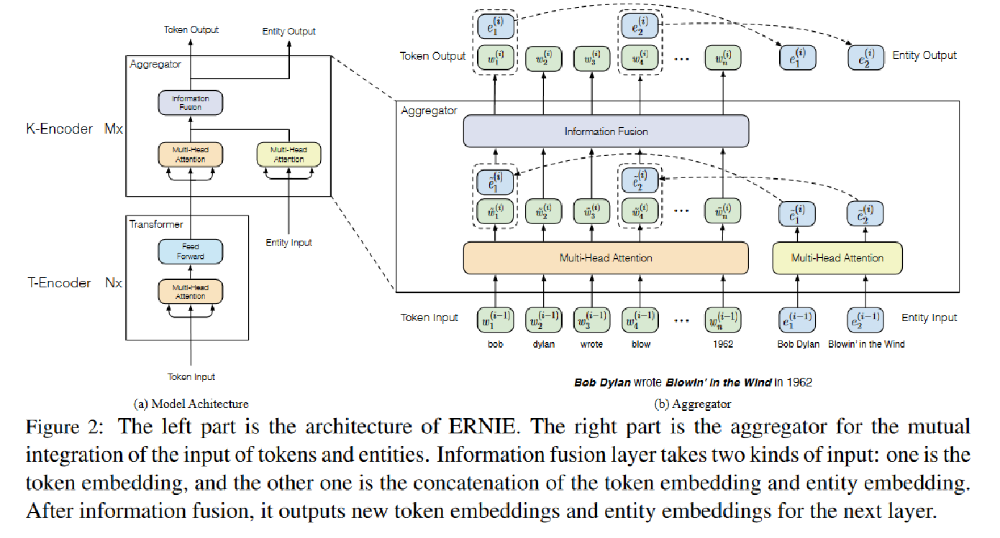

- use two encoders: T-endcoder and K-encoder 
- T-Encoder is a classic transformer encoder
- K-encoder uses 2 Multi-Head Attention modules: one for words and one for entities + fusion layer
- entitiy is an additional extra knowledge information that is used to make the model to "understand" text better

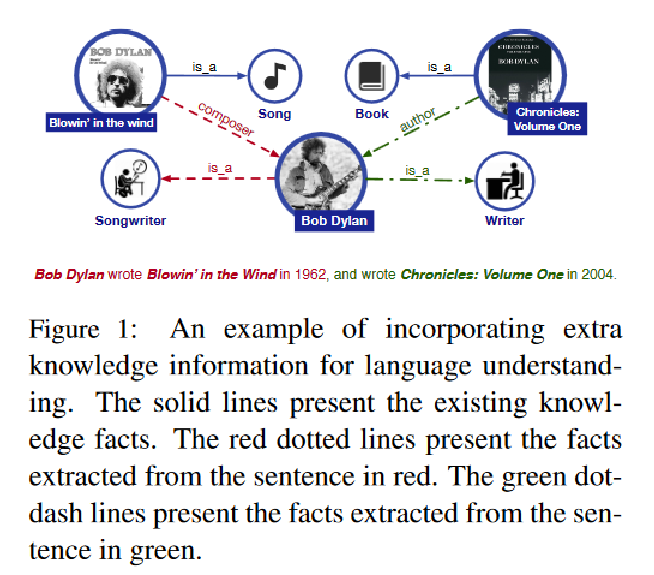

- fusion layer is used for mutual integration of the token and entitiy sequence

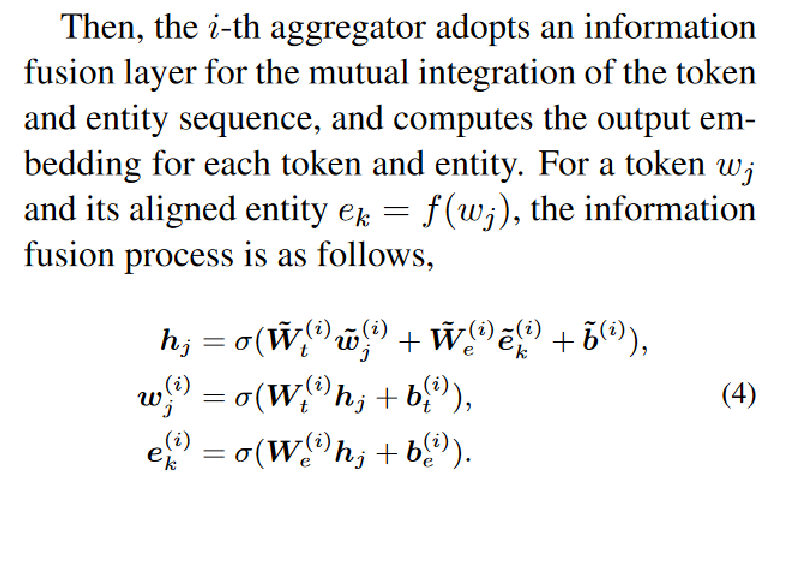

### Training

3 tasks:
- MLM (Masked Language Model)
- NSP (Next sentence prediction)
- Knowledge Pretraining Task (dEA) - randomly mask token-entity alignments and predict corresponding entity for a token from the entities in the sequence; need data with annotated entities (Wikipedia)

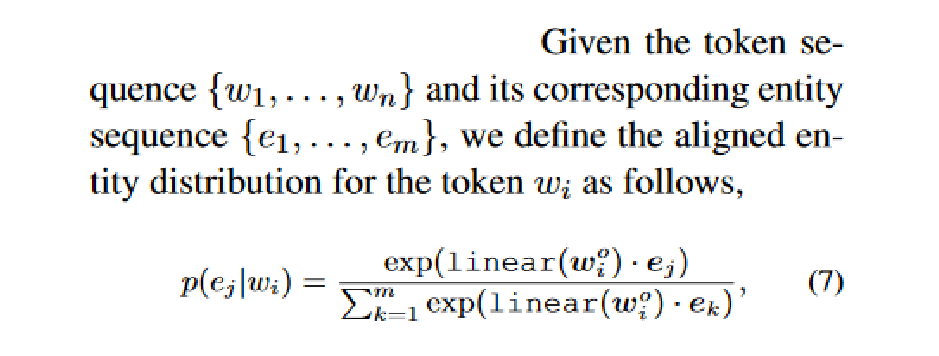

### Masking

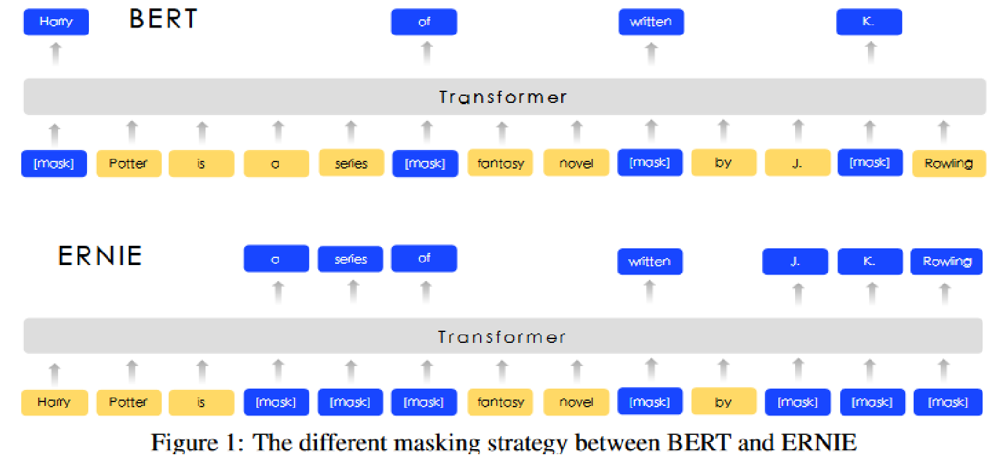

Knowledge masking: mask words on the first layer, entities (like J.K.Rowling, Eifel Tower, etc.) on the second and phrases on the third. That is used because model can easily restore entity/phrase if you mask only part of it, so it won't learn anything. So you should mask this entity/phrase completely.

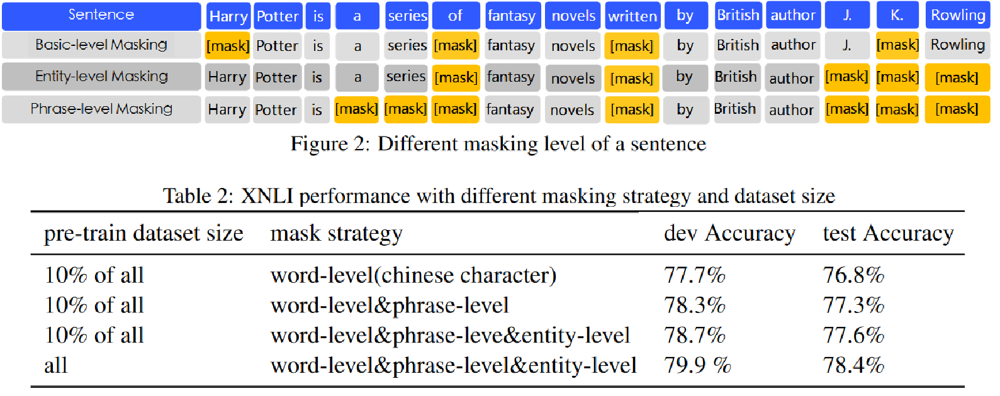

# GPT - Generative Pre-Training

- transformer-decoder, 12 layers, 12 heads
- unidirectional, masked self-attention
- predict next word
- BPE-encoding
- d=768 for token encoding
- GELU
- 100 epochs 
- 64 in the batch, 512 tokens
- supervised fine-tuning - 3 epochs

### Architechture

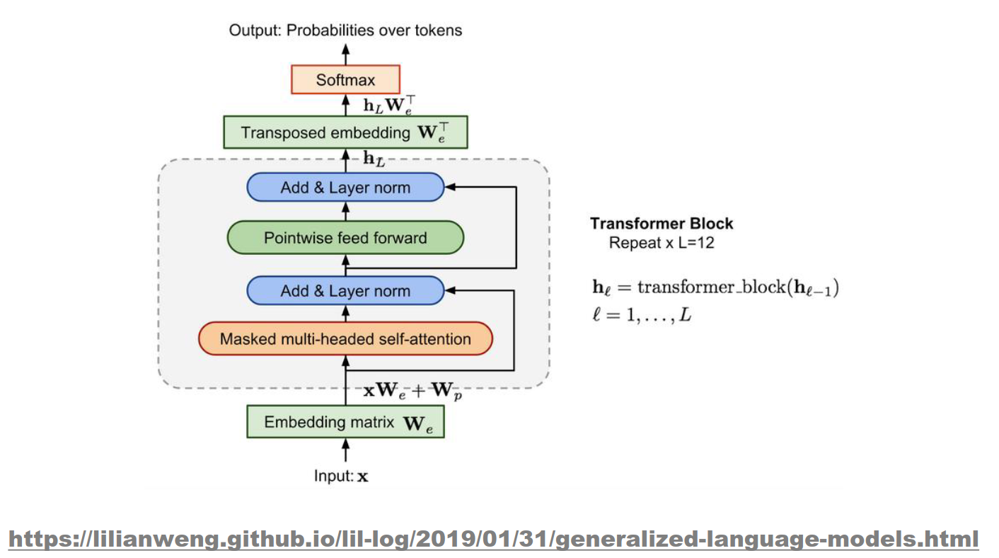

Transformer vs GPT vs BERT

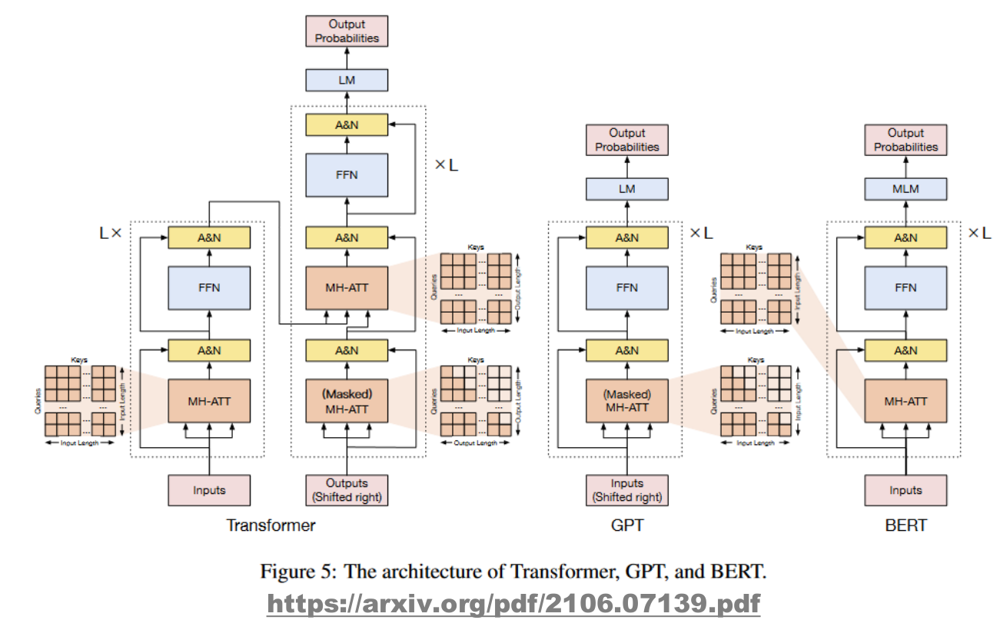

GPT - mutlitask archtechture. Any task doesn't require architechture changing. If task demands multiple sentences - they are separated with special token.

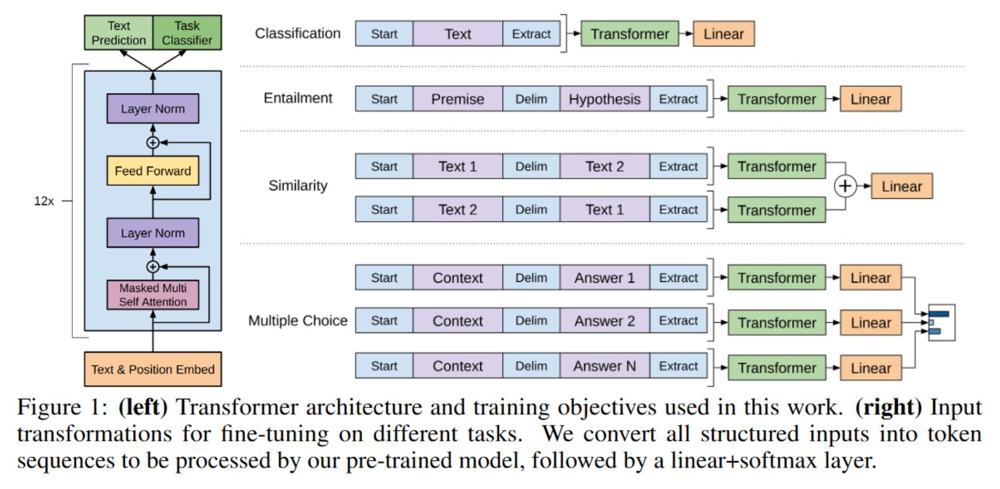

# GPT-2

- 1.5B parameters (10xGPT)
- training - new dataset "WebText" (1M of web-pages, 45M of links, 8M documents, links from Reddit with carma >= 3, don't use Wiki)
- text preprocessing (lower-case, tokenization, use out-of-vocabulary tokens, Unicode -> UTF-8)
- use BPE, but tokens are sequence of bytes, not symbols; also don't merge symbols of different type (like "dog" and "?")
- move layer norm after self-attention block
- different initialization
- vocabulary = 50K
- context size = 1024
- batch size = 512
- d = 1600
- SOTA in 7 tasks of 8 (zero-shot setting - no fine-tuning to task)
- up to 48 layers
- Multitask Learning as Question Answering (MQAN) (if queistion begins from "translate" - model should continue text with translation, if it begins from "answer the question" - model should continue text with question answering, etc.)
- MQAN lets task solving without supervised fine-tuning on specialized data!

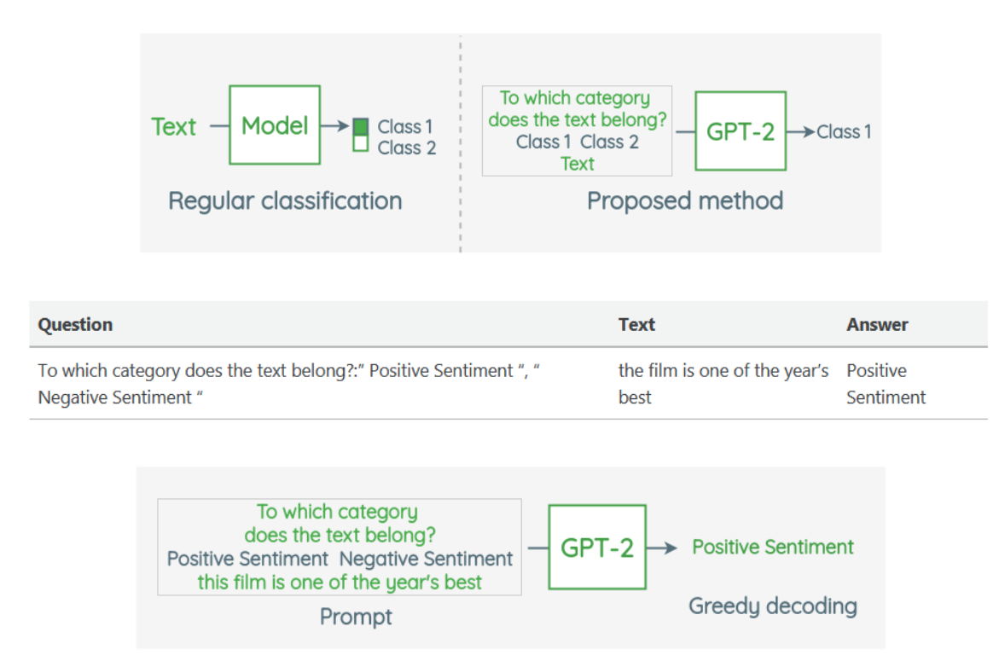

# GPT-3

- same architechture as GPT-2
- 96 layers / 96 heads
- d = 12888
- context window size = 2048
- 175B parameters (100xGPT-2)
- alternating dense and locally banded sparse attention patterns
- more data in training set
- no fine-tuning to any specific task
- can solve "on-the-fly" tasks - tasks which it wasn't trained for
- datasets:

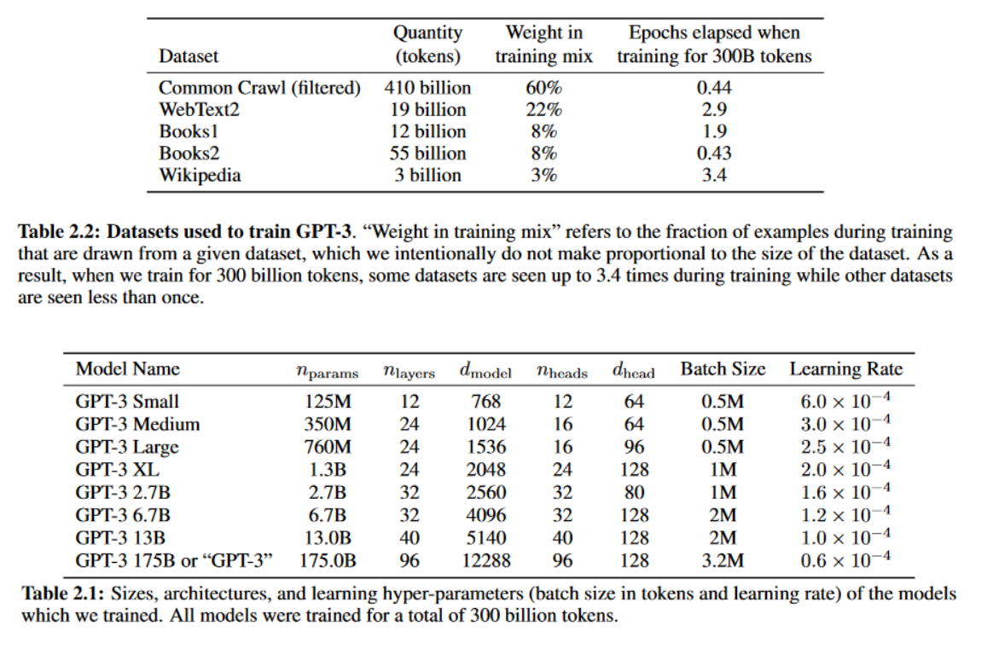

### Zero-shot vs one-shot vs few-shot vs fine-tuning

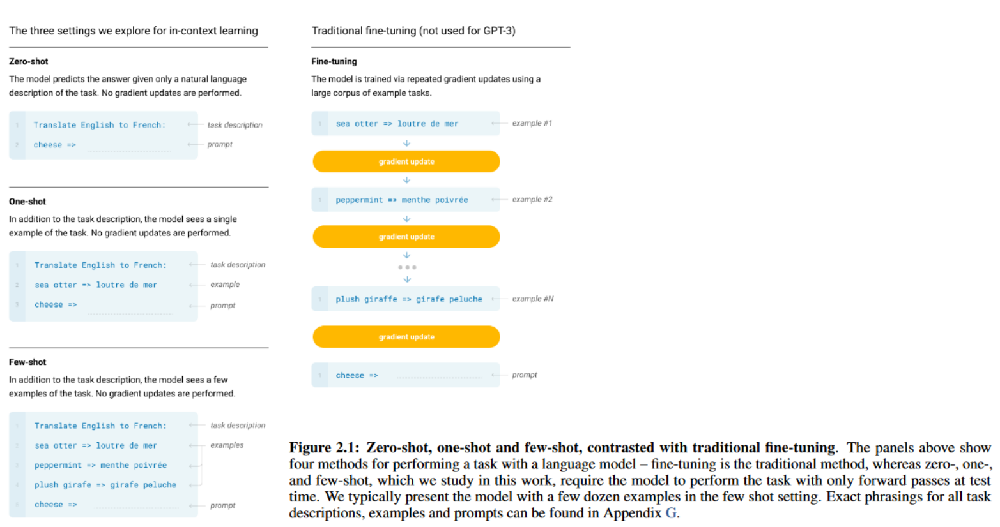

More info here https://arxiv.org/abs/2005.14165

# Language models benchmark

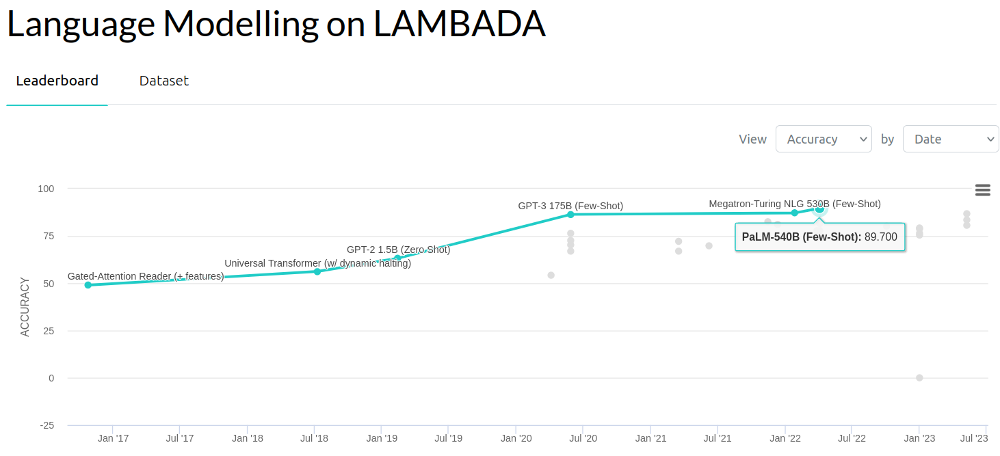

# Effective transformers

## Effective transformers: Transformer-XL

Main idea: sequence is divided to fragments of equal length, every fragment is processed at it's own time moment, every layer can watch to previous fragment (but gradient is calculated only for current fragment) => longer dependecies can be learned.

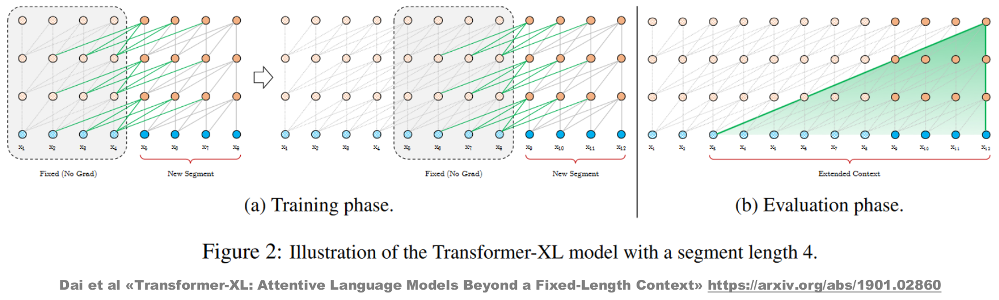

### Transformer-XL: Relative Position Representations

Relative Position Representation is used because long input can lead to appearance of a huge (and unknown to model) position codes. 

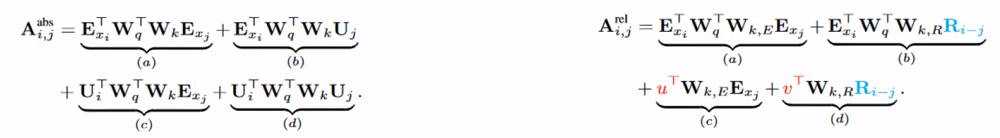

Left - Absolute Position Representation matrice formula

Right - Relative Position Representation matrice formula, trainable parameters are marked with red, relative representations are marked with blue.

## Effective transformers: Compressive transformer

Main idea: continuation of the Transformer-XL idea - process fragments of equal length, but when process 3 fragments - save them to the memory. Old memory triplets are compressed with the special compression function and saved to the compressed memory.

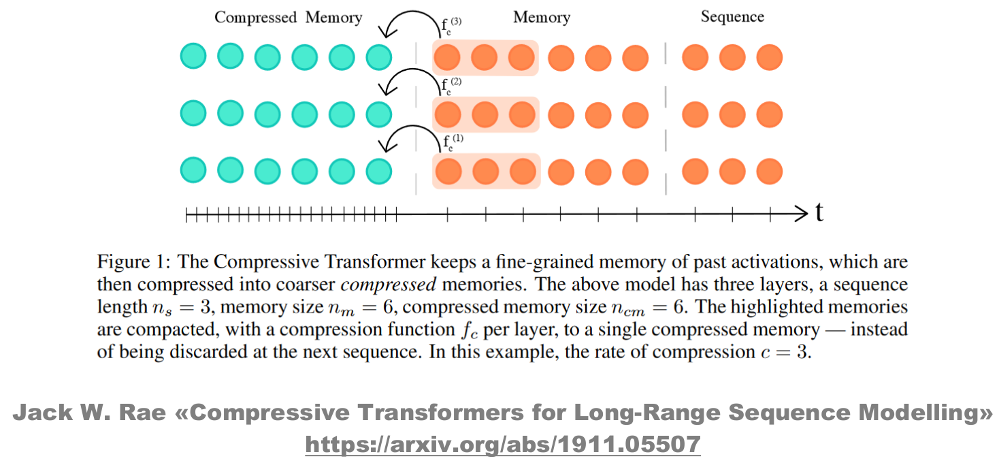

## Compressive transformer: result

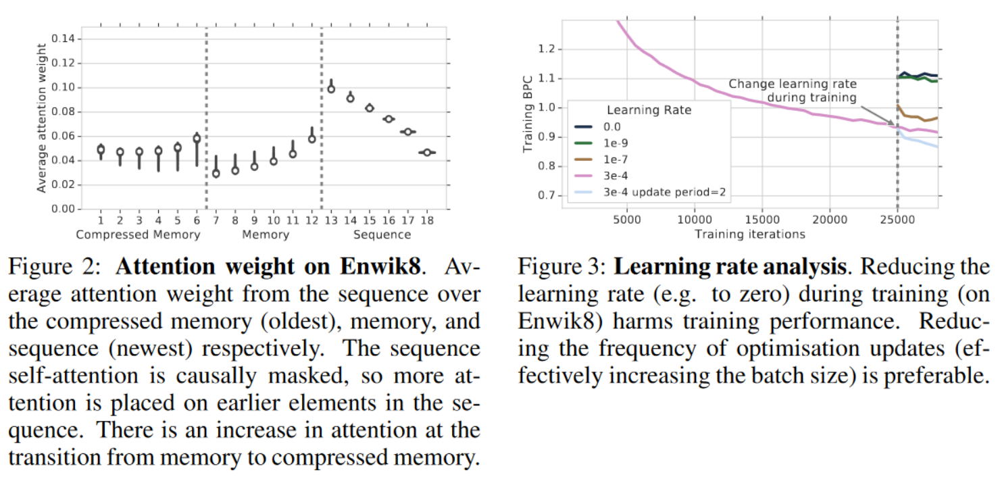

## Effective transformers: Adaptive Attention Span

Main idea: every transformer's head has it's own attention distribution and utilizes different number of previous tokens. So let's train every head to "pay attention" only to tokens that are important for it, not to all tokens in the sequence.

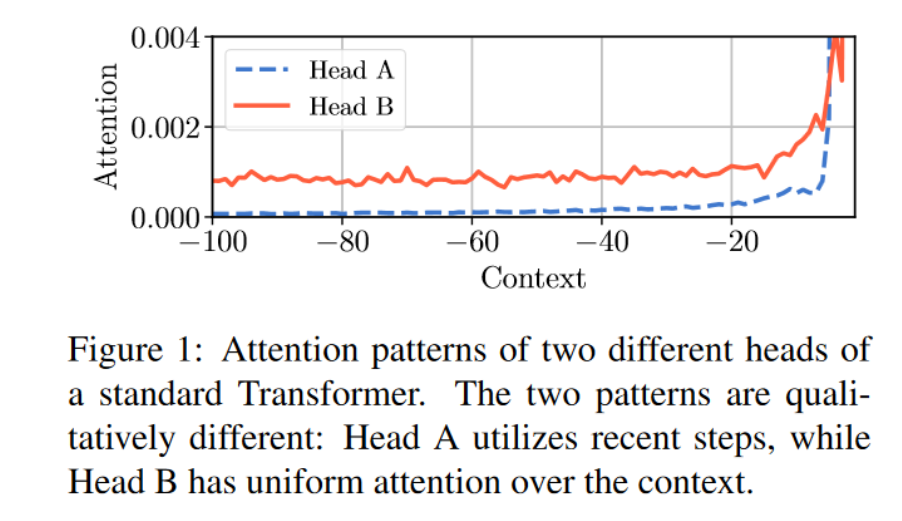

Use special soft-mask m<sub>z</sub>(x) that depends on distance as shown in the picture below (left).

Use new attention formula (picture below, right) with that mask.

Also add penalization to z value to make it as small as possible.

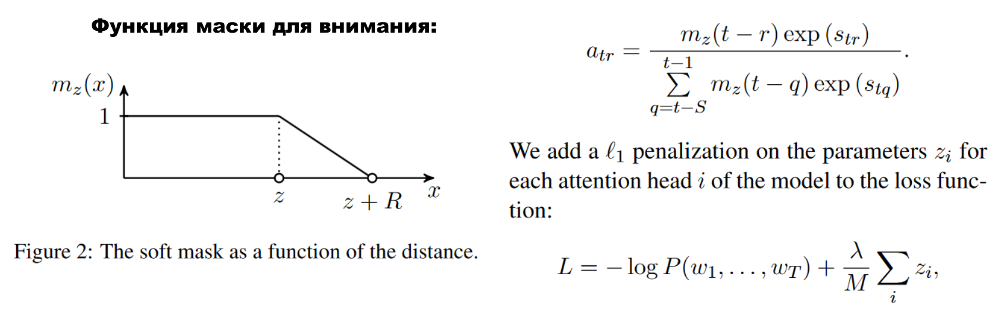

Adaptive Attention can be implemented in small NN - than it's Dynamic Attention Span.

### Adaptive Attention Span: result

Average span and #FLOPS decreases significantly + test results are better.

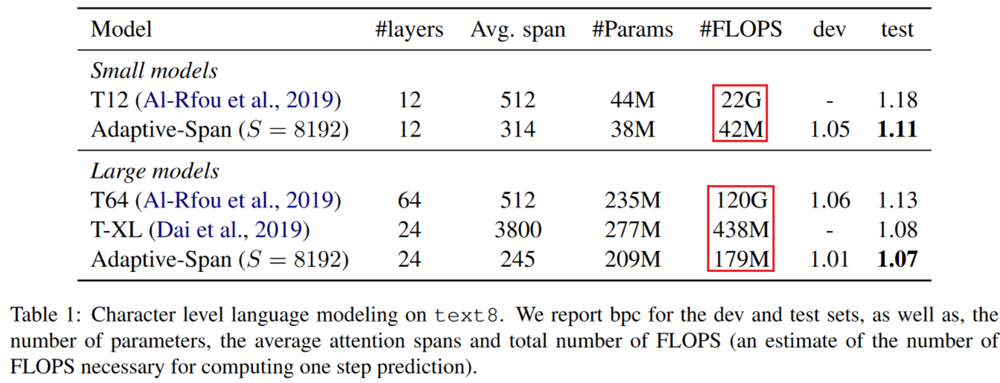

### Adaptive Attention Span vs Layers

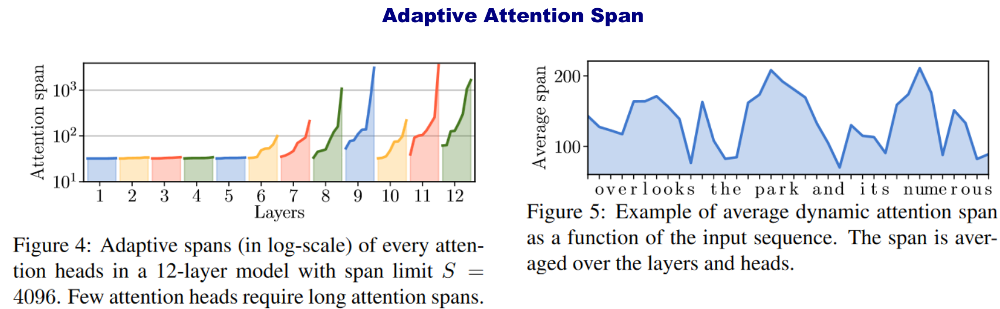

Only a few heads need a huge attention span

## Effective transformers: Expire-Span Transformer (Evolution of Adaptive Attention Span)

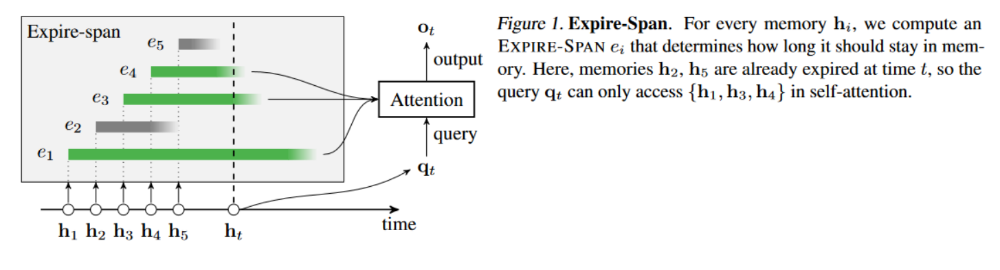

Main idea: for every token h<sub>i</sub> we compute value e<sub>i</sub> that determines how long it should stay in memory.

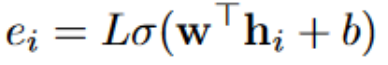

So, every token has it "expiration time" e<sub>i</sub> which is decreased by 1 every tact and when it reaches zero - attention mechanism "forgets" this token and calculate attention only for tokens which it doesn't "forget".

Mask function is the same as Adaptive Attention Span has.

e<sub>i</sub> is added to loss function to decrease average memory time

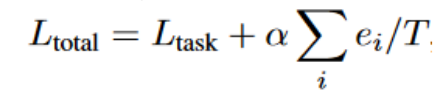

This technique is used independently in each layer: one layer can "forget" token but another still "remembers".

Also regularization is used: for every batch value *l* (0 to L) is randomly selected and attention for all tokens that are located farther than l from current token is sets to zero. That's the way to tell the model not to "pay attention" to very far located tokens and prevent overfit.

### Expire-Span Transformer: result

Names, countries, places are memorized well, common words do not memorized. Each layer sees at different text parts (names, spaces, headers)

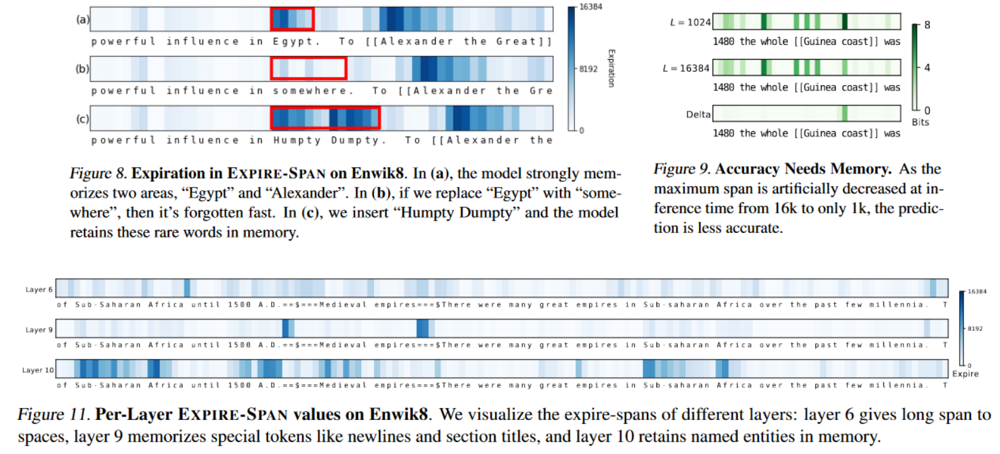

## Effective transformers: Memory transformer

Main idea: add special [mem] tokens to input sequence. When model reaches [mem] token, it saves some of surronding token representation to memory. Then attention mechanism can access to this memory.

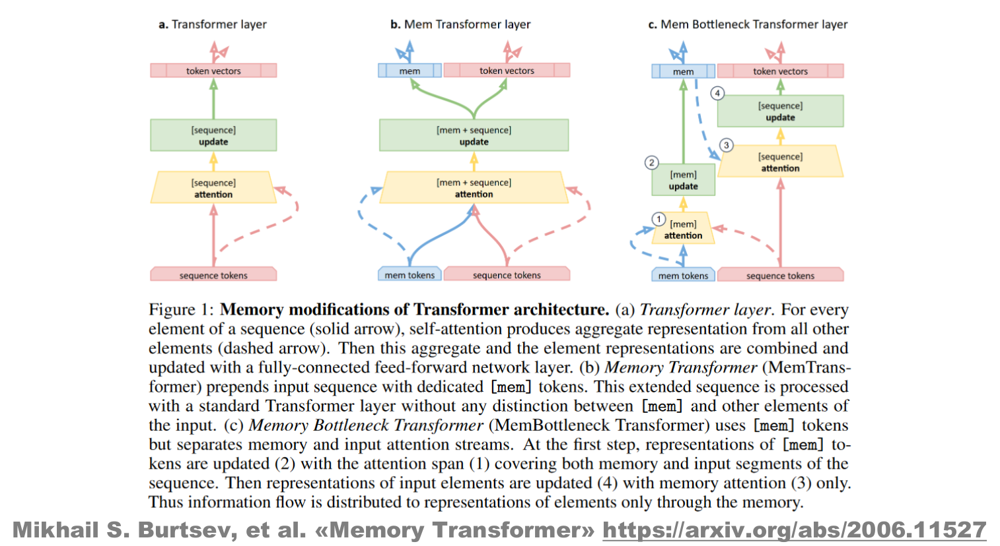

Can interpretate what's happening with text (write to memory, store, copy, fuse neighbour representations, etc.)

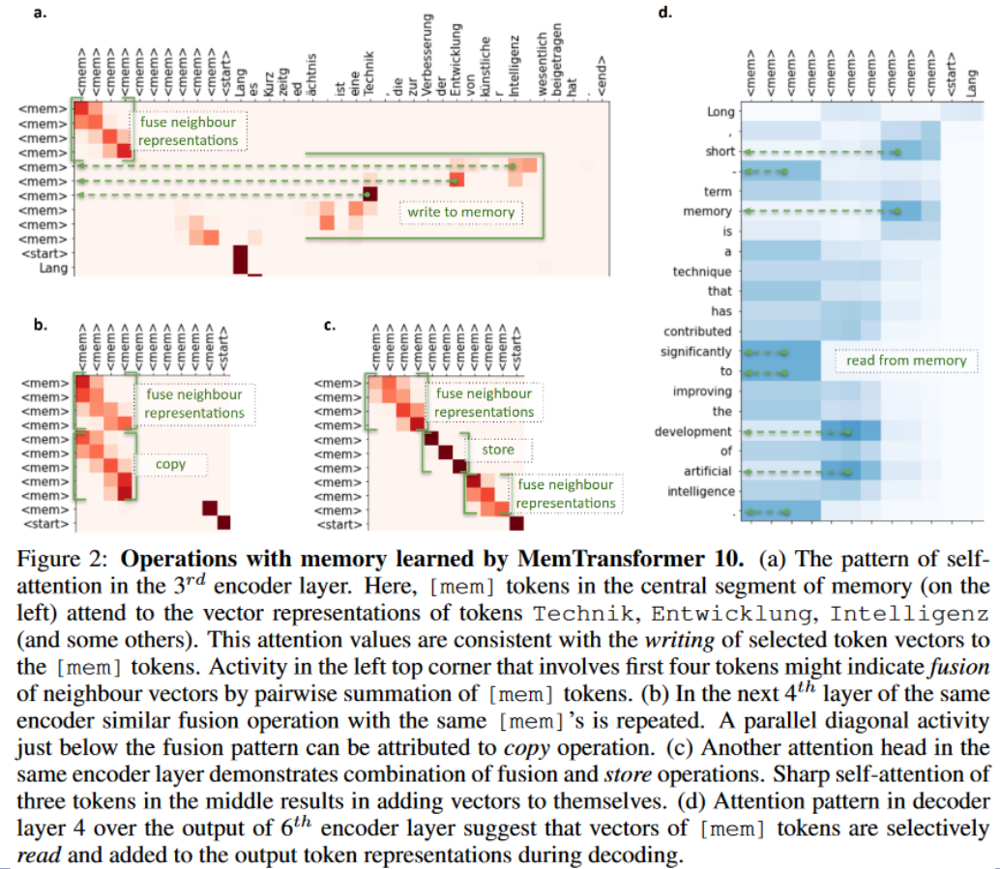

## Effective transformers: Extended Transformer Constructions (ETC)

Set of mechanisms to scale atteniton to long inputs.

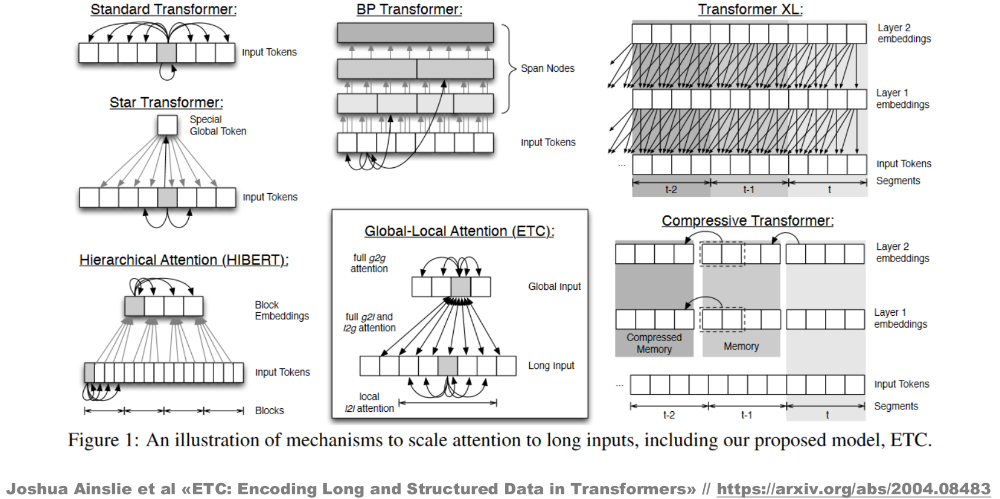

- Star Transformer: attention can see only tokens that are adjacent to current and can access another tokens only through Special Global token

- BP Transformer: tree-like structure where each token looks only at itself and tree nodes of higher levels

- Hierarchial Attention: input tokens are combined in special Block Embeddings and each token looks only at itself and at it's Block Embedding

- Global-Local Attention: Input is divided to global and local. Each local token looks at tokens in the boundaries of it's window and at it's global token. Each global token can look everywhere. Has problem with masked attention: can't forbid global tokens to look in the future.

- Transformer XL and Compressive Transformer: look above

## Effective transformers: Longformer (The Long-Document Transformer)

Main idea: local sliding window attention + dilated sliding window + global attention for pre-selected positions (always look at special tokens like [CLS] in classification tasks or question tokens in QA tasks).

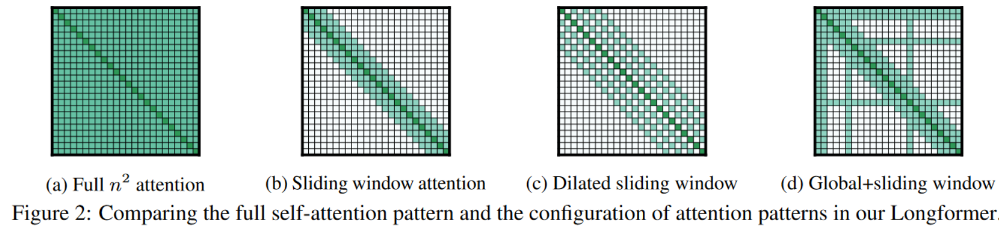

### Longformer: Results

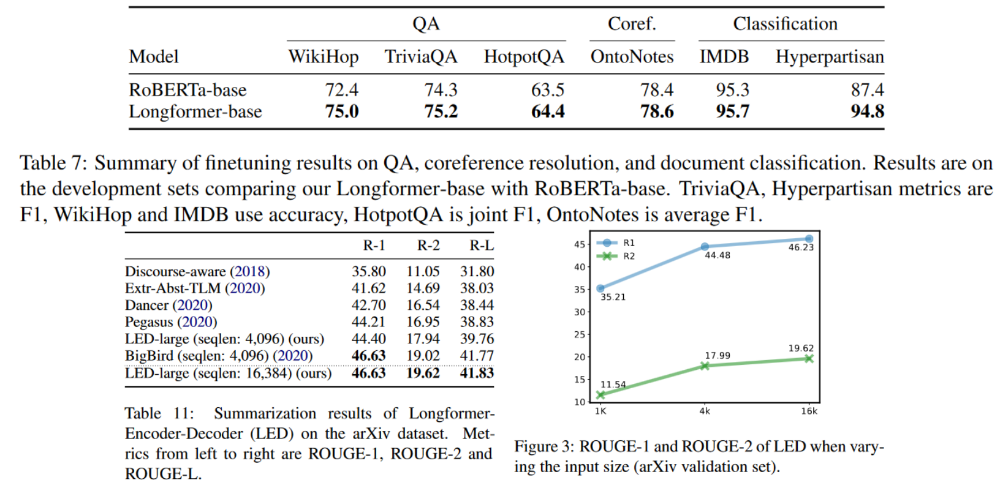

## Effective transformers: BigBird

Main idea: local sliding window attention + global tokens + random attention. Classic attention is full graph and it can be approximated by random (need local connections + short path between every vertex pair) and also this graph will be sparse enough (IRL illustration - theory of six hadshakes). This attention mechanism has complexity ~ O(n)

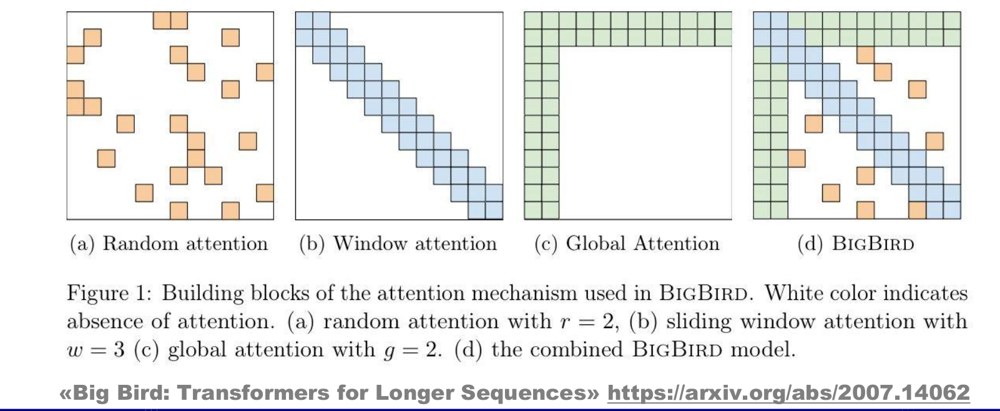

### BigBird: results

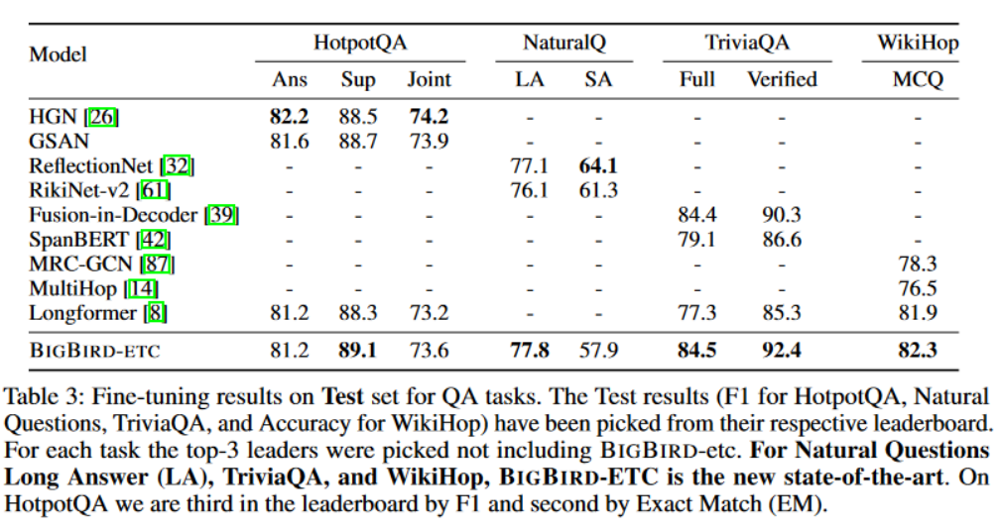

## Effective transformers: Sparse Transformer

It's a really working technique, it's currently (2025-2026) used in many modern models.

Is used to draw the second part of the picture when first part is known. Attention part is marked with white. 

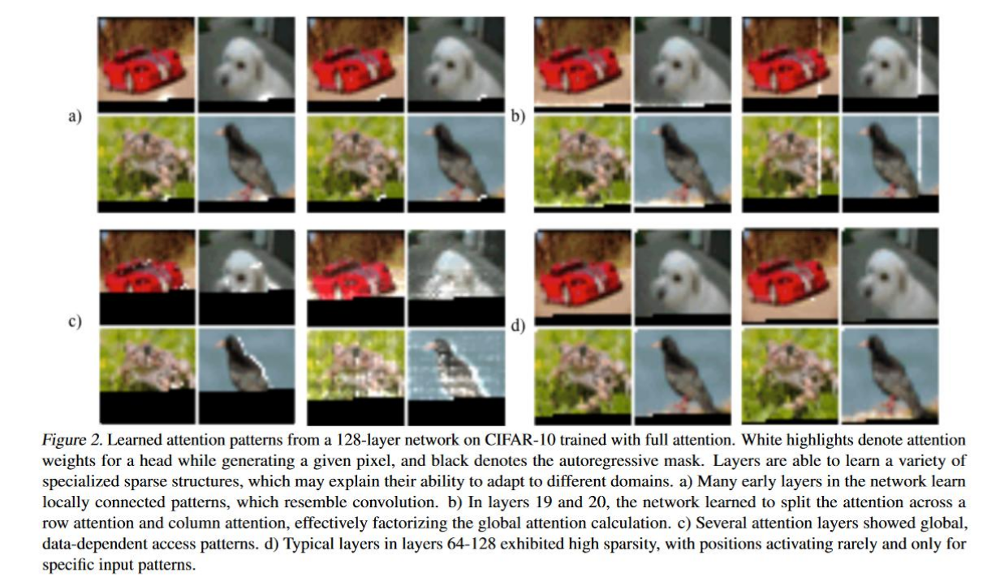

Main idea: we don't need the all attention matrix, so let's use only specific part of it in heads. That trick leads to decreasing of attention complexity from O(N<sup>2</sup>) to O(N*sqrt(N)).

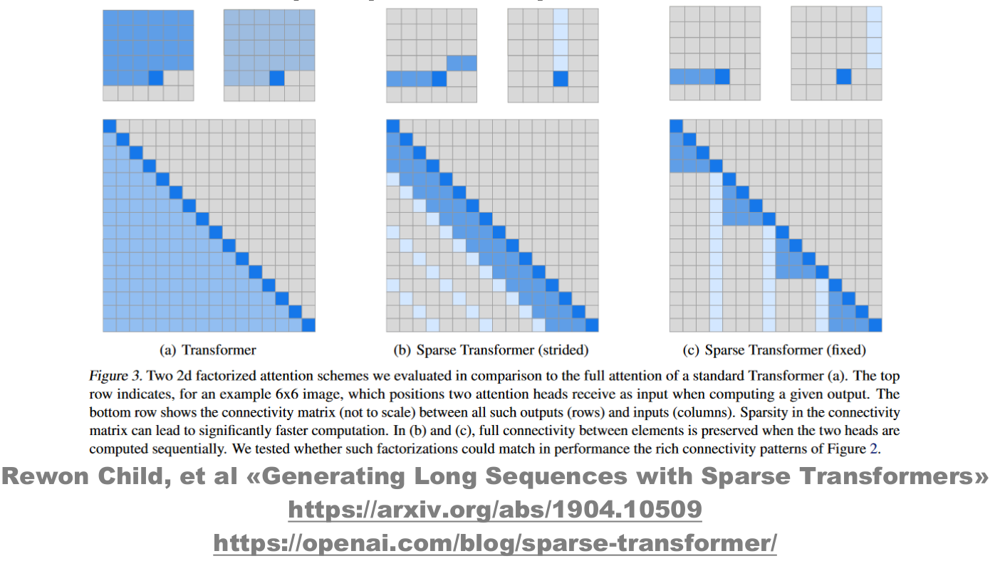

## Effective transformers: Reformer

Main idea: attention result is determined by tokens with big weights, so let's search for nearest neighbours (Locality-Sensitive Hashing is used) for each token and calculate attention only for them. Attention complexity is decreased to O(N*log(N)). Also Reversible Residual Layers are used.

### Reformer: LSH method
Project points on sphere, divide this sphere to zones, randomly rotate this spherical projections couple of times and for every point projection write down zone where it appeared. For the close points probability of appearance in the same zone is high, so their hashes will be close to each other.

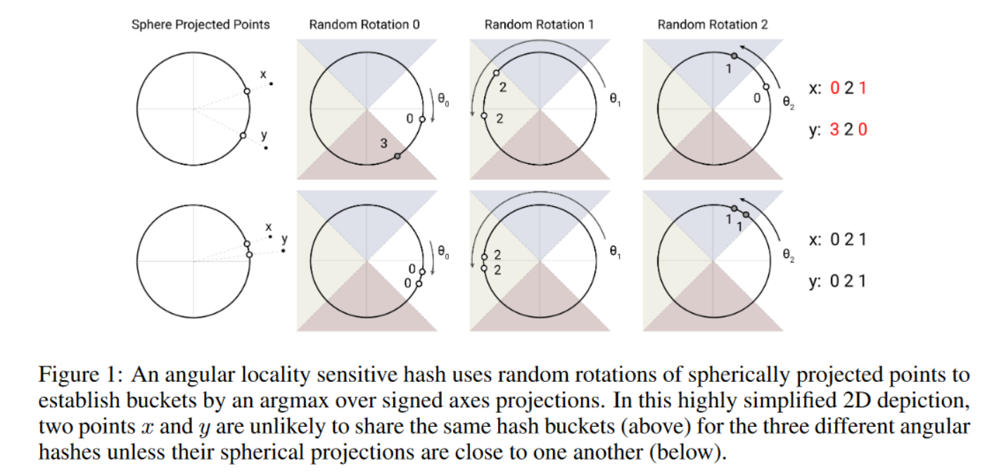

Hash-function

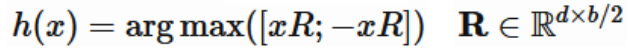

After calculation LSH for every point:

- distribute tokens in buckets
- sort buckets and tokens inside every bucket
- divide buckets in chunks (for parallelization)
- attention works only within same bucket 

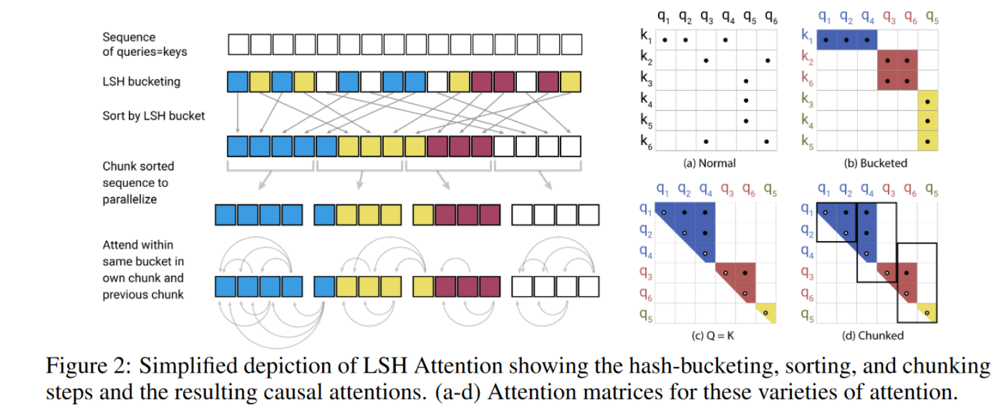

### Reformer: Reversible Residual Layers

Store activations only one time, not L (number of layers) times. During backpropagation they are calculating again.

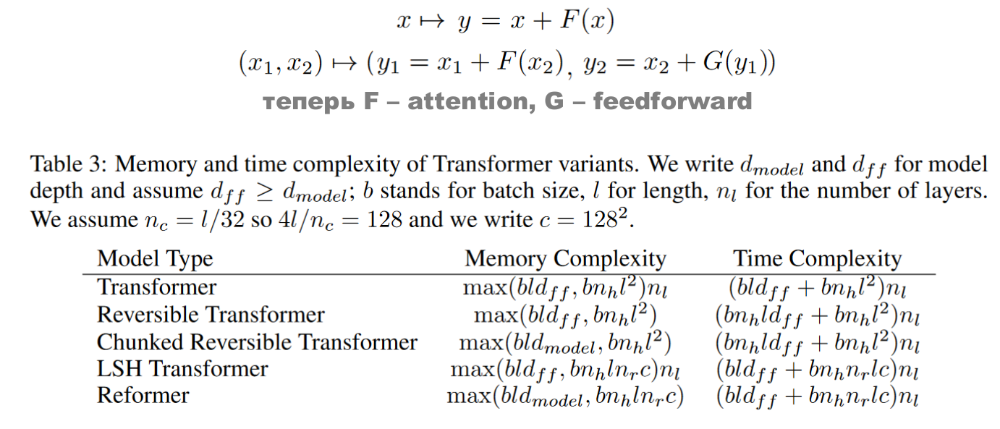

## Effective transformers: Routing Transformer

Main idea: routing attention - clusterize query and key spaces. 

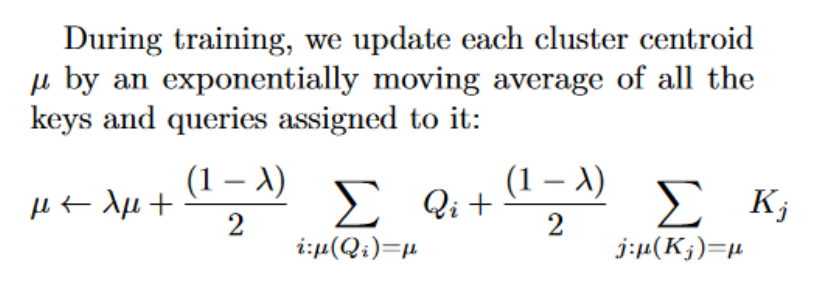

Calculate attention only with tokens from corresponding cluster.

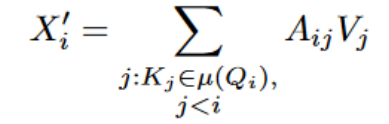

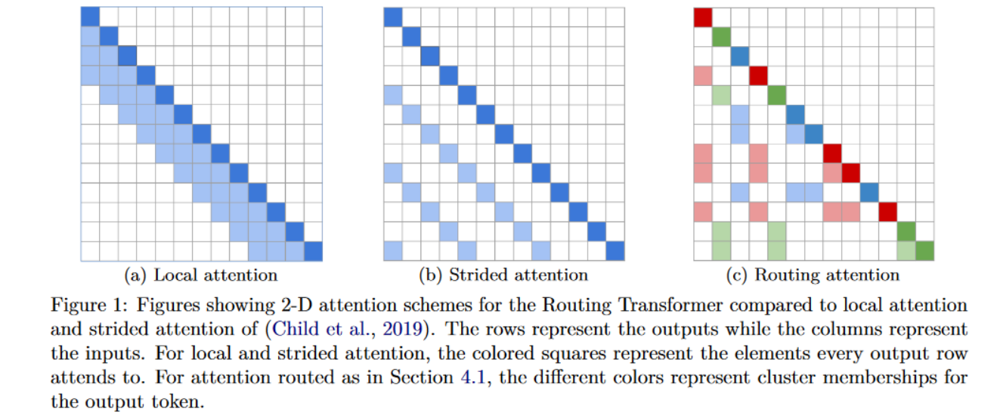

## Effective transformers: Linear Transformer

This one has the strongest line to current production models, though not in its original 2020 form

Main idea: attention has linear, not quadratic complexity; use kernel trick to rewrite self-attenition similarity formula:

Base self-attenition similarity formula:

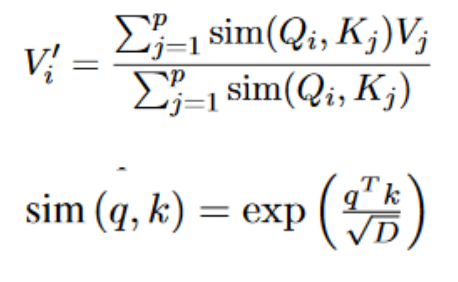

Rewrite kernel as

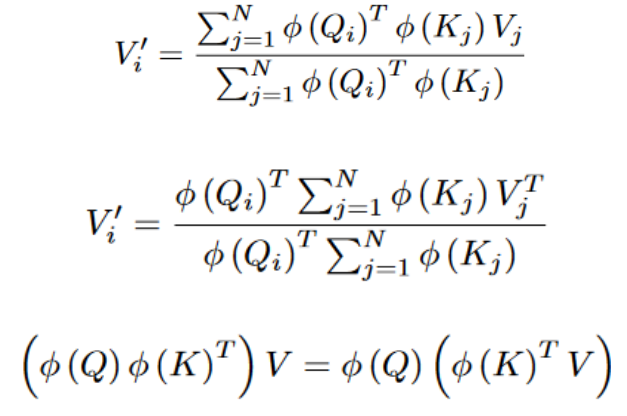

Where $\phi$ is a kernel that converts query/key space to new space and calculates similarity in this new space.

Expressions

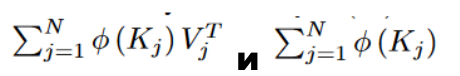

can be calculated once and used for each query (they don't depend on i) => complexity will be O(N), not O(N<sup>2</sup>)

Now transformer is similar to RNN

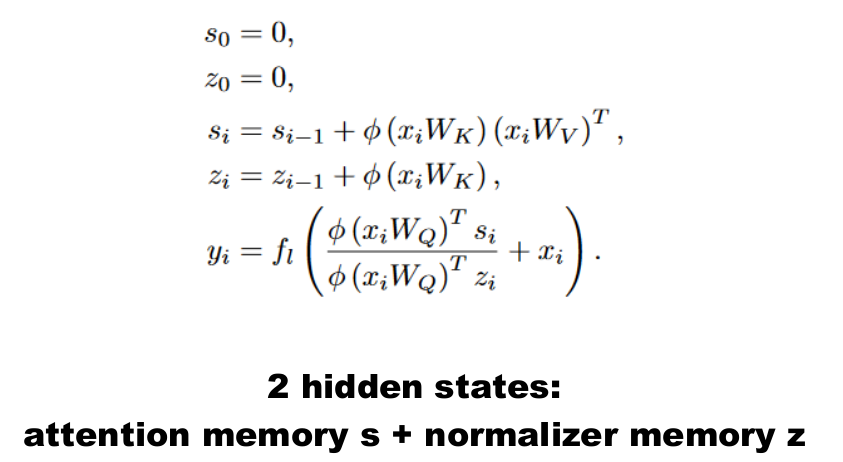

### Effective transformers: Linformer

Main idea: attention matrix has small rank => it can be factorized to smaller matrices production

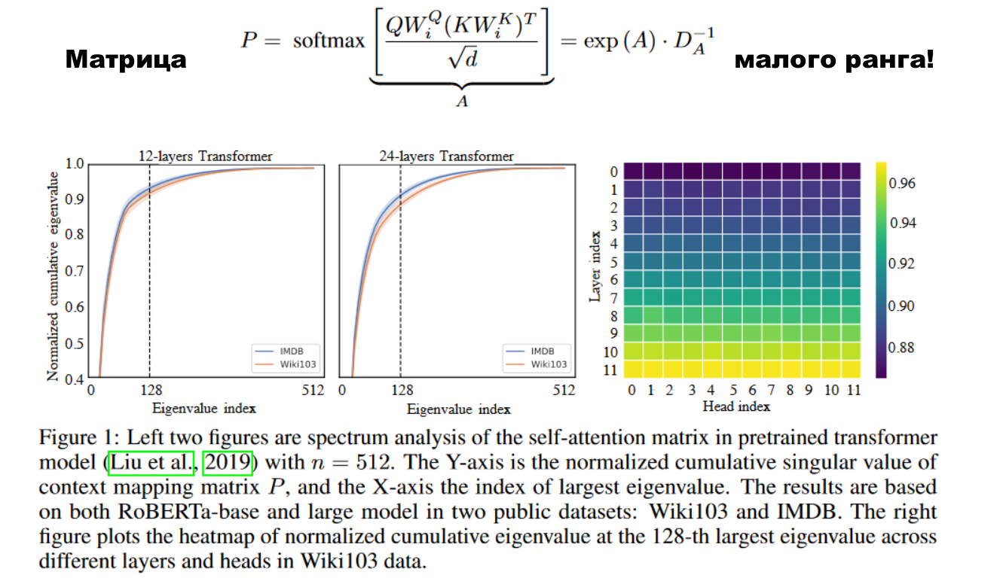

V and K can is projected from n x d to k x d<sub>v</sub> / k x d<sub>k</sub> using linear transformation => dimensiality n disappears from matrix => Attention complexity is not O(N<sup>2</sup>) anymore

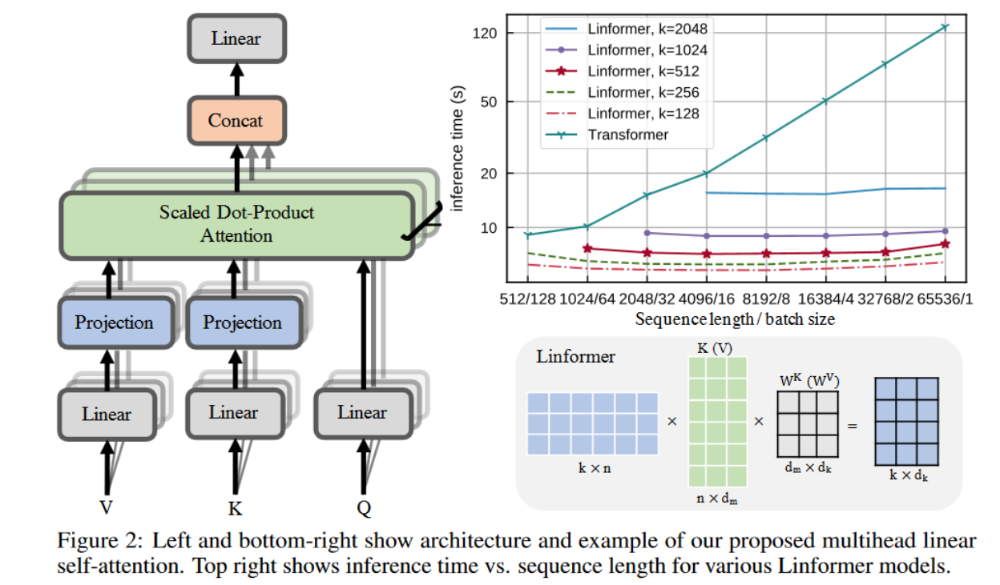

### Effective transformers: Performer

Main idea: decrease attention complexity with factorization of attention matrix and different matrices production order.

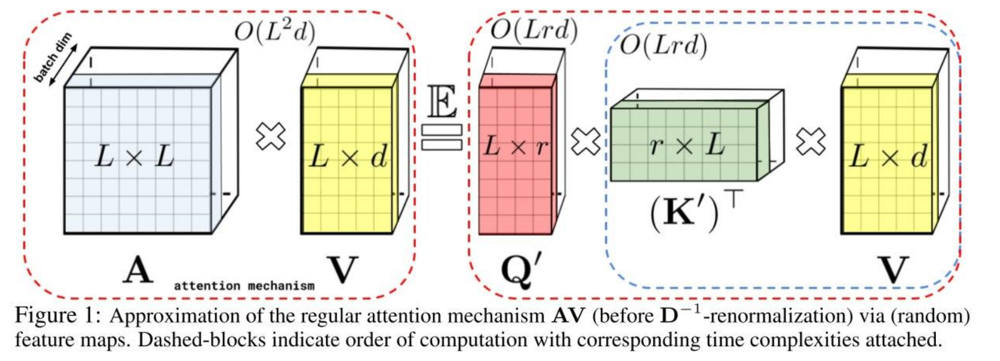

### Performer: Fast Attention via Orthogonal Random Features (FAVOR++)

A little math here, idea is similar to linear transformer - use kernels, build kernel for softmax

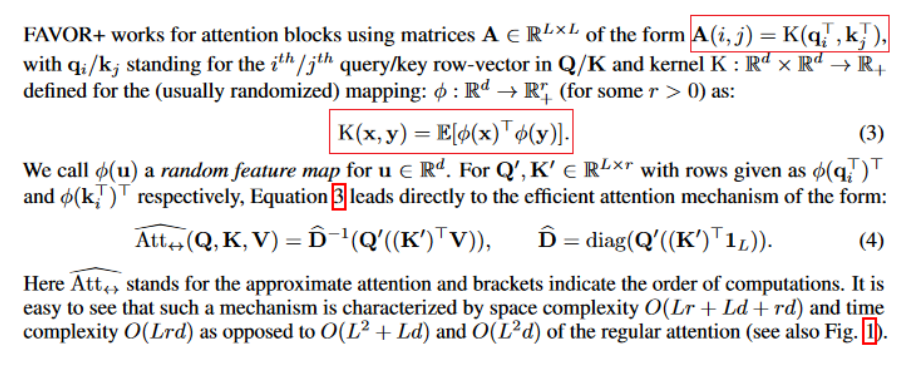

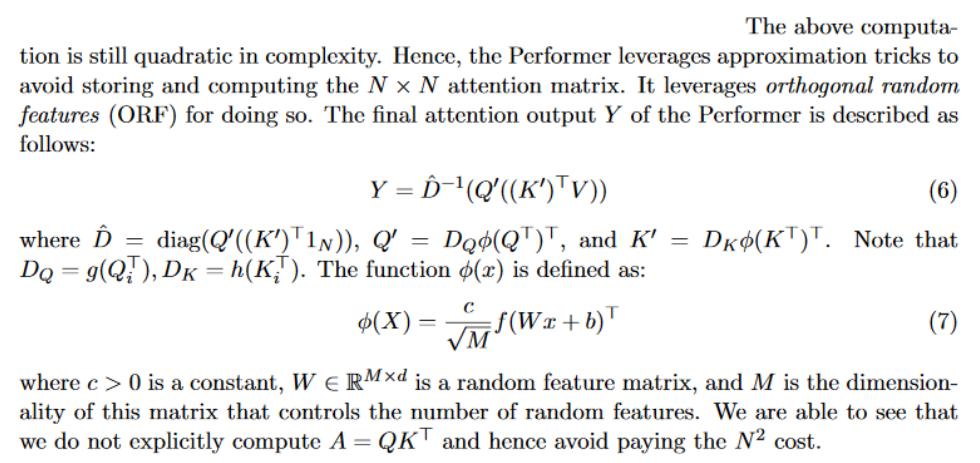

### Performer: result

Works as fast like it doesn't use any attention at all. Black line - maximal possible memory compression and speed up with dummy attention block used.

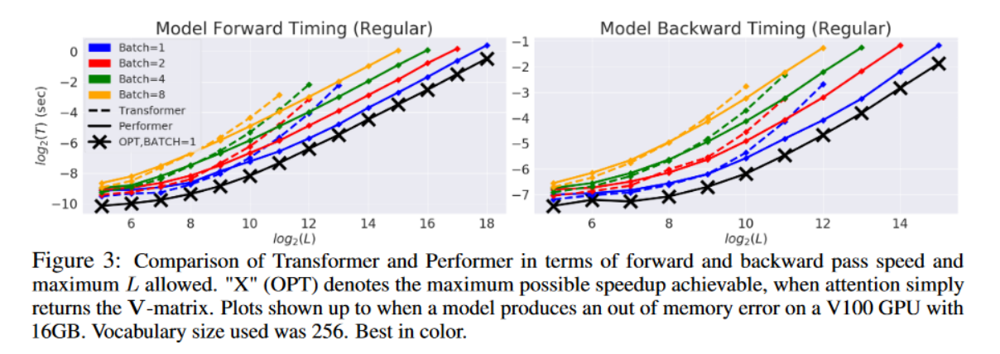

### Effective transformers: history

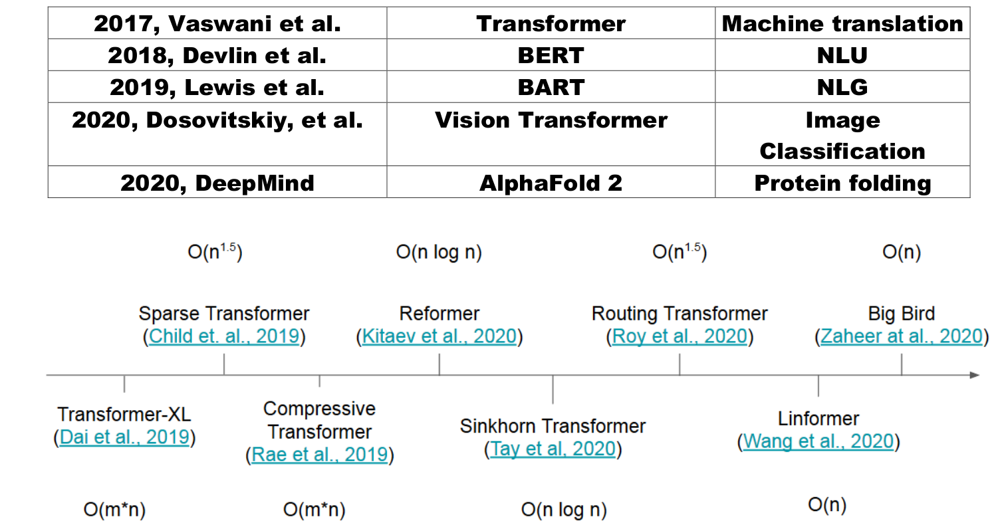

### Effective transformers: benchmarks

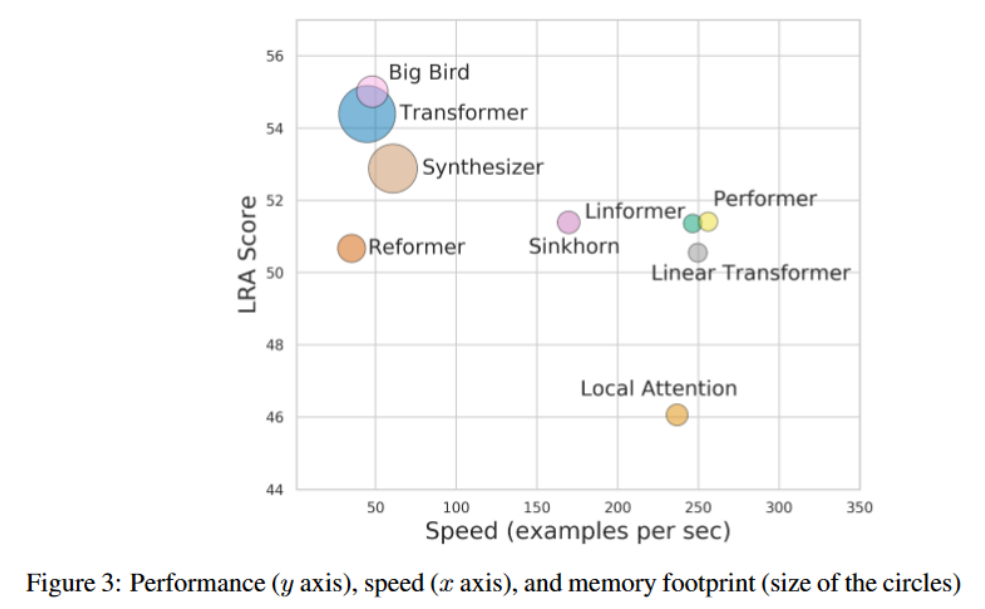

# What to read next

- Natural Language Processing with Deep Learning // http://web.stanford.edu/class/cs224n/
- Deconding Strategies Review // https://lilianweng.github.io/lil-log/2021/01/02/controllable-neural-text-generation.html
- Efficient Transformers: A Survey // https://arxiv.org/pdf/2009.06732.pdf
- Long Range Arena: A Benchmark for Efficient Transformers // https://arxiv.org/abs/2011.04006